# Elektrikoormuse prognooside parandamine
Vali projekti **.venv** kernel ja käivita **Restart Kernel → Run All**. Analüüs, tabelid ja graafikud jäävad siia notebooki. Eraldi tulemusfaile ei looda.

Baasmudel ennustab järgmise tunni koormust. Teine mudel ennustab baasprognoosi viga ja lisab selle paranduseks. Seejärel võrdleme kahte lisareeglit: varasemate sama kellaaja vigade parandus ja SHAP-osade kaalumine nende varasema kasu järgi.

**Uurimisküsimused**
1. Kas XAI-põhine parandus on täpsem kui lihtsamad parandusmeetodid?
2. Kuidas mõjutab XAI-meetodi valik prognoositäpsust ja arvutusaega?

Võrdleme TreeSHAP-i, LIME-i ja tunnuserühmade asendamist sama mudeli ja kaalureegliga. Vaatame ka kiireid koormuse tõuse ja langusi, kahjulikke parandusi ning naiivset prognoosi.

Seaded valime Panama 2018–2019 andmetel ja kasutame neid Eestis muutmata. Panama 2020 ja Eesti 2024 tulemusi oleme varem uurinud, seega on nende võrdlus tagasivaateline. Mudelid treenime kummagi riigi enda varasematel andmetel.

Lisakatses saab XAI-prognoos veel sama kellaaja varasematel vigadel põhineva paranduse. Sama lisakihi saab ka ilma XAI-ta kontroll. Selle katse plaan fikseeriti enne Eesti 2025 tulemuste vaatamist.

**Katse piirid.** Kasutame ajaloolisi lõppandmeid. Koormuse kohene saabumine on eeldus ning Panama ilma 24 tunni nihe ei vasta MERRA-2 tegelikule avaldamisviivitusele. Järgmine peatükk selgitab neid piiranguid. Katse ei tõenda veel reaalajas kasutamise valmisolekut.


In [1]:
from pathlib import Path
from copy import deepcopy
import sys

sys.dont_write_bytecode = True
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/experiment.json").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

from src.common import read_config
from src.data_preprocessing import load_and_audit, validate_for_modeling
from src.feature_engineering import (
    ERROR_FEATURES, build_features, feature_columns, known_error_features,
    load_dataset, split_year,
)
from src.models import residual_forecasts
from src.simple_correction import combined_forecasts
from src.xai_comparison import EXPLAINERS, compare_explainers, explain_components
from src.study import annual_forecast, oof_history, develop, policy_forecasts, validate_config
from src.compare_forecasting_models import compare_models
from src.evaluation import (clock_loss_interval, scope_masks, score_forecasts,
                            persistence_forecast, correction_diagnostics, prediction_metrics)
from src.correction import adaptive_correction

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:.4f}".format

C:\Users\danyi\Desktop\TALTECH magister\Magistritöö\xai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
cfg = read_config()  # Olemasolev configs/experiment.json; notebook ei muuda seda.
validate_config(cfg)
DATASETS = ("panama", "estonia")
METHODS = ("naive", "base", "residual", "hourly_bias", "credit_feedback")
LABELS = {"base": "Baas", "residual": "Jääkparandus",
          "hourly_bias": "Lihtne", "credit_feedback": "XAI"}
BASELINES = ("naive", "base", "direct", "residual", "fixed", "scalar_adaptive",
             "standalone_feedback", "hourly_bias", "credit_feedback")
LABELS.update({"direct": "Otseprognoos", "fixed": "Püsikaal",
               "scalar_adaptive": "Üks adaptiivne kaal",
               "standalone_feedback": "Osad eraldi",
               "matched_scalar": "Üks krediidikaal",
               "matched_standalone": "Koosmõjuta", "no_context": "Kellaajata"})
COLORS = {"base": "#8b95a5", "residual": "#4c78a8",
          "hourly_bias": "#e58b2a", "credit_feedback": "#21918c"}
COUNTRIES = {"panama": "Panama", "estonia": "Eesti"}
EXAMPLE_OFFSET_DAYS = 7  # Ajagraafiku algus: seitse päeva pärast hindamise algust.
EXAMPLE_DAYS = 3

display(pd.DataFrame([
    {"Andmestik": COUNTRIES[d], "Arendusaastad": str(cfg["datasets"][d]["development_years"]),
     "Hindamisaasta": cfg["datasets"][d]["test_year"]}
    for d in DATASETS
]))
print("Baasmudel:", cfg["base_model_family"], "| parandusmudel: HistGBR")
print("Külmkäivitus:", cfg["feedback"]["warmup_hours"], "h; vajalik ajalugu:",
      cfg["feedback"]["min_history_points"], "sama rühma vaatlust.")

XAI_OPTIONS = cfg["xai_comparison"]
XAI_LABELS = {"residual": "Jääkparandus", "hourly_bias": "Lihtne",
              "tree_shap": "TreeSHAP", "lime": "LIME", "feature_ablation": "Asendamine"}
XAI_COLORS = {"residual": COLORS["residual"], "hourly_bias": COLORS["hourly_bias"],
              "tree_shap": COLORS["credit_feedback"], "lime": "#a155b9", "feature_ablation": "#4779bd"}
XAI_PAIRS = (("lime", "tree_shap"), ("feature_ablation", "tree_shap"),
             ("feature_ablation", "lime"),
             *((method, "hourly_bias") for method in EXPLAINERS))

COMBINED_LABELS = {"base": "Baas", "residual": "Jääkparandus", "hourly_bias": "Lihtne",
                   "credit_feedback": "XAI", "matched_scalar": "Üks kaal",
                   "xai_bias": "XAI + veaparandus", "scalar_bias": "Üks kaal + veaparandus"}
COMBINED_PAIRS = (("xai_bias", "hourly_bias"), ("xai_bias", "scalar_bias"),
                  ("xai_bias", "credit_feedback"), ("scalar_bias", "matched_scalar"))
COMBINED_COLORS = {**COLORS, "matched_scalar": "#889642", "xai_bias": "#a155b9", "scalar_bias": "#4779bd"}

LABELS["naive"] = COMBINED_LABELS["naive"] = "Naiivne"
COLORS["naive"] = COMBINED_COLORS["naive"] = "#b06c49"
DIAGNOSTIC_OPTIONS = cfg["diagnostics"]
GROUP_LABELS = {"recent_load": "Hiljutine koormus", "seasonal_load": "Varasem koormusmuster",
                "clock": "Kellaaeg", "calendar": "Kalender", "weather": "Ilm",
                "dynamics": "Koormuse muutumine", "forecast_anchor": "Baasprognoos",
                "error_memory": "Varasemad vead", "offset": "Püsiosa (pole sisendtunnus)"}

# Graafikute nimetused on inglise keeles; tabelite omad jäävad eesti keelde.
PLOT_COUNTRIES = {'panama': 'Panama', 'estonia': 'Estonia'}
PLOT_TITLES = {key: f"{name} {cfg['datasets'][key]['test_year']}" for key, name in PLOT_COUNTRIES.items()}
PLOT_SCOPES = {'overall': 'All hours', 'rapid_increase': 'Rapid increase', 'rapid_decrease': 'Rapid decrease'}
PLOT_LABELS = {
    'naive': "Last hour's load", 'base': 'Base forecast', 'direct': 'Direct model',
    'residual': 'Base + correction', 'fixed': 'Fixed weight',
    'hourly_bias': 'Simple correction', 'credit_feedback': 'XAI correction',
    'scalar_adaptive': 'Adaptive weight', 'standalone_feedback': 'Separate credit',
    'matched_scalar': 'Single weight', 'matched_standalone': 'No interaction credit',
    'no_context': 'No hour grouping', 'mae_credit': 'Absolute-error credit',
    'recency_credit': 'Recent-weighted credit', 'tree_shap': 'TreeSHAP',
    'lime': 'LIME', 'feature_ablation': 'Group ablation',
    'xai_bias': 'XAI\n+ simple correction', 'scalar_bias': 'Single weight\n+ simple correction',
}
PLOT_GROUPS = {
    'recent_load': 'Recent load', 'seasonal_load': 'Seasonal load', 'clock': 'Hour',
    'calendar': 'Calendar', 'weather': 'Weather', 'dynamics': 'Load changes',
    'forecast_anchor': 'Base forecast', 'error_memory': 'Past errors', 'offset': 'Offset',
}
PLOT_COLORS = {
    'naive': '#9b765b', 'base': '#8995a5', 'direct': '#607185', 'residual': '#4c78a8',
    'hourly_bias': '#d58a27', 'credit_feedback': '#168a80', 'tree_shap': '#168a80',
    'lime': '#9754a8', 'feature_ablation': '#4779bd', 'matched_scalar': '#788437',
    'xai_bias': '#9754a8', 'scalar_bias': '#4779bd',
}
PLOT_STYLE = {
    'figure.dpi': 140, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.family': 'DejaVu Sans', 'font.size': 11, 'text.color': '#283747',
    'axes.titlesize': 13, 'axes.titleweight': 'normal', 'axes.titlepad': 15,
    'axes.labelsize': 11, 'axes.labelcolor': '#283747', 'axes.labelpad': 10,
    'axes.edgecolor': '#b4bec9', 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.labelsize': 10, 'ytick.labelsize': 11, 'xtick.color': '#536579',
    'ytick.color': '#283747', 'xtick.major.size': 0, 'ytick.major.size': 0,
    'legend.frameon': False, 'legend.fontsize': 10, 'grid.color': '#e8edf1',
    'grid.linewidth': 0.8, 'lines.linewidth': 1.8,
}

def plot_cohort(cohort):
    return cohort.replace('Eesti', 'Estonia')

def analysis_grid(ax, axis='x'):
    ax.grid(axis=axis, color='#e8edf1', linewidth=0.8)
    ax.set_axisbelow(True)

def analysis_barh(ax, labels, values, colors, digits=2):
    values = np.asarray(values, dtype=float)
    bars = ax.barh(labels, values, color=colors, height=0.58)
    ax.bar_label(bars, labels=[f'{value:.{digits}f}' for value in values], padding=6, fontsize=10)
    ax.invert_yaxis()
    ax.set_xlim(0, max(float(values.max()) * 1.24, 1e-9))
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', pad=9)
    analysis_grid(ax)
    return bars

def analysis_intervals(ax, values, labels, colors):
    if isinstance(colors, str):
        colors = [colors] * len(values)
    for position, (row, color) in enumerate(zip(values.itertuples(), colors)):
        ax.errorbar(row.difference, position,
            xerr=[[row.difference - row.adjusted_low], [row.adjusted_high - row.difference]],
            fmt='o', color=color, markersize=6, elinewidth=1.8, capsize=4, capthick=1.2)
    ax.axvline(0, color='#7c8998', linestyle=(0, (4, 4)), linewidth=1.1)
    ax.set_yticks(range(len(values)), labels)
    ax.set_ylim(len(values) - 0.45, -0.55)
    ax.spines['left'].set_visible(False)
    ax.tick_params(axis='y', pad=9)
    analysis_grid(ax)

def analysis_dates(ax, maxticks=6):
    from matplotlib.dates import AutoDateLocator, ConciseDateFormatter
    locator = AutoDateLocator(minticks=3, maxticks=maxticks)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(ConciseDateFormatter(locator))



,Andmestik,Arendusaastad,Hindamisaasta
0,Panama,"[2018, 2019]",2020
1,Eesti,[],2024


Baasmudel: histgbr | parandusmudel: HistGBR
Külmkäivitus: 72 h; vajalik ajalugu: 3 sama rühma vaatlust.


## 1. Andmeallikad ja kättesaadavus
Allikad kontrollitud 07.11.2026. **Varasema ajatempliga andmed ei pruukinud prognoosihetkel veel avalikud olla.** Kood kasutab mineviku koormusi ja vigu ning 24 tunni võrra nihutatud ilma. Andmete tegelik saabumisaeg vajab eraldi kontrolli.

- **Panama koormus.** [Andmete autor](https://data.mendeley.com/datasets/byx7sztj59/1) kasutas päevaseid CND järelraporteid ja Earthdata ajaloolist ilma. Autori nädalaprognoosi võrdluses on 72 tunni vahe. Meie ennustame ühe tunni ette ega võrdle tulemusi selle nädalaprognoosiga.
- **Panama ilm.** Allikas on [MERRA-2](https://disc.gsfc.nasa.gov/datasets/M2T1NXSLV_5.12.4/summary). [NASA järgi](https://gmao.gsfc.nasa.gov/gmao-products/merra-2/faq_merra-2/) avaldatakse kuu andmed tavaliselt järgmise kuu 15.–20. kuupäeval. Meie 24 tunni nihe **ei kirjelda tegelikku avaldamisviivitust**. See piirab Panama katse praktilist tõlgendust.
- **Eesti koormus.** Varasem projekti kirjeldus viitab Eleringi päringule `GET /api/system/with-plan`, väljale `data.real`. [API viide](https://dashboard.elering.ee/assets/api-doc.html) suunas kontrollimisel Swaggerisse ja otsepäring andis HTTP 403. CSV-s on UTC ajatemplid, kuid ühiku ja avaldamisaja kirjeldus puudub. [Eleringi ülevaade](https://www.elering.ee/elektri-ja-gaasisusteemi-kokkuvotted) kinnitab süsteemiandmete allikat, kuid mitte selle faili kõiki omadusi.

**Ühikud ja tunnimärgised.** Säilitame CSV algühikud ega lisa kinnitamata MW või MWh tähist. Eesti puhul eeldame, et väärtus kirjeldab intervalli keskmist koormust ja ajatempel selle algust. Intervalli `[00:00, 01:00)` vaatlused keskmistame ning märgime ajaga `01:00`; järgmine siht lõpeb kell `02:00`. See sobib keskmisele võimsusele. Kui lähteväärtused on intervallienergia, tuleb teisendus üle vaadata. Faili täpne tähendus on seni kinnitamata.

Panama ajatemplid on ilma ajavööndita; käsitleme neid kohaliku ajana. Ka tunnimärgise täpne tähendus on eeldus. Eesti aastad jagame UTC-s ja kalendritunnused arvutame Tallinna ajas. `load_delay_hours=0` eeldab, et koormus ja selle viga on kohe teada. Koormuse avaldamisviivitus ja hilisemad parandused pole kinnitatud. Panama sisend on varasem mõõdetud ilm, mitte tulevase ilma prognoos.

Praegu võrdleme meetodeid samadel eeldustel. Praktilise kasu hindamiseks vajame kinnitatud ühikuid, intervallide kirjeldust ja prognoosihetkel kättesaadavaid andmeversioone. Allikakontroll seniseid andmeid ega seadeid ei muuda.


In [3]:
from hashlib import sha256

source_assumptions = pd.DataFrame([
    ["Panama koormuse allikas", "Algallikast kinnitatud", "Päevased CND järelraportid; kohene saabumine pole tõendatud"],
    ["Panama ilma avaldamine", "Algallikast kinnitatud vastuolu", "MERRA-2 kuu kaupa; 24 h nihe pole tegelik avaldamisviivitus"],
    ["Panama kellaaeg", "Arvutuse eeldus", "Nihketa CSV, kohaliku ajana käsitlemine"],
    ["Eesti UTC ajatemplid", "CSV-st kontrollitav", "Kuupäevatekst sisaldab +00:00; kalender Tallinna ajas"],
    ["Eesti intervallimärgend", "Arvutuse eeldus", "Käsitletakse intervalli algusena, arvutuses nihutatakse lõppu"],
    ["Koormusväärtuste ühikud", "Kinnitamata", "CSV ei sisalda ühikuvälja; tulemused algühikutes"],
    ["Eesti tunniks koondamine", "Tingimuslik eeldus", "1 või 4 täieliku vaatluse keskmine; eeldab keskmist võimsust"],
    ["Koormuse ja vigade saabumine", "Kinnitamata eeldus", "Koodis 0 h; avaldamis- ja revisjoniajalugu pole failis"],
], columns=["Omadus", "Staatus", "Tähendus"])
with pd.option_context("display.max_colwidth", None):
    display(source_assumptions)
source_files, source_frequency = [], []
for dataset in DATASETS:
    source_path = ROOT / cfg["datasets"][dataset]["path"]
    stamps = pd.read_csv(source_path, usecols=["datetime"]).datetime
    parsed = pd.to_datetime(stamps, utc=(dataset == "estonia"))
    source_files.append({"Andmestik": COUNTRIES[dataset], "Fail": source_path.name,
                         "Ridu": len(parsed), "Esimene aeg": str(parsed.min()),
                         "Viimane aeg": str(parsed.max()), "SHA-256": sha256(source_path.read_bytes()).hexdigest()})
    steps = parsed.diff().dt.total_seconds().div(60)
    for year in sorted(parsed.dt.year.unique()):
        mask = parsed.dt.year.eq(year)
        source_frequency.append({"Andmestik": COUNTRIES[dataset], "Aasta": int(year),
                                 "15 min samme": int((mask & steps.eq(15)).sum()),
                                 "60 min samme": int((mask & steps.eq(60)).sum()),
                                 "Muid samme": int((mask & steps.notna() & ~steps.isin([15, 60])).sum())})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(source_files))
display(pd.DataFrame(source_frequency))
print("Faili kontrollsumma tuvastab sisendi, mitte algallika ühikut või avaldamisviivitust.")


,Omadus,Staatus,Tähendus
0,Panama koormuse allikas,Algallikast kinnitatud,Päevased CND järelraportid; kohene saabumine pole tõendatud
1,Panama ilma avaldamine,Algallikast kinnitatud vastuolu,MERRA-2 kuu kaupa; 24 h nihe pole tegelik avaldamisviivitus
2,Panama kellaaeg,Arvutuse eeldus,"Nihketa CSV, kohaliku ajana käsitlemine"
3,Eesti UTC ajatemplid,CSV-st kontrollitav,Kuupäevatekst sisaldab +00:00; kalender Tallinna ajas
4,Eesti intervallimärgend,Arvutuse eeldus,"Käsitletakse intervalli algusena, arvutuses nihutatakse lõppu"
5,Koormusväärtuste ühikud,Kinnitamata,CSV ei sisalda ühikuvälja; tulemused algühikutes
6,Eesti tunniks koondamine,Tingimuslik eeldus,1 või 4 täieliku vaatluse keskmine; eeldab keskmist võimsust
7,Koormuse ja vigade saabumine,Kinnitamata eeldus,Koodis 0 h; avaldamis- ja revisjoniajalugu pole failis


,Andmestik,Fail,Ridu,Esimene aeg,Viimane aeg,SHA-256
0,Panama,continuous dataset.csv,48048,2015-01-03 01:00:00,2020-06-27 00:00:00,f41b0204abd18a44e90a456f8951068b6439fecda924cac6b488bbee0acebbc1
1,Eesti,estonia_load.csv,76738,2018-01-01 00:00:00+00:00,2025-12-31 23:45:00+00:00,7be0739e391abf54a874e3c605bc2b440f2f1c29d4d54a32e6cf42f183804fac


,Andmestik,Aasta,15 min samme,60 min samme,Muid samme
0,Panama,2015,0,8710,0
1,Panama,2016,0,8784,0
2,Panama,2017,0,8760,0
3,Panama,2018,0,8760,0
4,Panama,2019,0,8760,0
5,Panama,2020,0,4273,0
6,Eesti,2018,0,8757,1
7,Eesti,2019,0,8758,1
8,Eesti,2020,0,8784,0
9,Eesti,2021,0,8760,0


Faili kontrollsumma tuvastab sisendi, mitte algallika ühikut või avaldamisviivitust.


## 2. Andmed ja tunnused
Arenduses kasutame Panama andmeid enne 2020. aastat. Allolevad graafikud ning kiire tõusu ja languse piirid põhinevad arendusele eelneval ajal. Tõusu või languse silti kasutame ainult hindamisel, mitte mudeli sisendina.


In [4]:
panama_options = cfg["datasets"]["panama"]
raw, quality = load_and_audit(ROOT / panama_options["path"])
validate_for_modeling(raw, quality)
development_raw = raw[raw.datetime < f"{panama_options['test_year']}-01-01"].copy()
panama_development = build_features(development_raw, cfg, "panama")
base_columns, correction_columns = feature_columns("panama")
initial = panama_development[
    panama_development.target_time < panama_options["threshold_end"]
]
panama_thresholds = {
    "increase": float(initial.actual_ramp.quantile(0.95)),
    "decrease": float(initial.actual_ramp.quantile(0.05)),
}


training_view = panama_development[
    panama_development.target_time < panama_options["threshold_end"]
].set_index("target_time")
display(training_view.target_next_hour.describe().to_frame("Arenduseelne koormus"))
print("Allika ridu:", quality["rows"], "| duplikaate:", quality["duplicate_timestamps"])

,Arenduseelne koormus
count,26087.0000
mean,1157.4774
std,192.3341
min,380.5936
25%,988.0887
50%,1142.5430
75%,1302.7778
max,1645.4773


Allika ridu: 48048 | duplikaate: 0


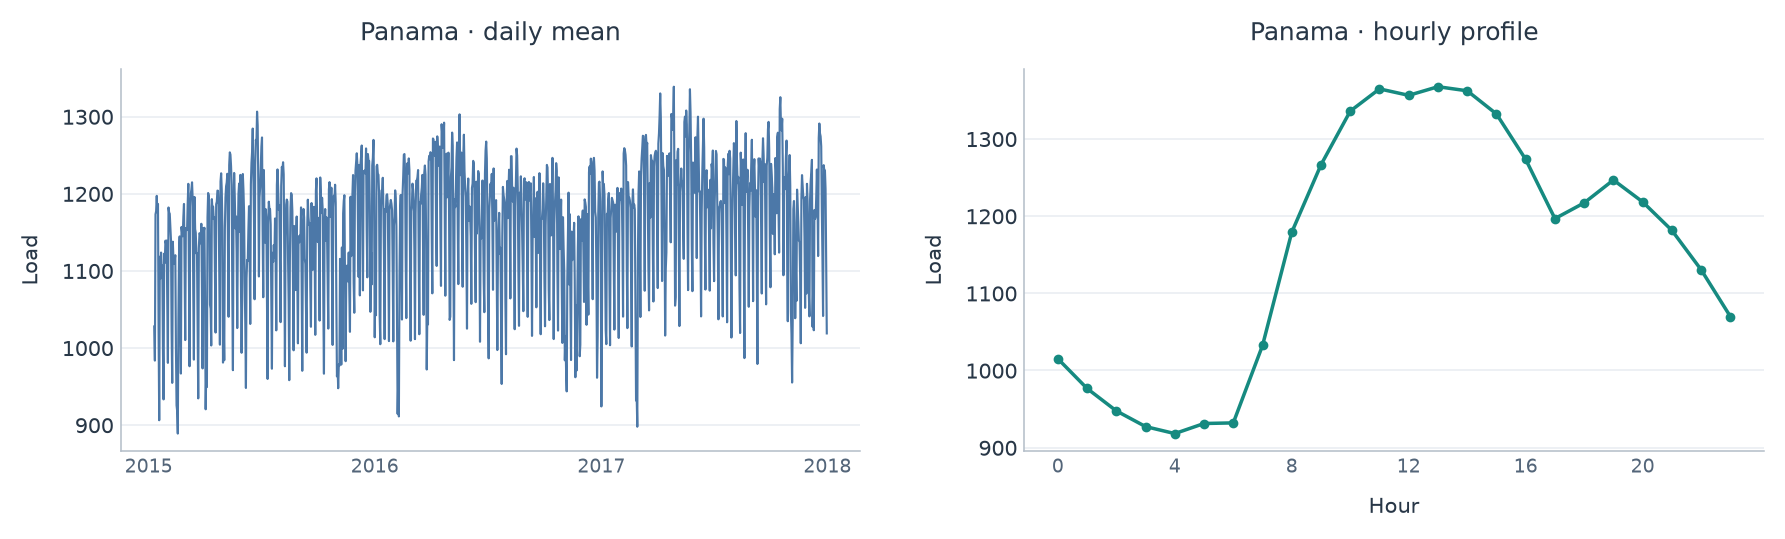

In [5]:
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.1))
    daily = training_view.target_next_hour.resample('D').mean()
    axes[0].plot(daily.index, daily, color=PLOT_COLORS['residual'], linewidth=1.1)
    axes[0].set(title='Panama · daily mean', ylabel='Load')
    analysis_dates(axes[0])
    hourly = training_view.groupby('hour').target_next_hour.mean()
    axes[1].plot(hourly.index, hourly, color=PLOT_COLORS['credit_feedback'], marker='o', markersize=4)
    axes[1].set(title='Panama · hourly profile', xlabel='Hour', ylabel='Load', xticks=range(0, 24, 4))
    for ax in axes:
        analysis_grid(ax, 'y')
    fig.tight_layout(pad=1.8, w_pad=3)
    plt.show()


## 3. Baasmudelite võrdlus
Võrdleme Ridge'i, Random Forestit, GBR-i ja HistGBR-i samade tunnuste ja prognoositundidega. Teisendused sobitame ainult treeningandmetel. Igal mudelil on üks fikseeritud seadistus. Tabel aitab baasivalikut põhjendada, kuid konfiguratsioonis valitud mudelit automaatselt ei muuda.


In [6]:
preliminary, preliminary_folds, preliminary_boundaries = compare_models(panama_development, cfg)
display(preliminary[["model", "n", *[f"MAE_{year}" for year in panama_options["development_years"]], "MAE", "RMSE", "bias"]])
print("Parim arenduse MAE:", preliminary.iloc[0].model)
print("Põhivõrdluse baasmudel:", cfg["base_model_family"])

Development 2018: Ridge


Development 2018: RandomForest


Development 2018: GBR


Development 2018: HistGBR


Development 2019: Ridge


Development 2019: RandomForest


Development 2019: GBR


Development 2019: HistGBR


,model,n,MAE_2018,MAE_2019,MAE,RMSE,bias
0,HistGBR,17520,13.8817,19.3317,16.6067,25.6586,-1.4890
1,RandomForest,17520,15.0092,22.2582,18.6337,29.6843,-1.7600
2,GBR,17520,17.9250,24.5936,21.2593,30.8325,-2.4997
3,Ridge,17520,29.2048,30.8666,30.0357,39.8541,3.2776


Parim arenduse MAE: HistGBR
Põhivõrdluse baasmudel: histgbr


## 4. Varasemate aastate prognoosivead
Iga aasta prognoosid teeb mudel, mida on treenitud ainult varasematel aastatel. Nii saame ajapõhised **OOF-prognoosid**: hinnatav tulemus ei osalenud mudeli treeningus. Parandusmudel õpib nende prognooside vigadest.


In [7]:
with threadpool_limits(limits=cfg["workers"]):
    panama_history = oof_history(
        panama_development, panama_options["test_year"], base_columns, cfg
    )
display(panama_history.groupby(panama_history.target_time.dt.year).size().to_frame("OOF tunde"))

  Base OOF 2016: 8784 forecasts


  Base OOF 2017: 8760 forecasts


  Base OOF 2018: 8760 forecasts


  Base OOF 2019: 8760 forecasts


,OOF tunde
target_time,
2016,8784
2017,8760
2018,8760
2019,8760


## 5. Parandajate seadete valik
Lihtne meetod kohandab parandusmudeli prognoosi sama kellaaja varasema keskmise vea järgi. XAI-meetod kaalub SHAP-osi nende varasema kasu ehk krediidi järgi. Mõlema mäluakna ja tugevuse valime ainult Panama 2018–2019 arenduses.

Valik arvestab MAE-d mõlemal aastal ja eri olukordades ning piirab halvenemist. Võrdluseks proovime püsikaalu, ühte muutuvat kaalu, lihtsamat krediiti ja vananevat mälu. `identity` jätab parandusmudeli prognoosi muutmata.


In [8]:
with threadpool_limits(limits=cfg["workers"]):
    development_results, choices, decay, development_folds = develop(
        panama_history, correction_columns, panama_thresholds, cfg, return_folds=True
    )
selection = {"choices": deepcopy(choices), "decay": deepcopy(decay)}
choice_rows = []
for method, choice in choices.items():
    setting = choice["setting"] or {}
    choice_rows.append({
        "Meetod": LABELS[method], "Kandidaat": choice["candidate"],
        "Aken (h)": setting.get("window_hours"), "Tugevus": setting.get("strength"),
        "Sama kellaaeg": setting.get("by_hour", True),
        "Arenduse MAE-suhtarv": choice["development_ratio"],
    })
display(pd.DataFrame(choice_rows))
print("Vananeva mälu valik:", decay)
print("Seaded fikseeriti enne lõpphindamist.")

  Development 2018: evaluated fixed and adaptive policies


  Development 2019: evaluated fixed and adaptive policies


,Meetod,Kandidaat,Aken (h),Tugevus,Sama kellaaeg,Arenduse MAE-suhtarv
0,Püsikaal,identity,NaN,NaN,True,1.0000
1,Lihtne,hourly_bias_w168_s0.25,168.0000,0.2500,True,0.9887
2,Üks adaptiivne kaal,scalar_adaptive_w168_h1_s0.25,168.0000,0.2500,True,0.9975
3,Osad eraldi,standalone_feedback_w168_h1_s1.0,168.0000,1.0000,True,0.9948
4,XAI,credit_feedback_w168_h1_s1.0,168.0000,1.0000,True,0.9925


Vananeva mälu valik: {'candidate': 'decay_168', 'half_life_hours': 168, 'development_ratio': 0.9920089907648113, 'memory': 'exponential'}
Seaded fikseeriti enne lõpphindamist.


## 6. Ühendatud parandaja ja katseplaan
**Idee:** XAI-osade kaalumine ja üldise prognoosivea parandamine võivad teineteist täiendada. Lisame XAI-prognoosile sama kellaaja varasemate vigade keskmisel põhineva paranduse. Kasutame selleks XAI-prognoosi enda vigu.

Kontrollmeetod kaalub kogu parandusmudeli ennustatud veaparandust ühe kaaluga. Kaalureegel ja seaded on XAI-ga samad, kuid SHAP-i pole vaja. Ka see meetod saab sama lisakihi, kasutades enda varasemaid vigu.

Kasutame Panama 2018–2019 arenduses juba valitud seadeid ja treenitud mudeleid. Uusi parameetreid ei otsi. Allolev arendustulemus aitab ideed hinnata, kuid pole sõltumatu kinnitus.

**Enne Eesti 2025 hindamist fikseerime** mudelid, mõlema paranduskihi seaded, algse ooteaja, hindamisperioodi ja neli võrdluspaari. Põhinäitaja on kogu aasta MAE. XAI lisakasu kinnituseks peab ühendatud meetod edestama nii lihtsat parandajat kui ka sama lisakihiga ühe kaalu kontrolli. Mõlemat võrdlust hindame mitmese võrdluse parandusega vahemike abil.

Neli paari ja kolm olukorda annavad 12 võrdlust. Põhiplokk on 168 tundi, tundlikkuskontroll 24 tundi. Kiired muutused on lisaanalüüs.

2025 tulemust näitame sõltumata arenduskatse tulemusest ega vali selle järgi seadeid ümber. Mudelid treenime enne 2025 aastat; aasta jooksul muutub ainult varasematel tulemustel põhinev tagasiside. Kõigil meetoditel on sama algse ooteaja reegel.


In [9]:
combined_protocol = deepcopy({
    "test_year": cfg["combined_correction"]["test_year"],
    "xai_setting": choices["credit_feedback"]["setting"],
    "bias_setting": choices["hourly_bias"]["setting"],
    "feedback": cfg["feedback"], "base_model_family": cfg["base_model_family"],
    "base_model": cfg["base_model"], "residual_model": cfg["residual_model"],
    "seed": cfg["seed"], "load_delay_hours": cfg["load_delay_hours"],
    "weather_delay_hours": cfg["weather_delay_hours"], "evaluation": cfg["evaluation"],
    "threshold_end": cfg["datasets"]["estonia"]["threshold_end"], "pairs": COMBINED_PAIRS,
})
combined_protocol_snapshot = deepcopy(combined_protocol)
combined_development_parts = []
with threadpool_limits(limits=cfg["workers"]):
    for valid_dev, components_dev, fitted_dev in development_folds:
        frame_dev = valid_dev.assign(prediction_residual=fitted_dev["residual"])
        predictions_dev = combined_forecasts(
            frame_dev, components_dev, combined_protocol["xai_setting"],
            combined_protocol["bias_setting"], combined_protocol["feedback"],
        )
        combined_development_parts.append(score_forecasts(
            frame_dev, predictions_dev, panama_thresholds, cfg, "development"
        ))
combined_development = pd.concat(combined_development_parts, ignore_index=True)
assert set(combined_development.year) == set(cfg["datasets"]["panama"]["development_years"])
assert combined_development.stage.eq("development").all()
display(combined_development[combined_development.scope.eq("overall")].assign(
    Meetod=lambda x: x.method.map(COMBINED_LABELS)
)[["year", "Meetod", "n", "MAE", "RMSE", "bias"]].rename(columns={
    "year": "Aasta", "n": "Tunde", "bias": "Keskmine viga",
}))
dev_comparison = combined_development.pivot(index=["year", "scope"], columns="method", values="MAE")
display(pd.DataFrame({
    "XAI + veaparandus miinus lihtne": dev_comparison.xai_bias - dev_comparison.hourly_bias,
    "XAI + veaparandus miinus üks kaal + veaparandus": dev_comparison.xai_bias - dev_comparison.scalar_bias,
}))
print("Enne 2025 hindamist fikseeritud plaan:", combined_protocol)


,Aasta,Meetod,Tunde,MAE,RMSE,Keskmine viga
0,2018,Baas,8760,13.7729,18.5976,-1.6453
3,2018,Jääkparandus,8760,12.6234,16.9642,-1.2829
6,2018,Lihtne,8760,12.4980,16.8301,-0.9690
9,2018,XAI,8760,12.4324,16.6971,-0.8648
12,2018,Üks kaal,8760,12.5872,16.8719,-1.2720
15,2018,XAI + veaparandus,8760,12.4600,16.7331,-0.6560
18,2018,Üks kaal + veaparandus,8760,12.4894,16.7712,-0.9611
21,2019,Baas,8760,19.2399,31.0780,-1.4865
24,2019,Jääkparandus,8760,15.7176,26.8298,-1.5946
27,2019,Lihtne,8760,15.4852,26.5223,-1.1983


XAI + veaparandus miinus lihtne  \
year scope                                             
2018 overall                                 -0.0380   
     rapid_decrease                          -0.0160   
     rapid_increase                           0.0708   
2019 overall                                  0.0150   
     rapid_decrease                           0.2493   
     rapid_increase                          -0.0423   

                     XAI + veaparandus miinus üks kaal + veaparandus  
year scope                                                            
2018 overall                                                 -0.0295  
     rapid_decrease                                          -0.0505  
     rapid_increase                                           0.2225  
2019 overall                                                 -0.0561  
     rapid_decrease                                           0.1620  
     rapid_increase                                          -0.0650

Enne 2025 hindamist fikseeritud plaan: {'test_year': 2025, 'xai_setting': {'window_hours': 168, 'by_hour': True, 'strength': 1.0}, 'bias_setting': {'window_hours': 168, 'strength': 0.25}, 'feedback': {'min_history_points': 3, 'warmup_hours': 72}, 'base_model_family': 'histgbr', 'base_model': {'n_estimators': 120, 'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 30, 'loss': 'squared_error'}, 'residual_model': {'max_iter': 180, 'learning_rate': 0.06, 'max_leaf_nodes': 15, 'min_samples_leaf': 30, 'l2_regularization': 1.0, 'early_stopping': False}, 'seed': 42, 'load_delay_hours': 0, 'weather_delay_hours': 24, 'evaluation': {'bootstrap_blocks_hours': [24, 168], 'primary_block_hours': 168, 'bootstrap_repeats': 5000, 'harm_tolerance': 1e-09}, 'threshold_end': '2021-01-01', 'pairs': (('xai_bias', 'hourly_bias'), ('xai_bias', 'scalar_bias'), ('xai_bias', 'credit_feedback'), ('scalar_bias', 'matched_scalar'))}


## 7. Lõppmudelite treening
Iga riigi mudelid treenime selle varasematel andmetel. Eesti kasutab Panama arenduses valitud parandajaseadeid. Kõigil meetoditel on samad mudelid ja hindamistunnid. Aasta jooksul muutub ainult tagasiside.

Panama allikas lõpeb juunis; puuduvaid tunde ei hinda. Eesti ajajoon ja aastajaotus on UTC-s, kellaajarühmad Tallinna ajas.


In [10]:
runs, metric_parts, coverage = {}, [], []
with threadpool_limits(limits=cfg["workers"]):
    for dataset in DATASETS:
        options = cfg["datasets"][dataset]
        frame, quality = load_dataset(ROOT / options["path"], cfg, dataset)
        base_columns, correction_columns = feature_columns(dataset)
        history = (panama_history if dataset == "panama" else
                   oof_history(frame, options["test_year"], base_columns, cfg))
        hold = annual_forecast(frame, options["test_year"], base_columns, cfg)
        combined = pd.concat(
            [history.drop(columns=ERROR_FEATURES), hold], ignore_index=True
        )
        combined = pd.concat([combined, known_error_features(combined)], axis=1)
        train, valid = split_year(combined, options["test_year"])
        fitted_forecasts, components, inputs, residual_model = residual_forecasts(
            train, valid, correction_columns, cfg, return_model=True
        )
        forecasts, traces = policy_forecasts(
            valid, fitted_forecasts, components, selection, cfg
        )
        forecasts["naive"] = persistence_forecast(valid)
        weights = traces["credit_feedback"]
        effective = components * weights
        initial = frame[frame.target_time < options["threshold_end"]]
        thresholds = {"increase": float(initial.actual_ramp.quantile(0.95)),
                      "decrease": float(initial.actual_ramp.quantile(0.05))}
        assert train.target_time.max() <= valid.origin_time.min()
        assert valid.target_time.is_unique
        assert np.isfinite(np.column_stack(list(forecasts.values()))).all()
        valid["prediction_residual"] = forecasts["residual"]
        runs[dataset] = {"residual_model": residual_model, "training": train, "inputs": inputs,
                         "frame": valid, "forecasts": forecasts, "weights": weights,
                         "components": components, "effective": effective,
                         "thresholds": thresholds}
        metric_parts.append(score_forecasts(
            valid, forecasts, thresholds, cfg, "final"
        ).assign(dataset=dataset))
        coverage.append({
            "Andmestik": COUNTRIES[dataset], "Esimene sihttund": valid.target_time.min(),
            "Viimane sihttund": valid.target_time.max(), "Hinnatud tunde": len(valid),
            "Aasta kalendritunde": quality["calendar_test_hours"],
            "Hindamata tunde": quality["unscored_test_hours"],
            "Viimane treeningu sihtaeg": train.target_time.max(),
        })

assert choices == selection["choices"]
metrics = pd.concat(metric_parts, ignore_index=True)
display(pd.DataFrame(coverage))

  Base OOF 2020: 4273 forecasts


  Base OOF 2019: 8708 forecasts


  Base OOF 2020: 8784 forecasts


  Base OOF 2021: 8760 forecasts


  Base OOF 2022: 8760 forecasts


  Base OOF 2023: 8708 forecasts


  Base OOF 2024: 8654 forecasts


,Andmestik,Esimene sihttund,Viimane sihttund,Hinnatud tunde,Aasta kalendritunde,Hindamata tunde,Viimane treeningu sihtaeg
0,Panama,2020-01-01,2020-06-27 00:00:00,4273,8784,4511,2019-12-31 23:00:00
1,Eesti,2024-01-01,2024-12-31 23:00:00,8654,8784,130,2023-12-31 23:00:00


## 8. Üldine täpsus
**MAE** näitab keskmist absoluutviga, **RMSE** annab suurematele vigadele rohkem kaalu. **Keskmine nihe** (`bias`) näitab, kas prognoos on keskmiselt liiga kõrge või madal. Positiivne nihe tähendab liiga kõrget, negatiivne liiga madalat prognoosi. Väiksem MAE ja RMSE on parem.

Tulemused on iga andmestiku algühikutes. `identity` tähendab, et püsikaal ei muuda parandusmudeli prognoosi.


In [11]:
overall = metrics[metrics.scope.eq("overall")].copy()
assert overall.groupby("dataset").n.nunique().eq(1).all()
overall_view = overall[overall.method.isin(BASELINES)].assign(
    Andmestik=overall.dataset.map(COUNTRIES), Meetod=overall.method.map(LABELS)
)[["Andmestik", "Meetod", "n", "MAE", "RMSE", "bias", "improvement_vs_residual_pct"]]
display(overall_view.rename(columns={
    "n": "Tunde", "bias": "Keskmine nihe",
    "improvement_vs_residual_pct": "Paranemine jäägiparandusest (%)",
}))

,Andmestik,Meetod,Tunde,MAE,RMSE,Keskmine nihe,Paranemine jäägiparandusest (%)
0,Panama,Baas,4273,20.4511,27.1860,-0.3301,-22.8250
3,Panama,Otseprognoos,4273,17.6173,23.6014,-0.0696,-5.8056
6,Panama,Jääkparandus,4273,16.6506,22.2651,0.9595,0.0000
9,Panama,Lihtne,4273,15.7702,21.1909,0.7312,5.2875
12,Panama,Püsikaal,4273,16.6506,22.2651,0.9595,0.0000
15,Panama,Üks adaptiivne kaal,4273,16.6227,22.2090,0.8420,0.1678
18,Panama,Osad eraldi,4273,15.7654,21.2128,0.3342,5.3165
21,Panama,XAI,4273,15.7765,21.2161,0.2676,5.2498
66,Panama,Naiivne,4273,38.0704,49.2074,0.0166,-128.6431
69,Eesti,Baas,8654,22.1208,31.5539,2.4164,-33.3376


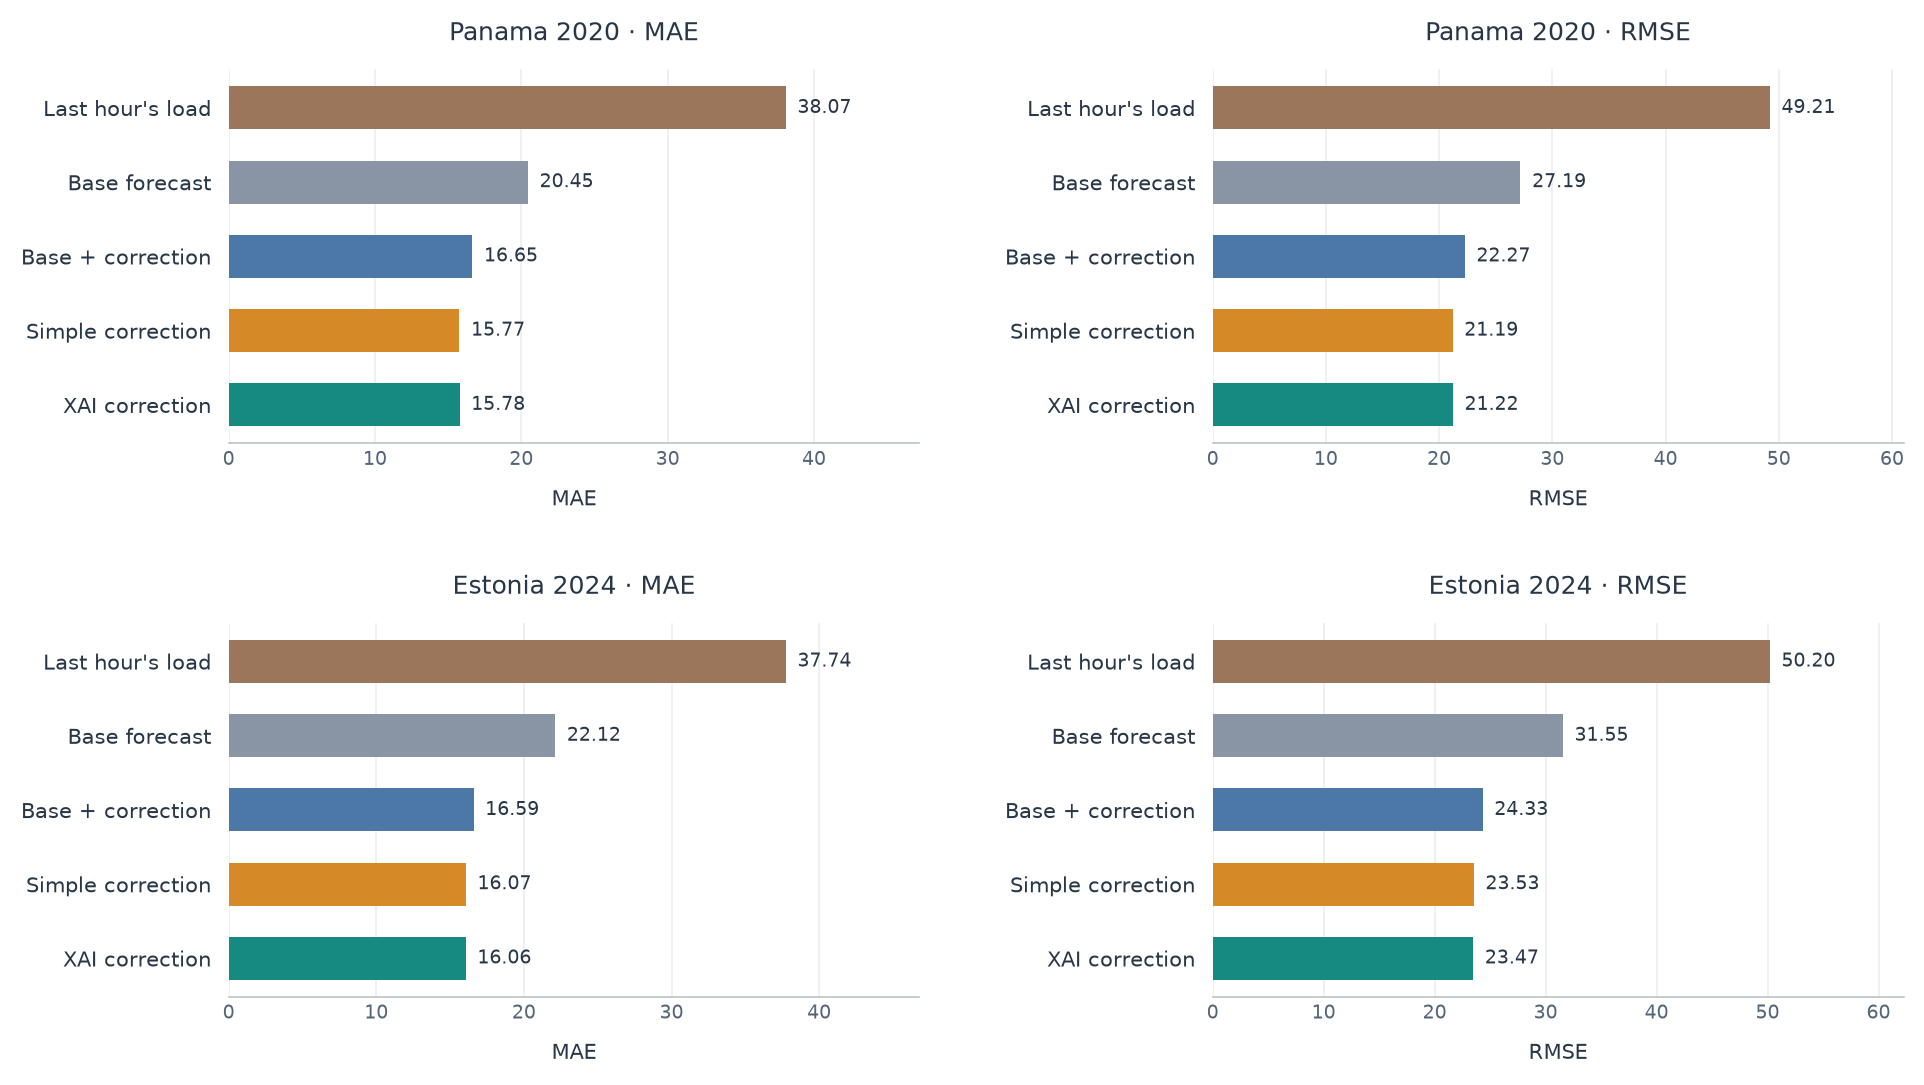

In [12]:
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(len(DATASETS), 2, figsize=(14, 8), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        values = overall[overall.dataset.eq(dataset)].set_index('method').loc[list(METHODS)]
        for col, metric in enumerate(('MAE', 'RMSE')):
            ax = axes[row, col]
            analysis_barh(ax, [PLOT_LABELS[m] for m in METHODS], values[metric],
                          [PLOT_COLORS[m] for m in METHODS])
            ax.set(title=f'{PLOT_TITLES[dataset]} · {metric}', xlabel=metric)
    fig.tight_layout(pad=1.8, w_pad=4, h_pad=3)
    plt.show()


## 9. Tulemus kuude lõikes
Kuine MAE näitab, millal parandajad aitavad ja millal halvendavad. Nende tulemuste põhjal seadeid ei muuda.


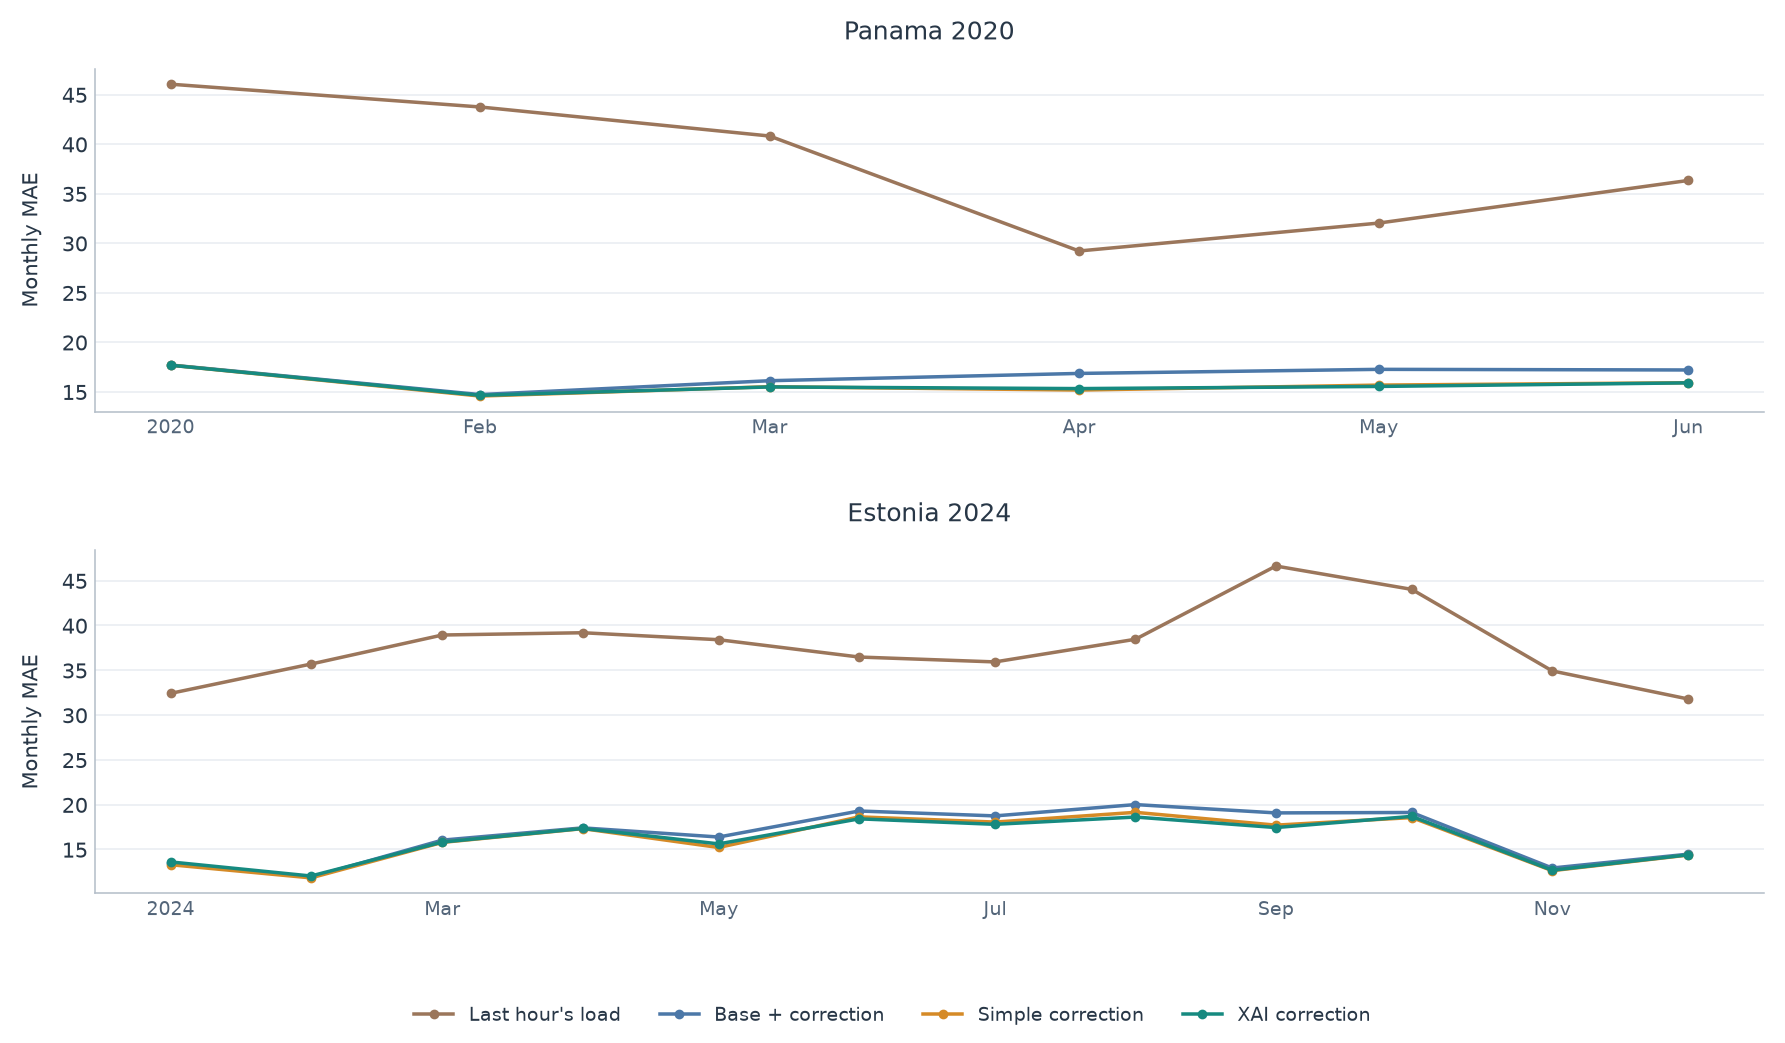

In [13]:
monthly = {}
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(len(DATASETS), 1, figsize=(13, 7.5), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        frame = runs[dataset]['frame']
        y = frame.target_next_hour.to_numpy()
        monthly[dataset] = pd.DataFrame({
            method: np.abs(runs[dataset]['forecasts'][method] - y)
            for method in METHODS if method != 'base'
        }, index=pd.DatetimeIndex(frame.target_time)).resample('MS').mean()
        ax = axes[row, 0]
        for method in monthly[dataset]:
            ax.plot(monthly[dataset].index, monthly[dataset][method], marker='o', markersize=4,
                    color=PLOT_COLORS[method], label=PLOT_LABELS[method])
        ax.set(title=PLOT_TITLES[dataset], ylabel='Monthly MAE')
        analysis_dates(ax, maxticks=8)
        analysis_grid(ax, 'y')
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='lower center', ncol=4)
    fig.tight_layout(pad=1.8, h_pad=3, rect=(0, 0.07, 1, 1))
    plt.show()


## 10. Kiired koormusmuutused
Kiire tõusu ja languse piirid arvutasime enne arendust. Tegelik muutus määrab ainult hindamisrühma ega lähe mudeli sisendiks. `n` näitab rühma tundide arvu.


In [14]:
scope_view = metrics[
    metrics.scope.ne("overall") & metrics.method.isin(("residual", "hourly_bias", "credit_feedback"))
].assign(Andmestik=lambda x: x.dataset.map(COUNTRIES),
         Meetod=lambda x: x.method.map(LABELS))
display(scope_view[["Andmestik", "scope", "Meetod", "n", "MAE", "RMSE"]].rename(
    columns={"scope": "Olukord", "n": "Tunde"}
))

,Andmestik,Olukord,Meetod,Tunde,MAE,RMSE
7,Panama,rapid_increase,Jääkparandus,72,23.6682,33.2959
8,Panama,rapid_decrease,Jääkparandus,137,26.7330,34.5542
10,Panama,rapid_increase,Lihtne,72,23.1300,32.8417
11,Panama,rapid_decrease,Lihtne,137,26.7858,34.5369
22,Panama,rapid_increase,XAI,72,23.2331,32.5053
23,Panama,rapid_decrease,XAI,137,26.2101,34.2528
76,Eesti,rapid_increase,Jääkparandus,511,25.2181,35.7652
77,Eesti,rapid_decrease,Jääkparandus,383,40.1596,52.6240
79,Eesti,rapid_increase,Lihtne,511,23.8660,34.2452
80,Eesti,rapid_decrease,Lihtne,383,37.5440,49.6598


## 11. Millest XAI-meetodi kasu tuleb?
Kontrollid kasutavad sama parandusmudelit ja XAI seadeid. Muudame üht osa korraga: kaalume kogu parandust ühe kaaluga, jätame krediidist osade koosmõju välja või kasutame mälu ilma kellaajarühmadeta. Eraldi krediidi meetodil on lisaks oma arenduses valitud seaded. Nii saame hinnata iga osa panust.


In [15]:
controls = ("residual", "scalar_adaptive", "standalone_feedback", "credit_feedback",
            "matched_scalar", "matched_standalone", "no_context")
display(overall[overall.method.isin(controls)].assign(
    Andmestik=lambda x: x.dataset.map(COUNTRIES), Meetod=lambda x: x.method.map(LABELS)
)[["Andmestik", "Meetod", "n", "MAE", "RMSE", "improvement_vs_residual_pct"]])

,Andmestik,Meetod,n,MAE,RMSE,improvement_vs_residual_pct
6,Panama,Jääkparandus,4273,16.6506,22.2651,0.0000
15,Panama,Üks adaptiivne kaal,4273,16.6227,22.2090,0.1678
18,Panama,Osad eraldi,4273,15.7654,21.2128,5.3165
21,Panama,XAI,4273,15.7765,21.2161,5.2498
24,Panama,Üks krediidikaal,4273,16.6476,22.2568,0.0178
27,Panama,Koosmõjuta,4273,15.7654,21.2128,5.3165
30,Panama,Kellaajata,4273,16.5531,22.1523,0.5856
75,Eesti,Jääkparandus,8654,16.5901,24.3281,0.0000
84,Eesti,Üks adaptiivne kaal,8654,16.5866,24.3286,0.0207
87,Eesti,Osad eraldi,8654,16.1378,23.5059,2.7259


## 12. Krediit, mälu ja seadete mõju
Põhireegli krediit põhineb ruutveal. MAE-krediit kasutab absoluutviga. Vananev mälu annab värskematele tulemustele rohkem kaalu. Üheksa ette määratud mäluakna ja tugevuse kombinatsiooni näitavad seadete mõju. Nende põhjal uut lõppmeetodit ei vali.

Soojuskaart näitab MAE paranemist kaalumata parandusmudeli prognoosist.


In [16]:
robust_methods = ("residual", "credit_feedback", "mae_credit", "recency_credit")
display(overall[overall.method.isin(robust_methods)][
    ["dataset", "method", "n", "MAE", "RMSE", "improvement_vs_residual_pct",
     "harmful_rate_vs_base", "harmful_magnitude_vs_base"]
])

,dataset,method,n,MAE,RMSE,improvement_vs_residual_pct,harmful_rate_vs_base,harmful_magnitude_vs_base
6,panama,residual,4273,16.6506,22.2651,0.0000,0.3721,2.2034
21,panama,credit_feedback,4273,15.7765,21.2161,5.2498,0.3400,1.9728
33,panama,mae_credit,4273,15.8054,21.2752,5.0763,0.3436,1.9815
36,panama,recency_credit,4273,15.7790,21.2131,5.2347,0.3405,1.9801
75,estonia,residual,8654,16.5901,24.3281,0.0000,0.3470,2.5691
90,estonia,credit_feedback,8654,16.0589,23.4745,3.2017,0.3512,2.6904
102,estonia,mae_credit,8654,16.0683,23.5409,3.1448,0.3514,2.6645
105,estonia,recency_credit,8654,16.0569,23.4650,3.2140,0.3521,2.7008


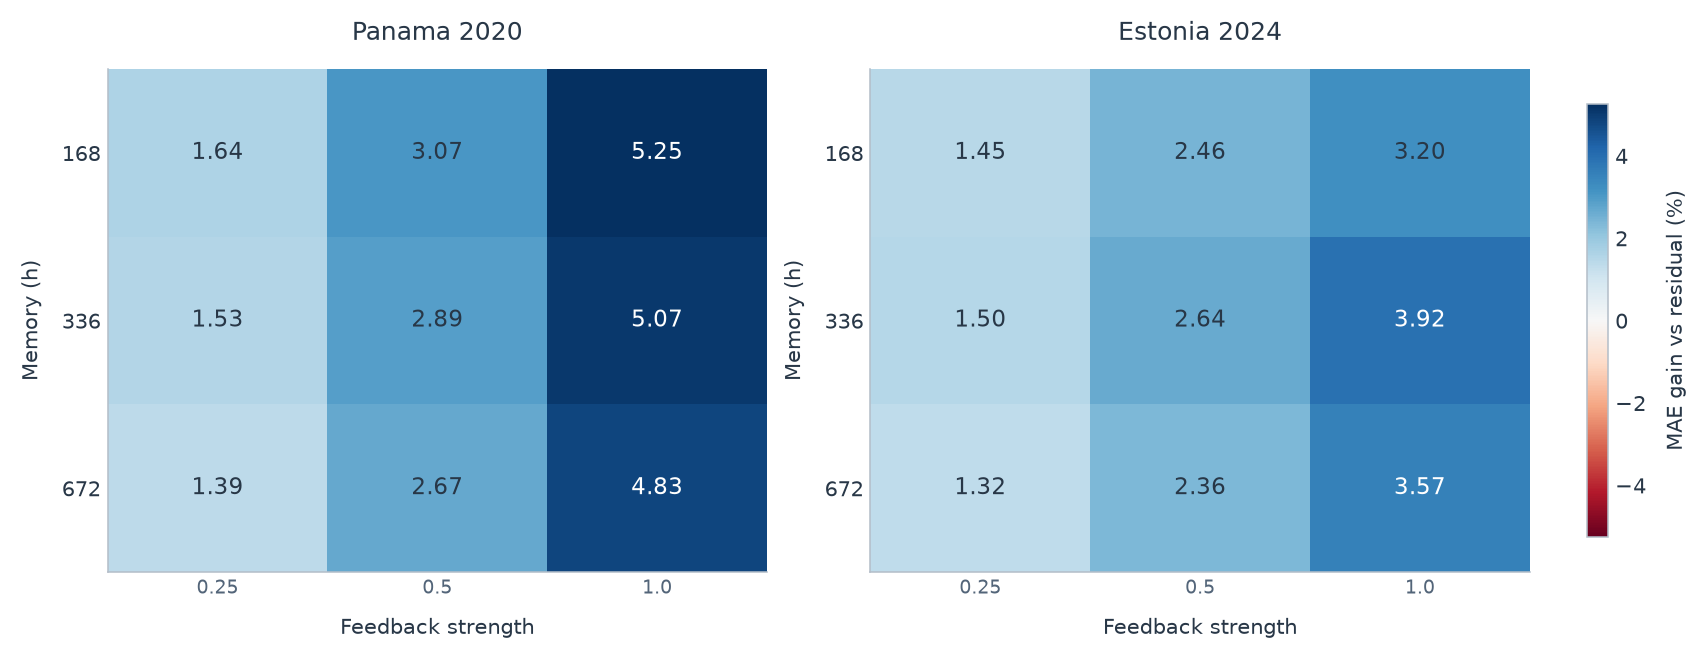

In [17]:
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(12, 4.5), squeeze=False, layout='constrained')
    grids = {}
    for dataset in DATASETS:
        values = overall[overall.dataset.eq(dataset) & overall.method.str.startswith('sensitivity_')].copy()
        values['window'] = values.method.str.extract(r'_w(\d+)', expand=False).astype(int)
        values['strength'] = values.method.str.extract(r'_s([\d.]+)', expand=False).astype(float)
        grids[dataset] = values.pivot(index='window', columns='strength', values='improvement_vs_residual_pct')
    limit = max(abs(grid.to_numpy()).max() for grid in grids.values())
    limit = max(float(limit), 1e-9)
    for col, dataset in enumerate(DATASETS):
        grid = grids[dataset]
        ax = axes[0, col]
        picture = ax.imshow(grid.to_numpy(), cmap='RdBu', vmin=-limit, vmax=limit, aspect='auto')
        ax.set_xticks(range(len(grid.columns)), grid.columns)
        ax.set_yticks(range(len(grid.index)), grid.index)
        for row in range(len(grid.index)):
            for column in range(len(grid.columns)):
                value = float(grid.iloc[row, column])
                ax.text(column, row, f'{value:.2f}', ha='center', va='center', fontsize=12,
                        color='white' if abs(value) > 0.65 * limit else '#283747')
        ax.set(title=PLOT_TITLES[dataset], xlabel='Feedback strength', ylabel='Memory (h)')
    fig.colorbar(picture, ax=list(axes.flat), label='MAE gain vs residual (%)', shrink=0.86, pad=0.04)
    plt.show()


## 13. Lihtsa ja XAI-meetodi võrdlus
Vahe on **lihtsa meetodi absoluutviga − XAI absoluutviga**. Negatiivne väärtus soosib lihtsat meetodit, positiivne XAI-d.

Vahemikud leiame bootstrap’iga: valime ajaplokke korduvalt uuesti, hoides lähestikused tunnid koos. Bonferroni parandus katab mõlema riigi kolm olukorda. Kui vahemik sisaldab nulli, ei leitud selget erinevust; see ei tõesta meetodite võrdsust. Kontroll ei kõrvalda varasemate arendusvalikute mõju.


In [18]:
interval_rows = []
comparison_count = len(DATASETS) * 3
for dataset in DATASETS:
    run = runs[dataset]
    frame, forecasts = run["frame"], run["forecasts"]
    y = frame.target_next_hour.to_numpy()
    delta = abs(forecasts["hourly_bias"] - y) - abs(forecasts["credit_feedback"] - y)
    for scope, mask in scope_masks(frame, run["thresholds"]).items():
        if not mask.any():
            continue
        for block in cfg["evaluation"]["bootstrap_blocks_hours"]:
            interval_rows.append({
                "dataset": dataset, "scope": scope, "n": int(mask.sum()),
                **clock_loss_interval(
                    frame.target_time, delta, mask, block=block,
                    repeats=cfg["evaluation"]["bootstrap_repeats"],
                    seed=cfg["seed"], comparisons=comparison_count,
                ),
            })
intervals = pd.DataFrame(interval_rows)
primary_intervals = intervals[
    intervals.block_hours.eq(cfg["evaluation"]["primary_block_hours"])
].copy()
display(primary_intervals[[
    "dataset", "scope", "n", "difference", "adjusted_low", "adjusted_high"
]])

,dataset,scope,n,difference,adjusted_low,adjusted_high
1,panama,overall,4273,-0.0063,-0.1494,0.1298
3,panama,rapid_increase,72,-0.1032,-1.1115,0.7341
5,panama,rapid_decrease,137,0.5757,-0.1647,1.5909
7,estonia,overall,8654,0.0065,-0.1319,0.1576
9,estonia,rapid_increase,511,-0.0316,-0.6718,0.6133
11,estonia,rapid_decrease,383,0.6924,0.0565,1.2204


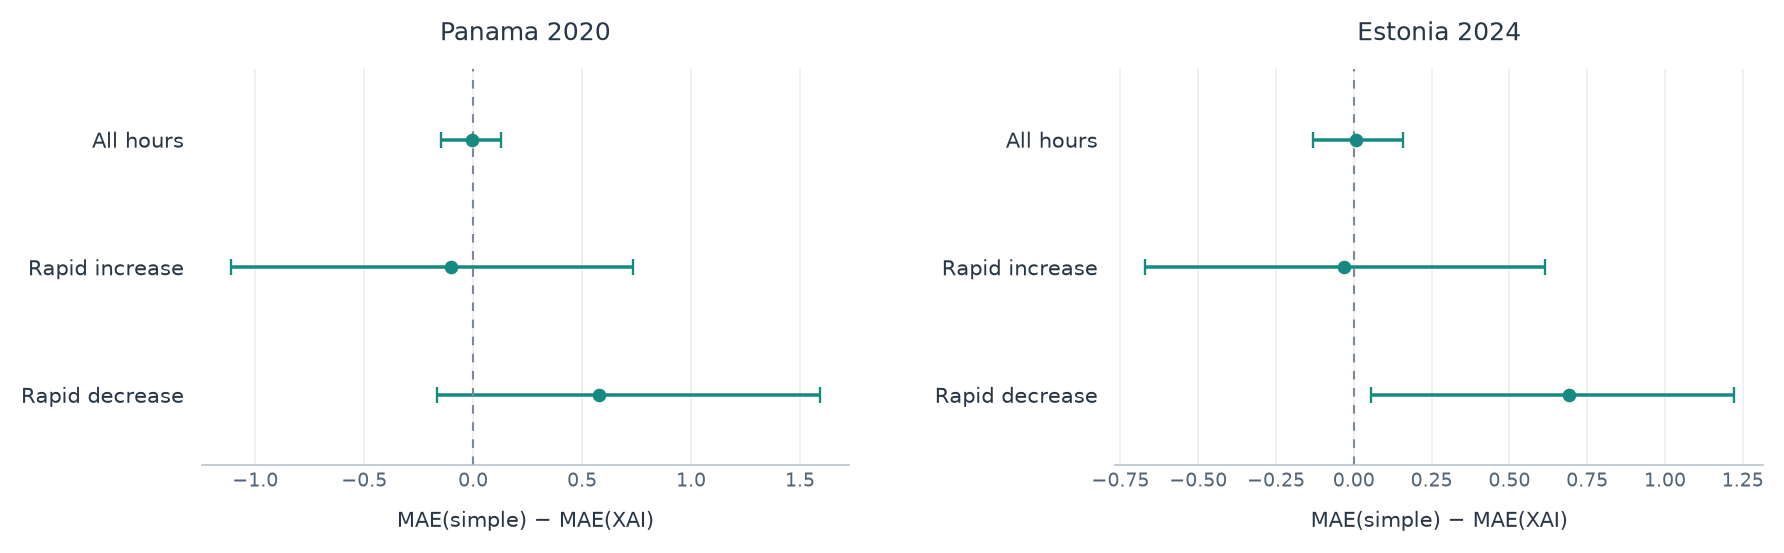

In [19]:
scope_labels = {'overall': 'Kõik tunnid', 'rapid_increase': 'Kiire tõus', 'rapid_decrease': 'Kiire langus'}
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(13, 4.2), squeeze=False)
    for col, dataset in enumerate(DATASETS):
        values = primary_intervals[primary_intervals.dataset.eq(dataset)]
        ax = axes[0, col]
        analysis_intervals(ax, values, values.scope.map(PLOT_SCOPES), PLOT_COLORS['credit_feedback'])
        ax.set(title=PLOT_TITLES[dataset], xlabel='MAE(simple) − MAE(XAI)')
    fig.tight_layout(pad=1.8, w_pad=4)
    plt.show()


## 14. Kahjulikud parandused
Parandus on kahjulik, kui absoluutviga on baasprognoosi omast suurem. Keskmine lisakahju arvestab kõiki hinnatud tunde. Väiksem MAE ei tähenda tingimata vähem kahjulikke parandusi.


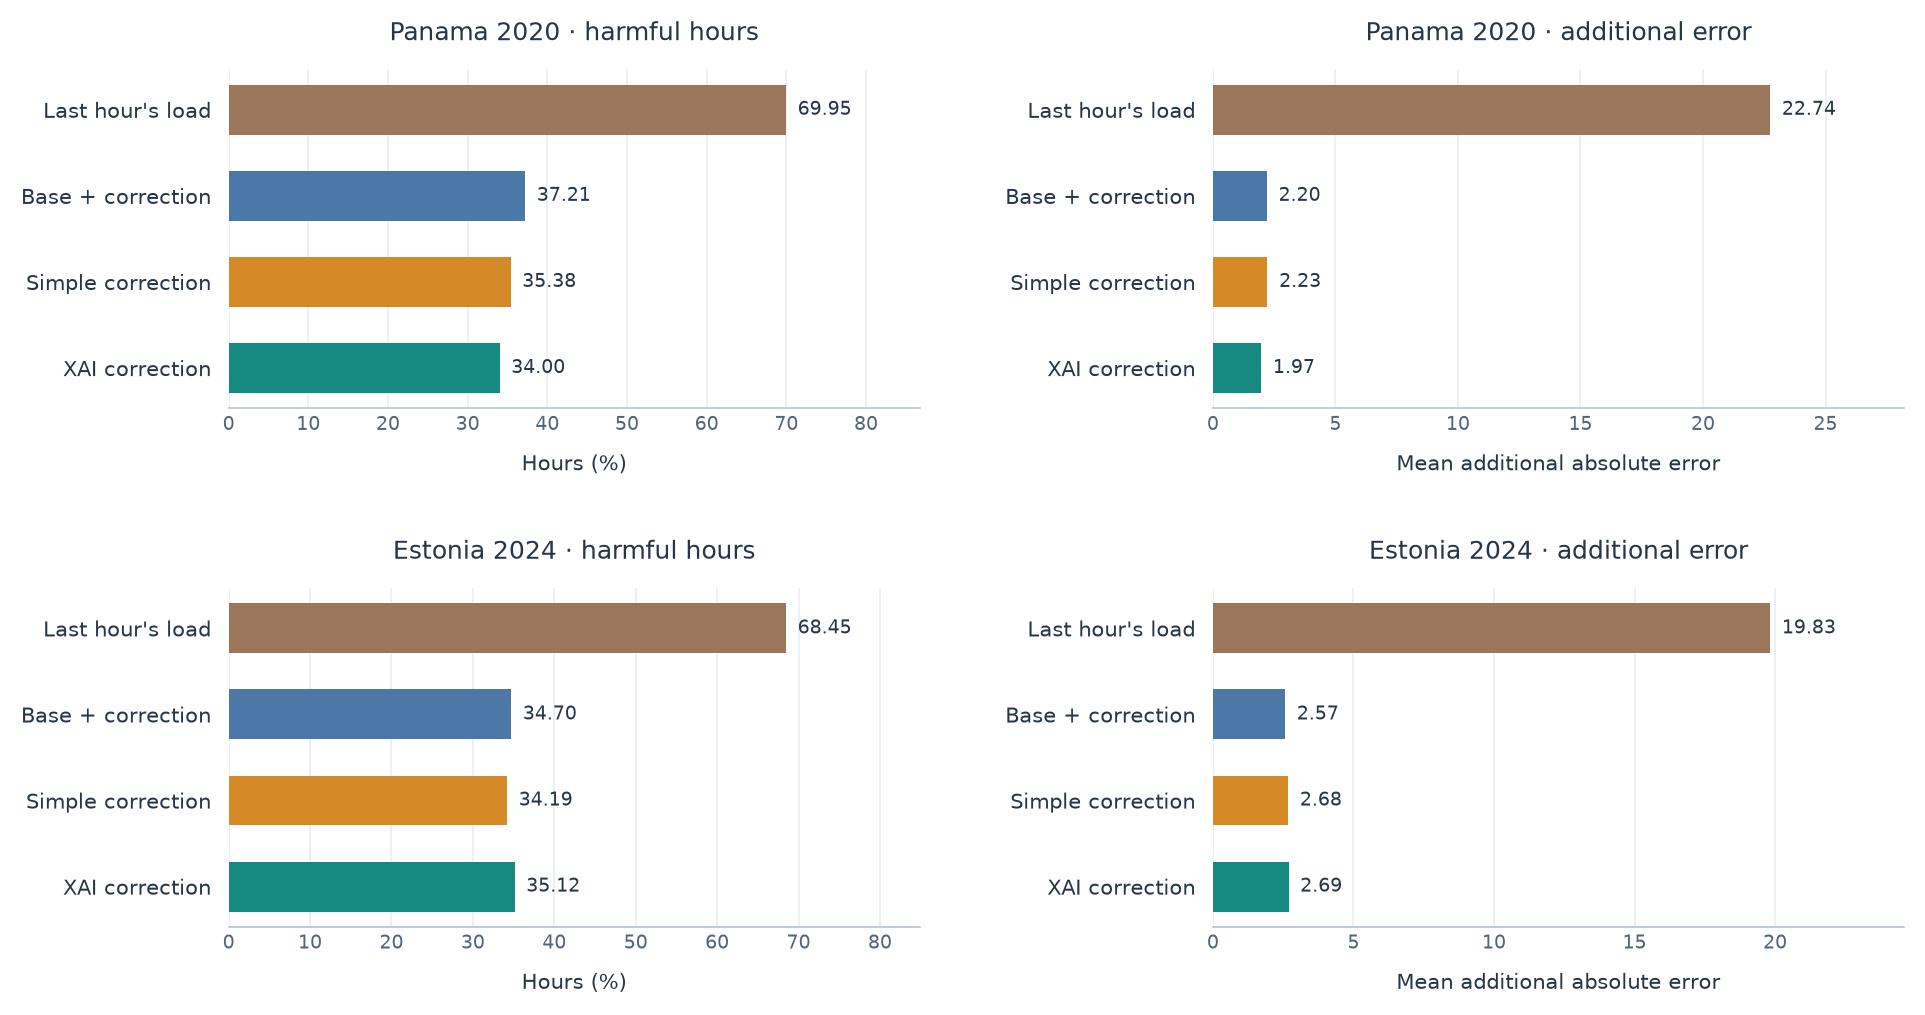

In [20]:
corrections = [m for m in METHODS if m != 'base']
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(len(DATASETS), 2, figsize=(14, 7.5), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        values = overall[overall.dataset.eq(dataset)].set_index('method').loc[corrections]
        for col, (metric, factor, title, label) in enumerate([
            ('harmful_rate_vs_base', 100, 'harmful hours', 'Hours (%)'),
            ('harmful_magnitude_vs_base', 1, 'additional error', 'Mean additional absolute error'),
        ]):
            ax = axes[row, col]
            analysis_barh(ax, [PLOT_LABELS[m] for m in corrections], values[metric] * factor,
                          [PLOT_COLORS[m] for m in corrections])
            ax.set(title=f'{PLOT_TITLES[dataset]} · {title}', xlabel=label)
    fig.tight_layout(pad=1.8, w_pad=4, h_pad=3)
    plt.show()


## 15. Prognoosid ajas
Näiteaken algab varem määratud ajal; seda ei vali võidu suuruse järgi. Parempoolsel graafikul on lihtsa ja XAI absoluutvigade vahe. Positiivne tulp tähendab XAI väiksemat viga, negatiivne lihtsa meetodi väiksemat viga.


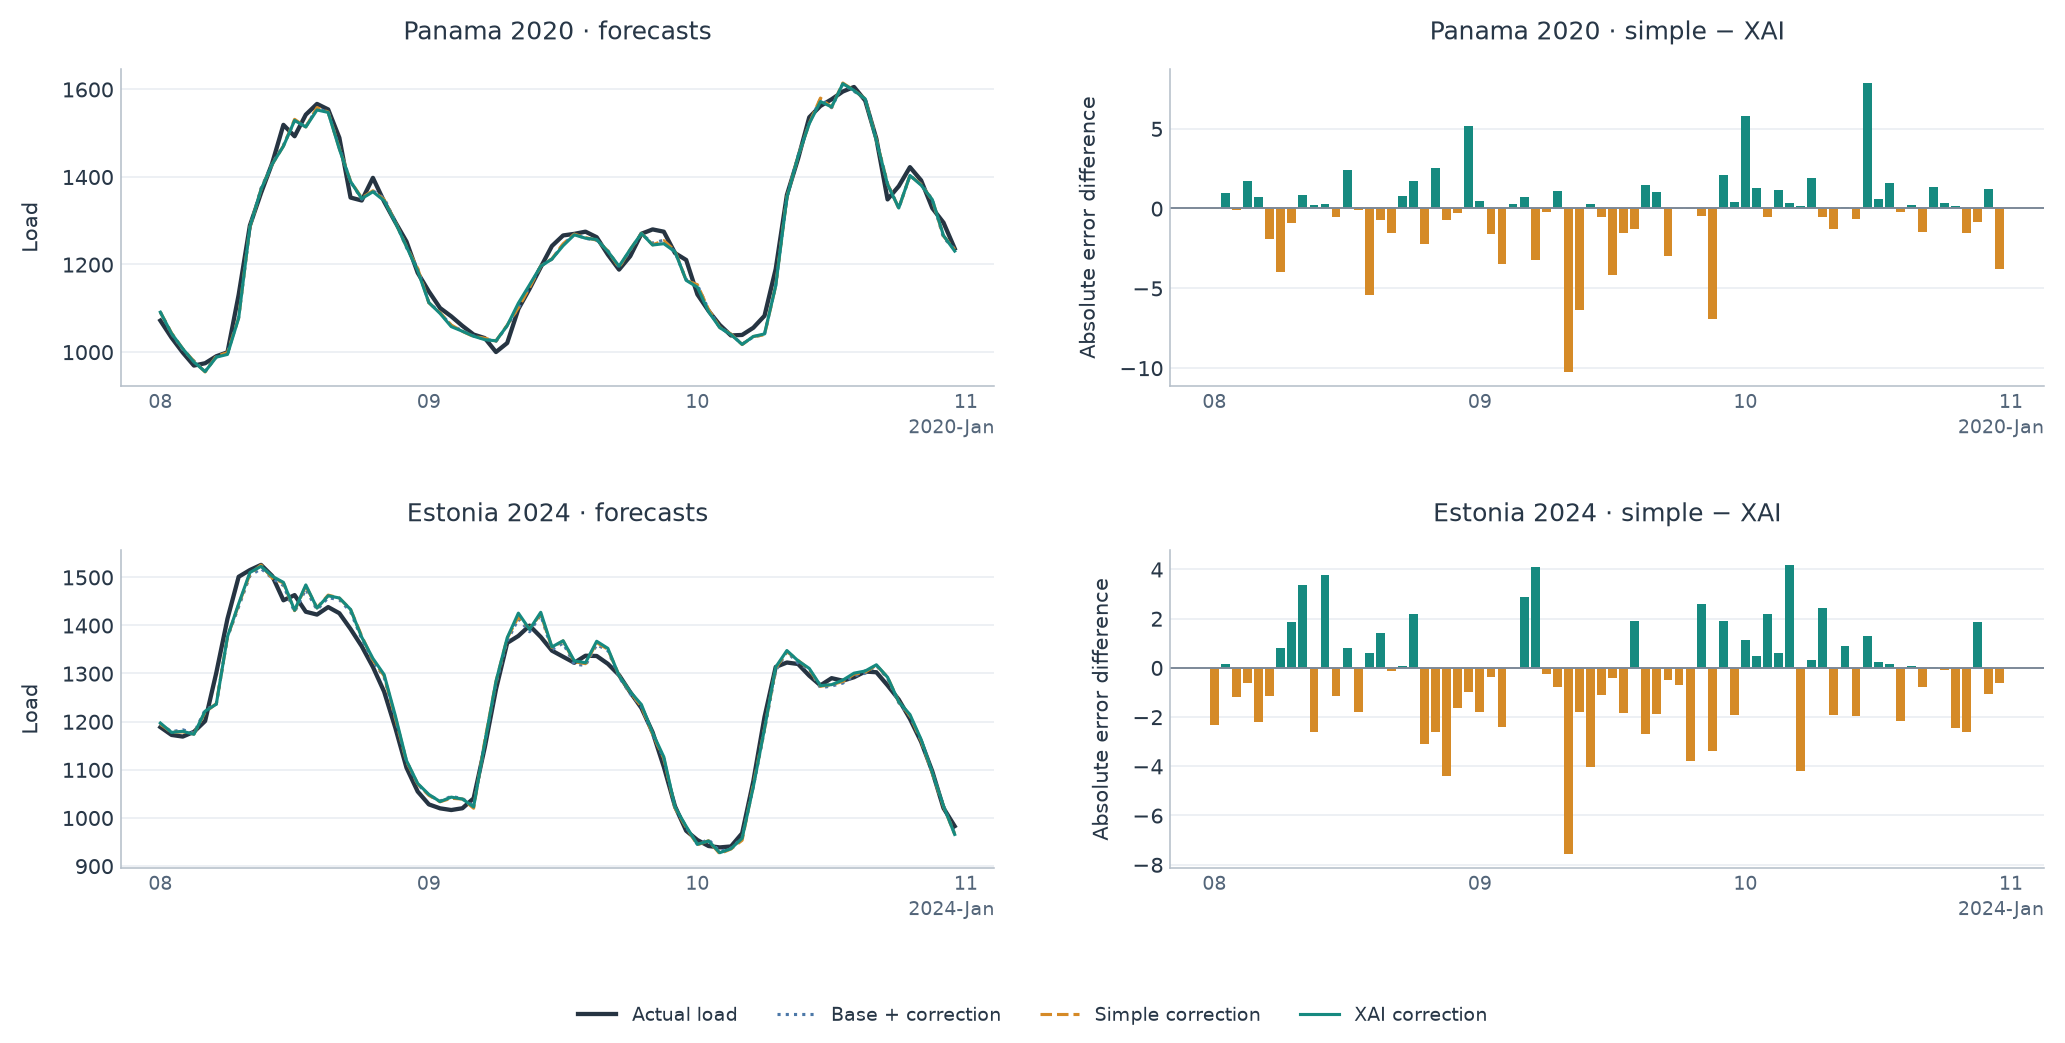

In [21]:
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(len(DATASETS), 2, figsize=(15, 7.5), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        frame, forecasts = runs[dataset]['frame'], runs[dataset]['forecasts']
        start = frame.target_time.min() + pd.Timedelta(days=EXAMPLE_OFFSET_DAYS)
        mask = frame.target_time.ge(start) & frame.target_time.lt(start + pd.Timedelta(days=EXAMPLE_DAYS))
        times = frame.loc[mask, 'target_time']
        y = frame.target_next_hour.to_numpy()
        axes[row, 0].plot(times, y[mask], color='#263442', label='Actual load', linewidth=2.2)
        for method, style in [('residual', ':'), ('hourly_bias', '--'), ('credit_feedback', '-')]:
            axes[row, 0].plot(times, forecasts[method][mask], color=PLOT_COLORS[method],
                             label=PLOT_LABELS[method], linestyle=style, linewidth=1.6)
        axes[row, 0].set(title=f'{PLOT_TITLES[dataset]} · forecasts', ylabel='Load')
        delta = abs(forecasts['hourly_bias'] - y) - abs(forecasts['credit_feedback'] - y)
        axes[row, 1].bar(times, delta[mask], width=0.8 / 24,
            color=np.where(delta[mask] >= 0, PLOT_COLORS['credit_feedback'], PLOT_COLORS['hourly_bias']))
        axes[row, 1].axhline(0, color='#7c8998', linewidth=1)
        axes[row, 1].set(title=f'{PLOT_TITLES[dataset]} · simple − XAI', ylabel='Absolute error difference')
        for ax in axes[row]:
            analysis_dates(ax)
            analysis_grid(ax, 'y')
    fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='lower center', ncol=4)
    fig.tight_layout(pad=1.8, h_pad=3, w_pad=3, rect=(0, 0.07, 1, 1))
    plt.show()


## 16. XAI-osade kaalud
Kaal **1** kasutab osa täielikult, **0** jätab selle välja. Keskmine kaal ei näita tunnuse tähtsust ega füüsikalist põhjust. Vastassuunalised osad võivad üksteist tasakaalustada.


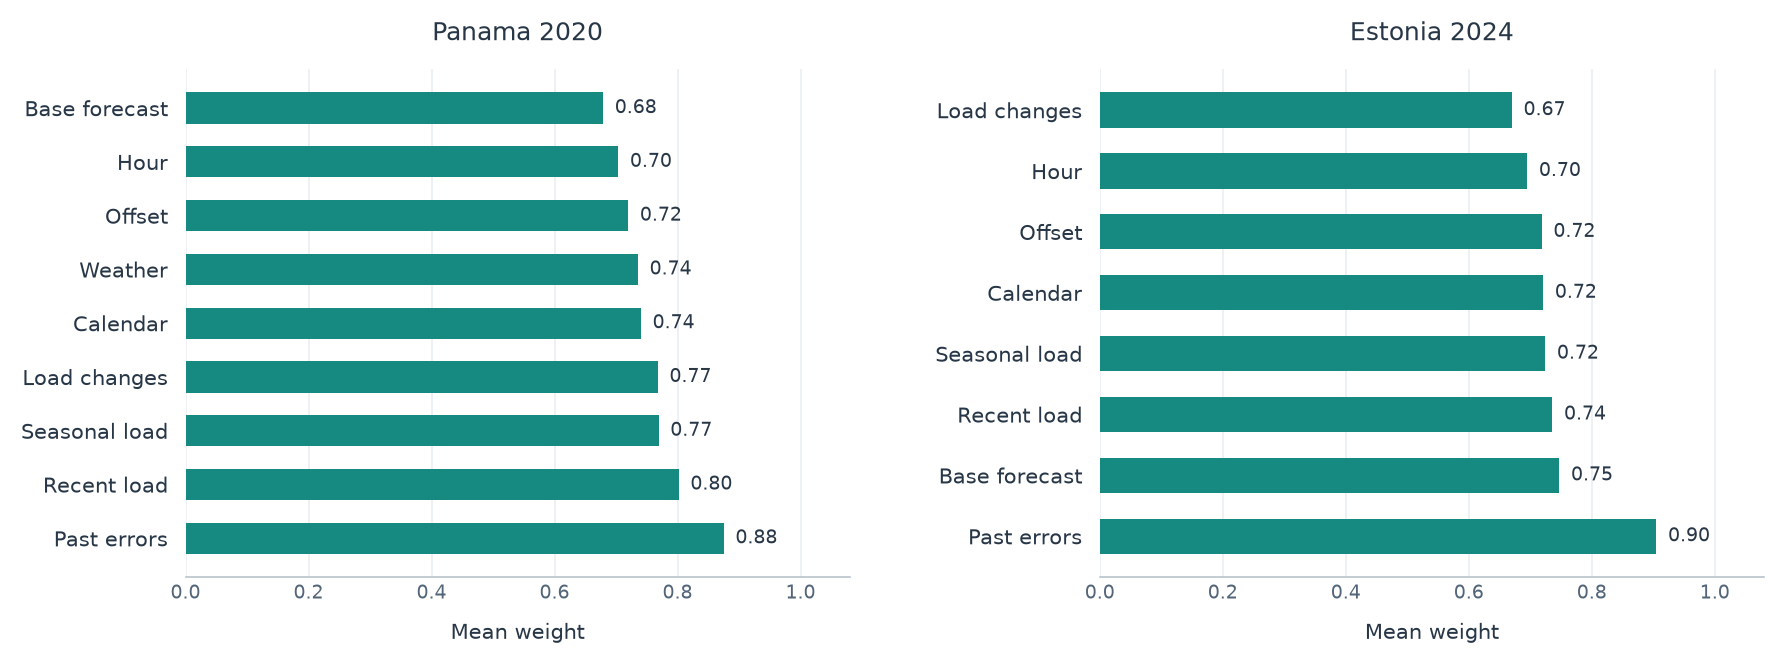

In [22]:
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(13, 5), squeeze=False)
    for col, dataset in enumerate(DATASETS):
        average_weights = runs[dataset]['weights'].mean().sort_values()
        ax = axes[0, col]
        analysis_barh(ax, [PLOT_GROUPS.get(name, name) for name in average_weights.index],
                      average_weights, PLOT_COLORS['credit_feedback'])
        ax.set(xlim=(0, 1.08), title=PLOT_TITLES[dataset], xlabel='Mean weight')
    fig.tight_layout(pad=1.8, w_pad=4)
    plt.show()


## 17. Kolme XAI-meetodi võrdlus
Uurime, kuidas selgitaja valik mõjutab paranduse täpsust ja arvutusaega.

| Meetod | Mida see teeb? |
|---|---|
| TreeSHAP | Arvutab tunnuste panused puumudeli struktuuri ja treeningujaotuse põhjal. |
| LIME | Sobitab mudeli ümber lokaalse lineaarse lähenduse. |
| Tunnuserühmade asendamine | Asendab ühe rühma treeningust võetud väärtustega ja mõõdab prognoosi muutust. Tulemus keskmistatakse üle taustaridade. |

Allikad: [TreeSHAP](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html), [LIME](https://github.com/marcotcr/lime), [asendamise põhimõte](https://captum.ai/api/feature_ablation.html).

Kõigil on **sama treenitud parandusmudel, hindamistunnid, tunnusterühmad ja krediidipõhine kaalureegel**. Uut prognoosimudelit ei treeni. TreeSHAP-i ja LIME-i tunnusepanused liidame samadesse rühmadesse. LIME kasutab kõiki tunnuseid: pideva tunnuse panus on kordaja × skaleeritud sisend. Asendamisel võtame ühe rühma tunnused koos samalt taustarealt.

**Selgitamata osa.** TreeSHAP-i osade summa taastab mudeli prognoosi. LIME-i lähendus ja asendamise panused ei pruugi seda teha. Seetõttu arvutame eraldi:

`selgitamata osa = mudeli väljund − vabaliige − panuste summa`.

See osa jääb prognoosis muutmata. Kaalume ainult panuseid ja vabaliiget. Krediidi lähteprognoos on baasprognoos koos muutmata selgitamata osaga. Ilma kaalumiseta peavad kõik kolm andma sama parandusmudeli prognoosi.

Kui $g_t=\sum_j c_{jt}+u_t$, siis lõppprognoos on $b_t+u_t+\sum_j w_{jt}c_{jt}$. Siin on $b_t$ baasprognoos, $c_{jt}$ selgituse osad koos vabaliikmega ja $u_t$ selgitamata osa. Kaalud $w_{jt}$ tulevad varasematest tulemustest ning jäävad vahemikku 0–1. TreeSHAP-il on $u_t$ vaid ümardusviga; teistel võib see olla suur.

Kontrolltabel näitab selgitamata osa **enne** selle lisamist. Täpne summa pärast lisamist kontrollib ühendamisreeglit, mitte selgituse täpsust. Asendamisel võivad koosmõjud jääda jaotamata või korduda mitmes panuses; vahe suurus üksi ei näita selgituse kvaliteeti. Vabaliige on kaalutav osa, kuid mitte füüsiline sisendtunnus.

TreeSHAP-i vabaliige tuleb puudest, LIME-i oma lokaalsest lähendusest ja asendamise oma taustaprognooside keskmisest. LIME-i skaalad, kategooriate sagedused ja asendamise taust tulevad ainult treeningust. Binaarsed tunnused on LIME-is kategoorilised. Teiste tunnuste sõltumatu muutmine võib tekitada ebatavalisi kombinatsioone.

Valimite suurused ja juhuseemned on fikseeritud. Ühised parandajaseaded valiti TreeSHAP-i arenduses; iga selgitajat eraldi ei häälesta. Võrdleme seega selgitaja ja ühendamisreegli kooslust nendes seadetes. Varem nähtud perioodide tulemus ei määra universaalselt parimat XAI-meetodit ega mõõda selgituste arusaadavust inimesele.


In [23]:
xai_runs, xai_metric_parts, xai_time_parts, xai_check_parts = {}, [], [], []
with threadpool_limits(limits=cfg["workers"]):
    for dataset in DATASETS:
        run = runs[dataset]
        print(COUNTRIES[dataset], "— kolm XAI-meetodit", flush=True)
        compared = compare_explainers(
            run["residual_model"], run["training"], run["frame"], run["inputs"],
            choices["credit_feedback"]["setting"], choices["hourly_bias"]["setting"], cfg["feedback"],
            options=XAI_OPTIONS, seed=cfg["seed"], progress=True,
        )
        np.testing.assert_allclose(compared["forecasts"]["tree_shap"],
                                   run["forecasts"]["credit_feedback"], rtol=1e-10, atol=1e-8)
        np.testing.assert_allclose(compared["forecasts"]["hourly_bias"],
                                   run["forecasts"]["hourly_bias"], rtol=1e-10, atol=1e-8)
        assert compared["background_last_target"] <= run["frame"].origin_time.min()
        xai_runs[dataset] = compared
        xai_metric_parts.append(score_forecasts(
            run["frame"], compared["forecasts"], run["thresholds"], cfg, "final"
        ).assign(dataset=dataset))
        xai_time_parts.append(compared["timing"].assign(dataset=dataset))
        xai_check_parts.append(compared["checks"].assign(dataset=dataset))
        print("Hinnatud tunde:", len(run["frame"]), "| asendamise taustaridu:",
              len(compared["background"]), "| viimane tausta sihtaeg:", compared["background_last_target"])

xai_metrics = pd.concat(xai_metric_parts, ignore_index=True)
xai_timing = pd.concat(xai_time_parts, ignore_index=True)
xai_checks = pd.concat(xai_check_parts, ignore_index=True)
xai_overall = xai_metrics[xai_metrics.scope.eq("overall") & xai_metrics.method.ne("base")].copy()
print("Parandajate ühised seaded:", choices["credit_feedback"]["setting"])
quality_view = xai_checks.assign(Andmestik=lambda x: x.dataset.map(COUNTRIES),
                                 Meetod=lambda x: x.method.map(XAI_LABELS))
display(quality_view[["Andmestik", "Meetod", "n", "native_gap_mae", "native_gap_max_abs",
                      "lime_local_r2_mean", "lime_local_r2_min"]].rename(columns={
    "n": "Tunde", "native_gap_mae": "Selgitamata osa MAE", "native_gap_max_abs": "Suurim absoluutne osa",
    "lime_local_r2_mean": "LIME keskmine R²", "lime_local_r2_min": "LIME väikseim R²",
}))
display(quality_view[["Andmestik", "Meetod", "reconstruction_max_abs"]].assign(
    reconstruction_max_abs=lambda x: x.reconstruction_max_abs.map("{:.2e}".format)
).rename(columns={"reconstruction_max_abs": "Taastamise suurim viga pärast osa lisamist"}))
print("LIME-i R² näitab lähenduse sobivust häiritud sisenditel, mitte koormusprognoosi täpsust.")


Panama — kolm XAI-meetodit


  tree_shap: 4273 rows


  tree_shap: done in 1.34s


  lime: 4273 rows


  LIME 512/4273


  LIME 1024/4273


... (34 outputs left out)

Hinnatud tunde: 8654 | asendamise taustaridu: 32 | viimane tausta sihtaeg: 2023-11-25 00:00:00
Parandajate ühised seaded: {'window_hours': 168, 'by_hour': True, 'strength': 1.0}


,Andmestik,Meetod,Tunde,Selgitamata osa MAE,Suurim absoluutne osa,LIME keskmine R²,LIME väikseim R²
0,Panama,TreeSHAP,4273,0.0000,0.0000,NaN,NaN
1,Panama,LIME,4273,7.2113,46.0802,0.5742,0.3194
2,Panama,Asendamine,4273,6.0111,61.8276,NaN,NaN
3,Eesti,TreeSHAP,8654,0.0000,0.0000,NaN,NaN
4,Eesti,LIME,8654,3.6891,34.8262,0.8018,0.4836
5,Eesti,Asendamine,8654,5.5501,58.3847,NaN,NaN


,Andmestik,Meetod,Taastamise suurim viga pärast osa lisamist
0,Panama,TreeSHAP,0.00e+00
1,Panama,LIME,3.55e-15
2,Panama,Asendamine,3.55e-15
3,Eesti,TreeSHAP,0.00e+00
4,Eesti,LIME,3.55e-15
5,Eesti,Asendamine,3.55e-15


LIME-i R² näitab lähenduse sobivust häiritud sisenditel, mitte koormusprognoosi täpsust.


## 18. Täpsus ja arvutusaeg
Lisaaeg sisaldab selgitaja ettevalmistust, tema mudelipäringuid, selgitamata osa arvutamist, kontrolle ja kaalumist. Ühine mudelite treening ning esialgne baas- ja parandusprognoos on välja jäetud. Lihtsal meetodil mõõdame ainult lisaparandust; tavalisel parandusmudelil eraldi lisakulu pole.

Graafik näitab kogu perioodi lisaarvutusaega sekundites lineaarsel skaalal. Tabeli aeg prognoosi kohta on selle keskmine, mitte eraldi mõõdetud reaalaja viivitus. Täpsust hindame kõigil ühistel tundidel.

MAE paranemine on parandusmudeli suhtes; positiivne protsent tähendab väiksemat viga. Kahjulike tundide osakaalu alus on baasprognoos. Keskmine viga on prognoos miinus tegelik koormus.


,Andmestik,Meetod,Tunde,MAE,RMSE,Keskmine viga,MAE paranemine (%),Halvenenud tunde (%),Lisaaeg (s),Keskmine lisaaeg (ms/tund)
0,Panama,Jääkparandus,4273,16.6506,22.2651,0.9595,0.0000,37.2104,NaN,NaN
1,Panama,Lihtne,4273,15.7702,21.1909,0.7312,5.2875,35.3850,0.0171,0.0040
2,Panama,TreeSHAP,4273,15.7765,21.2161,0.2676,5.2498,34.0042,1.3363,0.3127
3,Panama,LIME,4273,15.9569,21.4219,-0.0668,4.1661,37.9593,32.9712,7.7162
4,Panama,Asendamine,4273,15.8016,21.2928,0.3252,5.0990,36.3211,3.7511,0.8779
5,Eesti,Jääkparandus,8654,16.5901,24.3281,1.9621,0.0000,34.7007,NaN,NaN
6,Eesti,Lihtne,8654,16.0655,23.5303,1.4798,3.1623,34.1923,0.0227,0.0026
7,Eesti,TreeSHAP,8654,16.0589,23.4745,1.5829,3.2017,35.1167,2.6428,0.3054
8,Eesti,LIME,8654,16.0822,23.5203,1.0999,3.0611,35.3709,64.1539,7.4132
9,Eesti,Asendamine,8654,16.0890,23.4504,0.8654,3.0206,35.9602,6.7834,0.7838


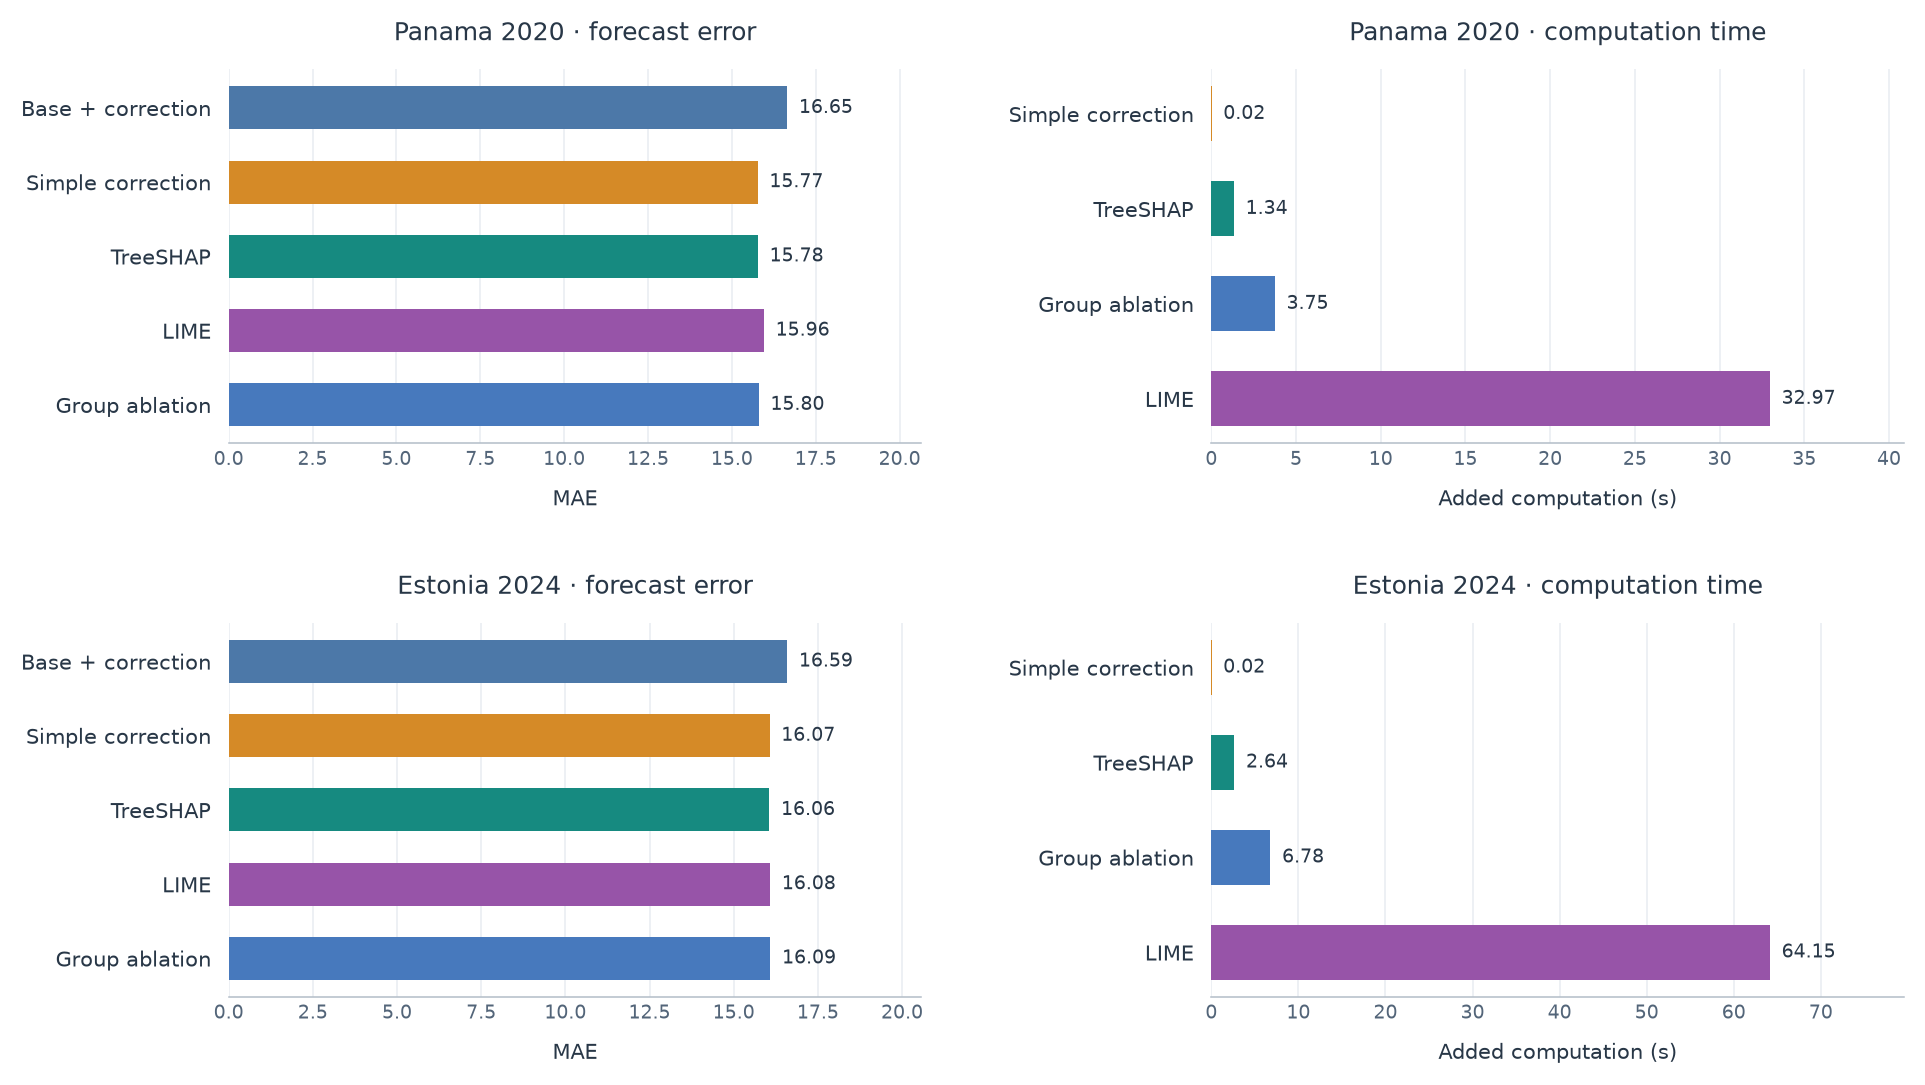

In [24]:
xai_view = xai_overall.merge(
    xai_timing[["dataset", "method", "total_seconds", "ms_per_forecast"]],
    on=["dataset", "method"], how="left",
).assign(Andmestik=lambda x: x.dataset.map(COUNTRIES), Meetod=lambda x: x.method.map(XAI_LABELS))
xai_view["Halvenenud tunde (%)"] = 100 * xai_view.harmful_rate_vs_base
display(xai_view[["Andmestik", "Meetod", "n", "MAE", "RMSE", "bias",
                  "improvement_vs_residual_pct", "Halvenenud tunde (%)",
                  "total_seconds", "ms_per_forecast"]].rename(columns={
    "n": "Tunde", "bias": "Keskmine viga", "improvement_vs_residual_pct": "MAE paranemine (%)",
    "total_seconds": "Lisaaeg (s)", "ms_per_forecast": "Keskmine lisaaeg (ms/tund)",
}))
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(len(DATASETS), 2, figsize=(14, 8), squeeze=False)
    for row, dataset in enumerate(DATASETS):
        values = xai_overall[xai_overall.dataset.eq(dataset)]
        analysis_barh(axes[row, 0], [PLOT_LABELS[m] for m in values.method], values.MAE,
                      [PLOT_COLORS[m] for m in values.method])
        axes[row, 0].set(title=f'{PLOT_TITLES[dataset]} · forecast error', xlabel='MAE')
        times = xai_timing[xai_timing.dataset.eq(dataset)].set_index('method')
        order = ['hourly_bias', 'tree_shap', 'feature_ablation', 'lime']
        times = times.loc[order]
        analysis_barh(axes[row, 1], [PLOT_LABELS[m] for m in order], times.total_seconds,
                      [PLOT_COLORS[m] for m in order])
        axes[row, 1].set(title=f'{PLOT_TITLES[dataset]} · computation time', xlabel='Added computation (s)')
    fig.tight_layout(pad=1.8, w_pad=4, h_pad=3)
    plt.show()


## 19. Kas XAI-meetodite tulemused erinevad?
Võrdleme kolme XAI-meetodit omavahel ja igaüht lihtsa parandajaga. **Vahe = A absoluutviga − B absoluutviga**; negatiivne soosib A-d.

Bonferroni parandus katab kuus meetodipaari, kaks riiki ja kolm olukorda ehk 36 võrdlust. Põhitulemus kasutab 168 tunni ajaplokke, tundlikkuskontroll 24 tunni plokke.

Tabel näitab üldtulemust. Graafik võrdleb LIME-i ja asendamist TreeSHAP-iga ka kiiretes muutustes. Vahemikud on ligikaudsed ja võrdlus tagasivaateline. Nulli sisaldav vahemik ei tõesta meetodite võrdsust.


In [25]:
xai_interval_rows = []
xai_comparison_count = len(DATASETS) * len(XAI_PAIRS) * 3
for dataset in DATASETS:
    run = runs[dataset]
    frame = run["frame"]
    forecasts = xai_runs[dataset]["forecasts"]
    y = frame.target_next_hour.to_numpy()
    for a, b in XAI_PAIRS:
        difference = abs(forecasts[a] - y) - abs(forecasts[b] - y)
        for scope, mask in scope_masks(frame, run["thresholds"]).items():
            if not mask.any():
                continue
            for block in cfg["evaluation"]["bootstrap_blocks_hours"]:
                xai_interval_rows.append({
                    "dataset": dataset, "A": a, "B": b, "scope": scope, "n": int(mask.sum()),
                    **clock_loss_interval(
                        frame.target_time, difference, mask, block=block,
                        repeats=cfg["evaluation"]["bootstrap_repeats"], seed=cfg["seed"],
                        comparisons=xai_comparison_count,
                    ),
                })
xai_intervals = pd.DataFrame(xai_interval_rows)
xai_primary_intervals = xai_intervals[
    xai_intervals.block_hours.eq(cfg["evaluation"]["primary_block_hours"])
].copy()
display(xai_primary_intervals[xai_primary_intervals.scope.eq("overall")][
    ["dataset", "A", "B", "n", "difference", "adjusted_low", "adjusted_high"]
])
display(xai_metrics[xai_metrics.scope.ne("overall") & xai_metrics.method.isin(XAI_LABELS)][
    ["dataset", "method", "scope", "n", "MAE", "RMSE", "harmful_rate_vs_base"]
])

,dataset,A,B,n,difference,adjusted_low,adjusted_high
1,panama,lime,tree_shap,4273,0.1804,-0.3104,0.6430
7,panama,feature_ablation,tree_shap,4273,0.0251,-0.2724,0.2714
13,panama,feature_ablation,lime,4273,-0.1553,-0.5313,0.2716
19,panama,tree_shap,hourly_bias,4273,0.0063,-0.1628,0.1742
25,panama,lime,hourly_bias,4273,0.1867,-0.3299,0.6742
31,panama,feature_ablation,hourly_bias,4273,0.0314,-0.2960,0.3059
37,estonia,lime,tree_shap,8654,0.0233,-0.1326,0.1583
43,estonia,feature_ablation,tree_shap,8654,0.0300,-0.0757,0.1315
49,estonia,feature_ablation,lime,8654,0.0067,-0.1698,0.2095
55,estonia,tree_shap,hourly_bias,8654,-0.0065,-0.1944,0.1562


,dataset,method,scope,n,MAE,RMSE,harmful_rate_vs_base
4,panama,residual,rapid_increase,72,23.6682,33.2959,0.4583
5,panama,residual,rapid_decrease,137,26.7330,34.5542,0.6058
7,panama,hourly_bias,rapid_increase,72,23.1300,32.8417,0.4861
8,panama,hourly_bias,rapid_decrease,137,26.7858,34.5369,0.6058
10,panama,tree_shap,rapid_increase,72,23.2331,32.5053,0.4444
11,panama,tree_shap,rapid_decrease,137,26.2101,34.2528,0.5766
13,panama,lime,rapid_increase,72,23.4772,32.8366,0.4861
14,panama,lime,rapid_decrease,137,27.1749,35.3195,0.5693
16,panama,feature_ablation,rapid_increase,72,23.3834,32.2419,0.4444
17,panama,feature_ablation,rapid_decrease,137,26.5918,34.7731,0.5255


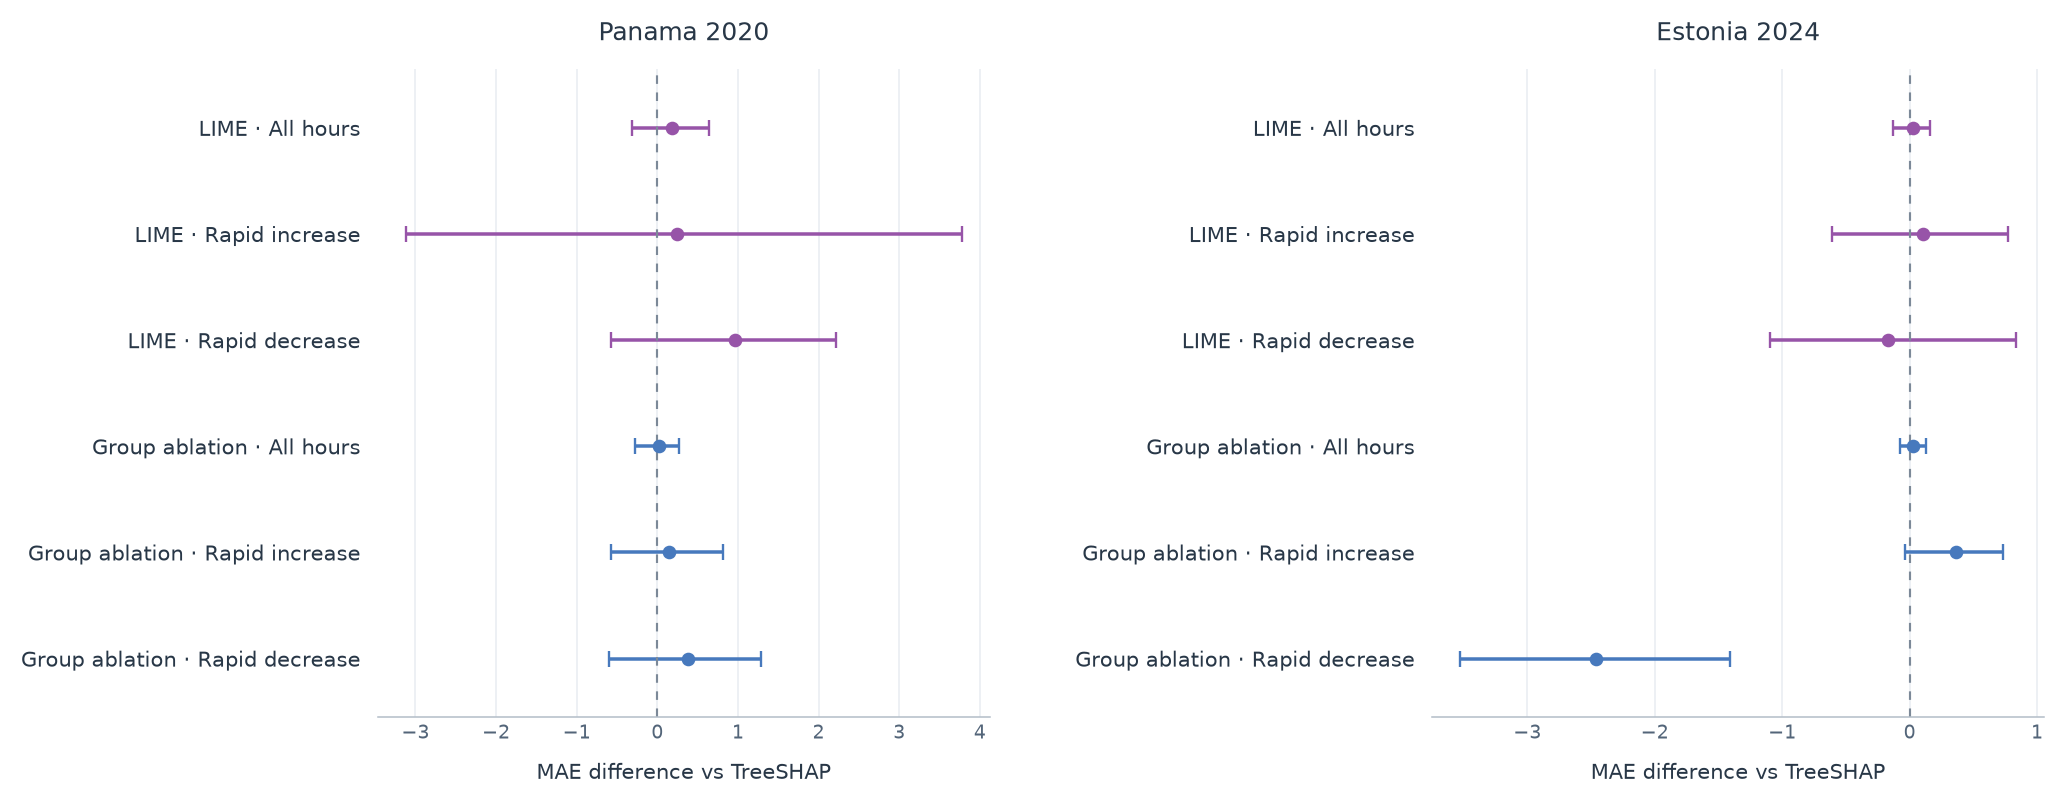

In [26]:
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(15, 6), squeeze=False)
    for col, dataset in enumerate(DATASETS):
        values = xai_primary_intervals[
            xai_primary_intervals.dataset.eq(dataset) & xai_primary_intervals.B.eq('tree_shap')]
        labels = [f'{PLOT_LABELS[a]} · {PLOT_SCOPES[s]}' for a, s in zip(values.A, values.scope)]
        ax = axes[0, col]
        analysis_intervals(ax, values, labels, [PLOT_COLORS[m] for m in values.A])
        ax.set(title=PLOT_TITLES[dataset], xlabel='MAE difference vs TreeSHAP')
    fig.tight_layout(pad=1.8, w_pad=4)
    plt.show()


## 20. Arvutusaja kordused ja selgituste stabiilsus
Kordame ajamõõtmist samadel üle perioodi ühtlaselt valitud ridadel. Aeg sisaldab selgitaja ettevalmistust, mistõttu väikese valimi kulu ei pruugi kasvada kogu perioodile otse võrdeliselt.

Stabiilsuskontrollis muudame ainult juhuseemet. LIME-is muutuvad häiritud sisendid, asendamisel treeningust valitud taust. TreeSHAP on siin deterministlik kontroll. Mõõdame panuste ja selgitamata osa muutust. Põhiseemnega peab valim kattuma kogu perioodi vastavate ridadega.

See kontroll näitab selgituste tundlikkust juhuslikkusele. See ei mõõda kogu kohanduva prognoosi stabiilsust ega vali uut meetodit. Kogu perioodi prognoosidel on üks ette määratud põhiseeme.


In [27]:
timing_repeats, stability_rows = [], []
with threadpool_limits(limits=cfg["workers"]):
    for dataset in DATASETS:
        run, compared = runs[dataset], xai_runs[dataset]
        count = min(XAI_OPTIONS["benchmark_rows"], len(run["frame"]))
        positions = np.linspace(0, len(run["frame"]) - 1, count, dtype=int)
        sample = run["frame"][run["inputs"]].iloc[positions]
        for method in EXPLAINERS:
            for repeat in range(XAI_OPTIONS["timing_repeats"]):
                _, _, info = explain_components(
                    run["residual_model"], sample, method, run["training"],
                    options=XAI_OPTIONS, seed=cfg["seed"],
                )
                timing_repeats.append({"dataset": dataset, "method": method, "repeat": repeat + 1,
                                      "n": count, "seconds": info["explanation_seconds"]})
            reference = compared["components"][method].iloc[positions]
            fixed_reference = compared["remainders"][method].iloc[positions]
            for seed in XAI_OPTIONS["stability_seeds"]:
                components, remainder, info = explain_components(
                    run["residual_model"], sample, method, run["training"], options=XAI_OPTIONS, seed=seed
                )
                difference = np.abs(components.to_numpy() - reference.to_numpy())
                stability_rows.append({"dataset": dataset, "method": method, "seed": seed, "n": count,
                                       "mean_abs_component_change": float(difference.mean()),
                                       "max_abs_component_change": float(difference.max()),
                                       "mean_abs_remainder_change": float(abs(remainder - fixed_reference).mean()),
                                       "native_gap_mae": info["native_gap_mae"]})
                if seed == cfg["seed"]:
                    np.testing.assert_allclose(components, reference, atol=1e-8, rtol=1e-9)
                    np.testing.assert_allclose(remainder, fixed_reference, atol=1e-8, rtol=1e-9)
timing_repeats = pd.DataFrame(timing_repeats)
xai_stability = pd.DataFrame(stability_rows)
runtime_summary = timing_repeats.groupby(["dataset", "method"]).agg(
    n=("n", "first"), repeats=("repeat", "count"),
    median_seconds=("seconds", "median"), min_seconds=("seconds", "min"), max_seconds=("seconds", "max"),
).reset_index()
runtime_summary["median_ms_per_forecast"] = 1000 * runtime_summary.median_seconds / runtime_summary.n
display(runtime_summary.assign(dataset=lambda x: x.dataset.map(COUNTRIES),
                               method=lambda x: x.method.map(XAI_LABELS)).rename(columns={
    "dataset": "Andmestik", "method": "Meetod", "n": "Tunde", "repeats": "Kordusi",
    "median_seconds": "Mediaanaeg (s)", "min_seconds": "Vähim aeg (s)", "max_seconds": "Suurim aeg (s)",
    "median_ms_per_forecast": "Mediaan (ms/tund)",
}))
display(xai_stability.assign(dataset=lambda x: x.dataset.map(COUNTRIES),
                             method=lambda x: x.method.map(XAI_LABELS)).rename(columns={
    "dataset": "Andmestik", "method": "Meetod", "seed": "Seeme", "n": "Tunde",
    "mean_abs_component_change": "Panuste keskmine muutus", "max_abs_component_change": "Suurim muutus",
    "mean_abs_remainder_change": "Selgitamata osa muutus", "native_gap_mae": "Selgitamata osa MAE",
}))
from importlib.metadata import version
print("Keskkond: Python", sys.version.split()[0], "| SHAP", version("shap"), "| LIME", version("lime"),
      "| arvutuslõimede piir", cfg["workers"])
print("Asendamise taustaridu:", XAI_OPTIONS["background_size"], "| LIME-i proove:", XAI_OPTIONS["lime_samples"],
      "| põhiseeme:", cfg["seed"])


,Andmestik,Meetod,Tunde,Kordusi,Mediaanaeg (s),Vähim aeg (s),Suurim aeg (s),Mediaan (ms/tund)
0,Eesti,Asendamine,64,3,0.0652,0.0638,0.0678,1.0194
1,Eesti,LIME,64,3,0.4961,0.4896,0.5112,7.7518
2,Eesti,TreeSHAP,64,3,0.0555,0.0541,0.0561,0.8666
3,Panama,Asendamine,64,3,0.0720,0.0703,0.0727,1.1245
4,Panama,LIME,64,3,0.5333,0.5124,0.5567,8.3321
5,Panama,TreeSHAP,64,3,0.0559,0.0526,0.0652,0.8728


,Andmestik,Meetod,Seeme,Tunde,Panuste keskmine muutus,Suurim muutus,Selgitamata osa muutus,Selgitamata osa MAE
0,Panama,TreeSHAP,42,64,0.0000,0.0000,0.0000,0.0000
1,Panama,TreeSHAP,43,64,0.0000,0.0000,0.0000,0.0000
2,Panama,TreeSHAP,44,64,0.0000,0.0000,0.0000,0.0000
3,Panama,LIME,42,64,0.0000,0.0000,0.0000,7.7573
4,Panama,LIME,43,64,1.6102,13.3859,1.1736,7.5128
5,Panama,LIME,44,64,1.5038,18.0328,0.9723,7.7320
6,Panama,Asendamine,42,64,0.0000,0.0000,0.0000,5.8875
7,Panama,Asendamine,43,64,1.1811,4.8712,2.6043,5.7494
8,Panama,Asendamine,44,64,1.4065,6.1710,3.7276,7.0661
9,Eesti,TreeSHAP,42,64,0.0000,0.0000,0.0000,0.0000


Keskkond: Python 3.11.2 | SHAP 0.51.0 | LIME 0.2.0.1 | arvutuslõimede piir 2
Asendamise taustaridu: 32 | LIME-i proove: 512 | põhiseeme: 42


## 21. Eesti 2025: mudelite treening
2024 põhivõrdlus jääb eraldi. Lisakatses kasutame 2025 aastat, treenides baas- ja parandusmudeli ainult varasematel andmetel. Parandusmudel õpib ajapõhistest OOF-vigadest; 2024 võib nüüd olla treeningus.

Kiirete muutuste piirid jäävad samaks nagu Eesti põhivõrdluses: need arvutati enne 2021 aastat. Kõigil meetoditel on samad mudelid, tunnused ja hindamistunnid. Aasta jooksul mudelid ei muutu; tagasiside kasutab ainult juba saabunud tulemusi. Ajajoon ja aastajaotus on UTC-s, kellaajarühmad Tallinna ajas.


In [28]:
confirmation_cfg = deepcopy(cfg)
confirmation_year = combined_protocol["test_year"]
confirmation_cfg["datasets"]["estonia"]["test_year"] = confirmation_year
with threadpool_limits(limits=cfg["workers"]):
    frame_2025, quality_2025 = load_dataset(
        ROOT / cfg["datasets"]["estonia"]["path"], confirmation_cfg, "estonia"
    )
    base_columns_2025, correction_columns_2025 = feature_columns("estonia")
    history_2025 = oof_history(frame_2025, confirmation_year, base_columns_2025, confirmation_cfg)
    hold_2025 = annual_forecast(frame_2025, confirmation_year, base_columns_2025, confirmation_cfg)
    joined_2025 = pd.concat([history_2025.drop(columns=ERROR_FEATURES), hold_2025], ignore_index=True)
    joined_2025 = pd.concat([joined_2025, known_error_features(joined_2025)], axis=1)
    train_2025, valid_2025 = split_year(joined_2025, confirmation_year)
    fitted_2025, components_2025, inputs_2025 = residual_forecasts(
        train_2025, valid_2025, correction_columns_2025, confirmation_cfg
    )
    valid_2025["prediction_residual"] = fitted_2025["residual"]
    combined_predictions = combined_forecasts(
        valid_2025, components_2025, combined_protocol["xai_setting"],
        combined_protocol["bias_setting"], combined_protocol["feedback"],
    )
combined_predictions["naive"] = persistence_forecast(valid_2025)
thresholds_2025 = deepcopy(runs["estonia"]["thresholds"])
assert train_2025.target_time.max() <= valid_2025.origin_time.min()
assert train_2025.target_time.dt.year.max() < confirmation_year
assert set(valid_2025.target_time.dt.year) == {confirmation_year}
assert valid_2025.target_time.is_unique
assert np.isfinite(np.column_stack(list(combined_predictions.values()))).all()
assert combined_protocol == combined_protocol_snapshot
assert cfg["datasets"]["estonia"]["test_year"] == 2024
combined_metrics = score_forecasts(
    valid_2025, combined_predictions, thresholds_2025, confirmation_cfg, "confirmation"
)
display(pd.DataFrame([{
    "Aasta": confirmation_year, "Esimene sihttund": valid_2025.target_time.min(),
    "Viimane sihttund": valid_2025.target_time.max(), "Hinnatud tunde": len(valid_2025),
    "Aasta kalendritunde": quality_2025["calendar_test_hours"],
    "Hindamata tunde": quality_2025["unscored_test_hours"],
    "Viimane treeningu sihtaeg": train_2025.target_time.max(),
    "Tagasiside soojenemine (h)": combined_protocol["feedback"]["warmup_hours"],
}]))


  Base OOF 2019: 8708 forecasts


  Base OOF 2020: 8784 forecasts


  Base OOF 2021: 8760 forecasts


  Base OOF 2022: 8760 forecasts


  Base OOF 2023: 8708 forecasts


  Base OOF 2024: 8654 forecasts


  Base OOF 2025: 8429 forecasts


,Aasta,Esimene sihttund,Viimane sihttund,Hinnatud tunde,Aasta kalendritunde,Hindamata tunde,Viimane treeningu sihtaeg,Tagasiside soojenemine (h)
0,2025,2025-01-01,2025-12-31 23:00:00,8429,8760,331,2024-12-31 23:00:00,72


## 22. Eesti 2025: üldine ja kuine täpsus
„Lihtne” tähendab parandusmudeli prognoosi koos sama kellaaja veaparandusega. „XAI + veaparandus” ja „üks kaal + veaparandus” saavad sama lisakihi, kumbki enda esimese kihi varasemate vigade põhjal.

Siin arvutame MAE paranemise ja kahjulike tundide osakaalu **lihtsa parandaja suhtes**. Negatiivne paranemine tähendab suuremat viga. Kõigil on samad hindamistunnid. Kuuvaade näitab tulemuse püsimist ajas; selle põhjal seadeid ei muuda.


,Meetod,Tunde,MAE,RMSE,Keskmine viga,MAE paranemine (%),Halvenenud tunde (%)
0,Baas,8429,25.0643,36.1626,1.0465,-9.8279,55.1430
3,Jääkparandus,8429,22.8025,32.5782,0.1541,0.0827,48.9145
6,Lihtne,8429,22.8214,32.5570,0.1034,0.0000,0.0000
9,XAI,8429,22.6758,32.3964,0.6456,0.6379,49.0331
12,Üks kaal,8429,22.6377,32.3750,0.4685,0.8050,48.2026
15,XAI + veaparandus,8429,22.7890,32.4875,0.4705,0.1420,51.1211
18,Üks kaal + veaparandus,8429,22.6479,32.3559,0.3362,0.7601,34.3576
21,Naiivne,8429,38.5524,50.9164,0.0627,-68.9311,68.7863


,Meetod,Olukord,n,MAE,RMSE,improvement_vs_simple_pct
1,Baas,Kiire tõus,409,43.1443,58.9000,-17.0023
2,Baas,Kiire langus,419,75.2787,89.7451,-27.8175
4,Jääkparandus,Kiire tõus,409,37.5663,50.6696,-1.8754
5,Jääkparandus,Kiire langus,419,59.8389,72.3576,-1.6019
7,Lihtne,Kiire tõus,409,36.8748,49.8676,0.0000
8,Lihtne,Kiire langus,419,58.8955,71.4303,0.0000
10,XAI,Kiire tõus,409,36.6223,49.6806,0.6846
11,XAI,Kiire langus,419,60.4917,72.8526,-2.7104
13,Üks kaal,Kiire tõus,409,36.9535,49.9993,-0.2136
14,Üks kaal,Kiire langus,419,60.9964,73.3440,-3.5673


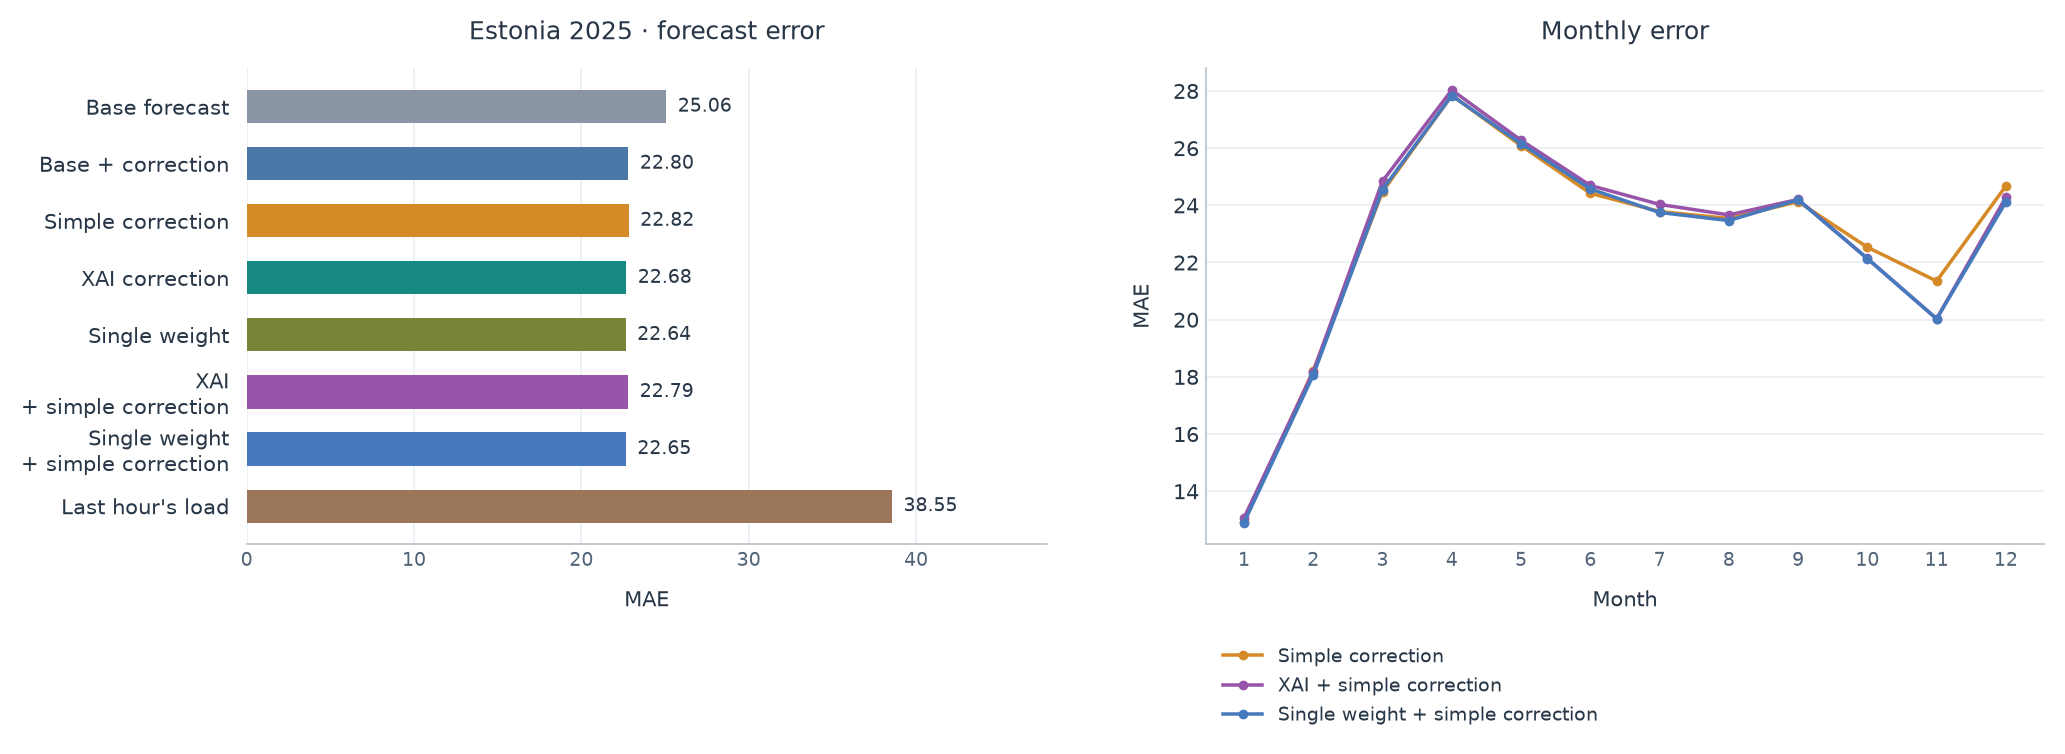

In [29]:
comparison_rows = []
actual_2025 = valid_2025.target_next_hour.to_numpy()
for method, predicted in combined_predictions.items():
    difference = abs(predicted - actual_2025) - abs(combined_predictions["hourly_bias"] - actual_2025)
    for scope, mask in scope_masks(valid_2025, thresholds_2025).items():
        if not mask.any():
            continue
        comparison_rows.append({
            "method": method, "scope": scope,
            "improvement_vs_simple_pct": 100 * (1 - abs(predicted[mask] - actual_2025[mask]).mean()
                / abs(combined_predictions["hourly_bias"][mask] - actual_2025[mask]).mean()),
            "harmful_rate_vs_simple_pct": 100 * (difference[mask] > cfg["evaluation"]["harm_tolerance"]).mean(),
        })
combined_metrics = combined_metrics.merge(pd.DataFrame(comparison_rows), on=["method", "scope"])
combined_overall = combined_metrics[combined_metrics.scope.eq("overall")].copy()
display(combined_overall.assign(Meetod=lambda x: x.method.map(COMBINED_LABELS))[
    ["Meetod", "n", "MAE", "RMSE", "bias", "improvement_vs_simple_pct", "harmful_rate_vs_simple_pct"]
].rename(columns={"n": "Tunde", "bias": "Keskmine viga", "improvement_vs_simple_pct": "MAE paranemine (%)",
                  "harmful_rate_vs_simple_pct": "Halvenenud tunde (%)"}))
display(combined_metrics[combined_metrics.scope.ne("overall")].assign(
    Meetod=lambda x: x.method.map(COMBINED_LABELS), Olukord=lambda x: x.scope.map(scope_labels)
)[["Meetod", "Olukord", "n", "MAE", "RMSE", "improvement_vs_simple_pct"]])
combined_monthly_rows = []
for month, indexes in valid_2025.groupby(valid_2025.target_time.dt.month).groups.items():
    for method in ("hourly_bias", "xai_bias", "scalar_bias"):
        combined_monthly_rows.append({
            "month": month, "method": method,
            "MAE": abs(combined_predictions[method][indexes] - actual_2025[indexes]).mean(),
        })
combined_monthly = pd.DataFrame(combined_monthly_rows)
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={'width_ratios': [1.05, 1.1]})
    analysis_barh(axes[0], [PLOT_LABELS[m] for m in combined_overall.method], combined_overall.MAE,
                  [PLOT_COLORS[m] for m in combined_overall.method])
    axes[0].set(title=f'Estonia {confirmation_year} · forecast error', xlabel='MAE')
    for method in ('hourly_bias', 'xai_bias', 'scalar_bias'):
        values = combined_monthly[combined_monthly.method.eq(method)]
        axes[1].plot(values.month, values.MAE, marker='o', markersize=4,
                     label=PLOT_LABELS[method].replace('\n', ' '), color=PLOT_COLORS[method])
    axes[1].set(title='Monthly error', xlabel='Month', ylabel='MAE', xticks=range(1, 13))
    axes[1].legend(loc='upper left', bbox_to_anchor=(0, -0.18), fontsize=10)
    analysis_grid(axes[1], 'y')
    fig.tight_layout(pad=1.8, w_pad=4, rect=(0, 0.05, 1, 1))
    plt.show()


## 23. Eesti 2025: kas lisakasu on selge?
**Vahe = A absoluutviga − B absoluutviga.** Alla nulli jääv vahemik soosib A-d, üle nulli jääv B-d. Graafik ja kuvatav tabel kasutavad 168 tunni põhiplokki. 24 tunni kontroll on tabelis `combined_intervals`.

Esimesed kaks paari kontrollivad, kas ühendatud XAI-meetod edestab lihtsat parandajat ja sama lisakihiga ühe kaalu kontrolli. Teised kaks näitavad lisakihi mõju kummalegi meetodile. Nulli sisaldav vahemik ei tõesta võrdsust.


,A,B,Olukord,Tunde,MAE vahe,Alumine piir,Ülemine piir
1,XAI + veaparandus,Lihtne,Kõik tunnid,8429,-0.0324,-0.2852,0.1973
3,XAI + veaparandus,Lihtne,Kiire tõus,409,-0.7319,-1.5749,-0.0249
5,XAI + veaparandus,Lihtne,Kiire langus,419,0.5537,-0.3875,1.4654
7,XAI + veaparandus,Üks kaal + veaparandus,Kõik tunnid,8429,0.1411,0.0508,0.2341
9,XAI + veaparandus,Üks kaal + veaparandus,Kiire tõus,409,-0.2150,-0.8072,0.3824
11,XAI + veaparandus,Üks kaal + veaparandus,Kiire langus,419,-0.4145,-0.8896,0.0544
13,XAI + veaparandus,XAI,Kõik tunnid,8429,0.1132,0.0343,0.1943
15,XAI + veaparandus,XAI,Kiire tõus,409,-0.4795,-0.9813,-0.0009
17,XAI + veaparandus,XAI,Kiire langus,419,-1.0426,-1.7736,-0.3096
19,Üks kaal + veaparandus,Üks kaal,Kõik tunnid,8429,0.0103,-0.0701,0.0948


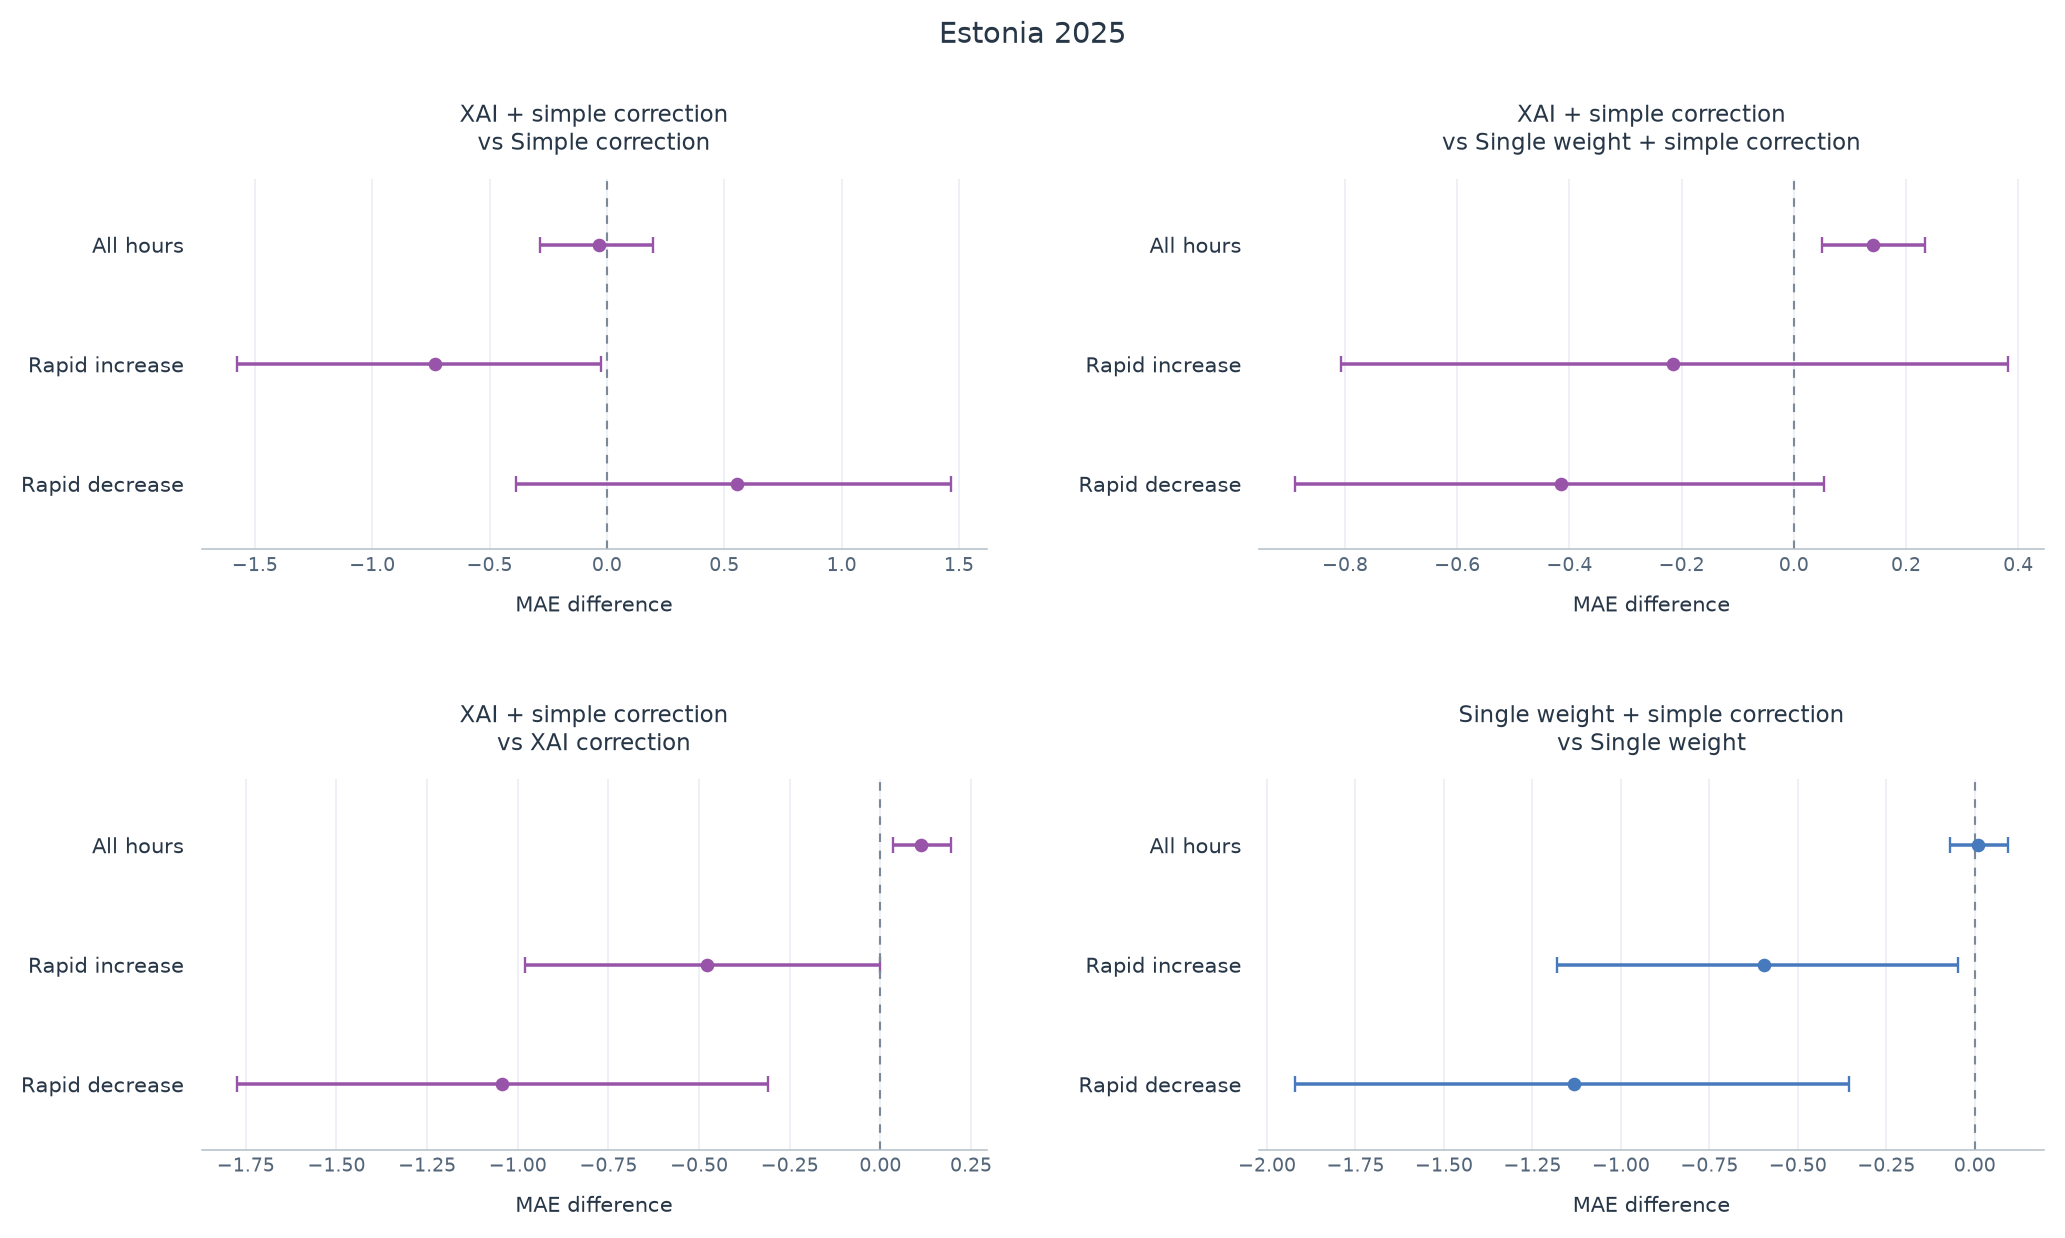

In [30]:
combined_interval_rows = []
combined_comparisons = len(combined_protocol["pairs"]) * 3
for a, b in combined_protocol["pairs"]:
    difference = abs(combined_predictions[a] - actual_2025) - abs(combined_predictions[b] - actual_2025)
    for scope, mask in scope_masks(valid_2025, thresholds_2025).items():
        if not mask.any():
            continue
        for block in combined_protocol["evaluation"]["bootstrap_blocks_hours"]:
            combined_interval_rows.append({
                "A": a, "B": b, "scope": scope, "n": int(mask.sum()),
                **clock_loss_interval(valid_2025.target_time, difference, mask, block=block,
                    repeats=combined_protocol["evaluation"]["bootstrap_repeats"],
                    seed=combined_protocol["seed"], comparisons=combined_comparisons),
            })
combined_intervals = pd.DataFrame(combined_interval_rows)
combined_primary_intervals = combined_intervals[
    combined_intervals.block_hours.eq(combined_protocol["evaluation"]["primary_block_hours"])
].copy()
display(combined_primary_intervals.assign(
    A=lambda x: x.A.map(COMBINED_LABELS), B=lambda x: x.B.map(COMBINED_LABELS),
    scope=lambda x: x.scope.map(scope_labels),
)[["A", "B", "scope", "n", "difference", "adjusted_low", "adjusted_high"]].rename(columns={
    "scope": "Olukord", "n": "Tunde", "difference": "MAE vahe", "adjusted_low": "Alumine piir",
    "adjusted_high": "Ülemine piir",
}))
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    for ax, (a, b) in zip(axes.flat, combined_protocol['pairs']):
        values = combined_primary_intervals[
            combined_primary_intervals.A.eq(a) & combined_primary_intervals.B.eq(b)]
        analysis_intervals(ax, values, values.scope.map(PLOT_SCOPES), PLOT_COLORS[a])
        first, second = PLOT_LABELS[a].replace('\n', ' '), PLOT_LABELS[b].replace('\n', ' ')
        ax.set_title(f'{first}\nvs {second}', fontsize=12)
        ax.set_xlabel('MAE difference')
    fig.suptitle(f'Estonia {confirmation_year}', fontsize=15)
    fig.tight_layout(pad=1.8, w_pad=4, h_pad=4)
    plt.show()

assert combined_protocol == combined_protocol_snapshot
assert choices == selection["choices"]


## 24. Naiivne prognoos võrdluseks
Reegel on **järgmise tunni koormus = viimase lõppenud tunni koormus** (`load_now`). Treenimist pole vaja. Hindame seda samadel täielike sisenditega tundidel nagu teisi meetodeid, kuigi naiivne prognoos võiks muidu katta rohkem tunde.

Positiivne paranemine tähendab väiksemat MAE-d kui naiivsel prognoosil. Lisame selle võrdluse pärast seniste tulemuste vaatamist, ka 2025 puhul. See on kirjeldav lisavõrdlus ega muuda 2025 katse algset nelja paari ja 12 võrdluse plaani.


,Periood,Meetod,Tunde,MAE,RMSE,MAE paranemine naiivsest (%)
0,Panama 2020,Naiivne,4273,38.0704,49.2074,0.0000
1,Panama 2020,Baas,4273,20.4511,27.1860,46.2809
2,Panama 2020,Jääkparandus,4273,16.6506,22.2651,56.2637
3,Panama 2020,Lihtne,4273,15.7702,21.1909,58.5763
4,Panama 2020,XAI,4273,15.7765,21.2161,58.5598
5,Panama 2020,Üks kaal,4273,16.6476,22.2568,56.2715
18,Eesti 2024,Naiivne,8654,37.7394,50.2030,0.0000
19,Eesti 2024,Baas,8654,22.1208,31.5539,41.3853
20,Eesti 2024,Jääkparandus,8654,16.5901,24.3281,56.0404
21,Eesti 2024,Lihtne,8654,16.0655,23.5303,57.4305


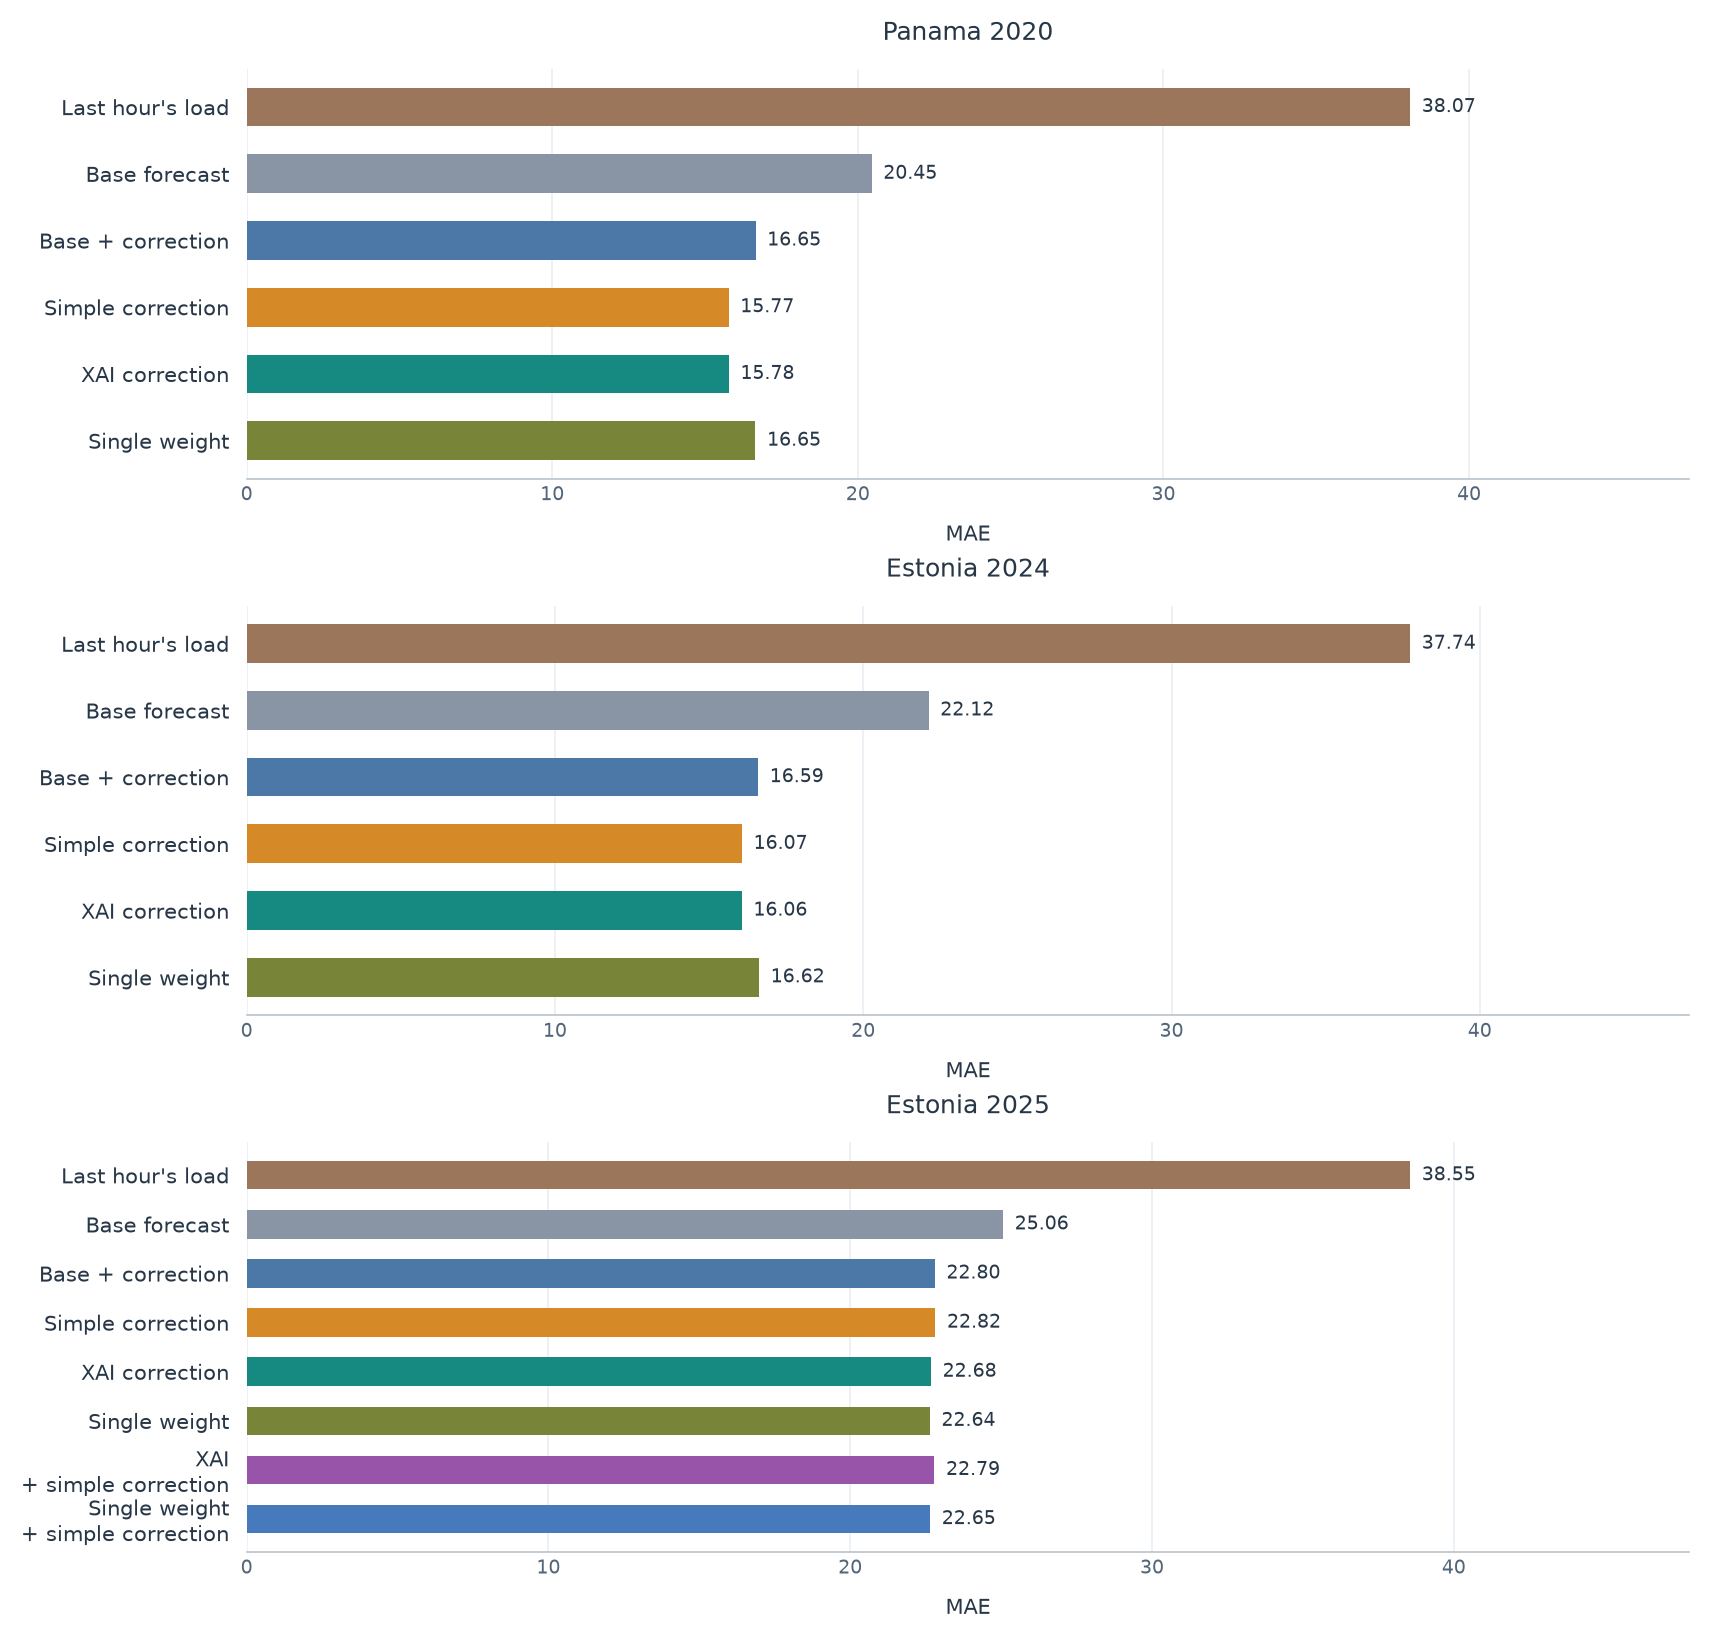

In [31]:
review_runs = {
    f"{COUNTRIES[d]} {cfg['datasets'][d]['test_year']}": {
        "frame": runs[d]["frame"], "forecasts": runs[d]["forecasts"],
        "components": runs[d]["components"], "weights": runs[d]["weights"],
        "thresholds": runs[d]["thresholds"],
    } for d in DATASETS
}
prediction_2025_check, _, weights_2025 = adaptive_correction(
    valid_2025, components_2025, combined_protocol["xai_setting"], "credit", combined_protocol["feedback"]
)
np.testing.assert_allclose(prediction_2025_check, combined_predictions["credit_feedback"], atol=1e-8)
review_runs[f"Eesti {confirmation_year}"] = {
    "frame": valid_2025, "forecasts": combined_predictions, "components": components_2025,
    "weights": weights_2025, "thresholds": thresholds_2025,
}
review_labels = {**LABELS, **COMBINED_LABELS}
benchmark_methods = ("naive", "base", "residual", "hourly_bias", "credit_feedback", "matched_scalar", "xai_bias", "scalar_bias")
naive_rows = []
for cohort, run in review_runs.items():
    frame_review = run["frame"]
    y_review = frame_review.target_next_hour.to_numpy()
    naive_review = persistence_forecast(frame_review)
    np.testing.assert_array_equal(run["forecasts"]["naive"], naive_review)
    for scope, mask in scope_masks(frame_review, run["thresholds"]).items():
        if not mask.any():
            continue
        naive_mae = prediction_metrics(y_review[mask], naive_review[mask])["MAE"]
        for method in benchmark_methods:
            if method not in run["forecasts"]:
                continue
            scores = prediction_metrics(y_review[mask], np.asarray(run["forecasts"][method])[mask])
            naive_rows.append({"cohort": cohort, "method": method, "scope": scope, **scores,
                               "improvement_vs_naive_pct": 100 * (1 - scores["MAE"] / naive_mae) if naive_mae else np.nan})
naive_benchmark = pd.DataFrame(naive_rows)
naive_overall = naive_benchmark[naive_benchmark.scope.eq("overall")]
assert naive_benchmark.groupby(["cohort", "scope"]).n.nunique().eq(1).all()
display(naive_overall.assign(Meetod=lambda x: x.method.map(review_labels))[
    ["cohort", "Meetod", "n", "MAE", "RMSE", "improvement_vs_naive_pct"]
].rename(columns={"cohort": "Periood", "n": "Tunde", "improvement_vs_naive_pct": "MAE paranemine naiivsest (%)"}))
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(len(review_runs), 1, figsize=(12, 11.5), layout='constrained')
    for ax, (cohort, run) in zip(axes, review_runs.items()):
        values = naive_overall[naive_overall.cohort.eq(cohort)]
        analysis_barh(ax, [PLOT_LABELS[m] for m in values.method], values.MAE,
                      [PLOT_COLORS[m] for m in values.method])
        ax.set(title=plot_cohort(cohort), xlabel='MAE')
    plt.show()


## 25. Millal XAI prognoosi muudab ja kas see aitab?
See on olemasolevate prognooside järelanalüüs. Võrdleme XAI-prognoosi sama parandusmudeli kaalumata prognoosiga. Osa muutus on `(kaal − 1) × osa`; kõigi muutuste summa peab võrduma lõppprognoosi muutusega.

Mõõdame osade ja lõppprognoosi muutmise sagedust, muutuse suurust ning kasu või kahju. **Kasu = kaalumata prognoosi absoluutviga − XAI absoluutviga.** Keskmine kasu üle kõigi tundide on MAE paranemine. Paljud väikesed võidud ei pruugi korvata mõnda suurt kaotust.

**Tühistumine** on `1 − |muutuste summa| / absoluutmuutuste summa`. Null tähendab samasuunalisi muutusi, üks täielikku tasakaalustumist. Keskmise leiame ainult tundidel, mil osi muudeti. Ka püsiosa on selles arvutuses osa. Suur tühistumine üksi ei tõesta viga ega põhjuslikku seost.

Abi ja kahju osakaalud käivad **muudetud prognooside kohta**. Kui muutusi pole, jääb osakaal määramata. Ühe kaalu kontroll näitab, kuidas erineb kogu paranduse kaalumine osade eraldi kaalumisest. Uut mudelit nende tulemuste järgi ei vali.


,Periood,Tunde,Komponente muudetud (%),Prognoosi muudetud (%),Keskmine absoluutne muutus,Aitas muudetutest (%),Halvendas muudetutest (%),MAE paranemine jäägiprognoosist,Keskmine tühistumise osakaal
0,Panama 2020,4273,98.2448,98.2448,2.8669,58.2182,41.7818,0.8741,0.2633
1,Eesti 2024,8654,97.8391,97.8391,3.6267,52.6869,47.3131,0.5312,0.1624
2,Eesti 2025,8429,98.1492,98.1492,3.4430,50.4895,49.5105,0.1267,0.2036


,Periood,Keskmine erinevus ühe kaalu prognoosist,MAE(XAI) − MAE(üks kaal),Muudatuste korrelatsioon
0,Panama 2020,2.6089,-0.8712,0.4411
1,Eesti 2024,3.3058,-0.5616,0.3983
2,Eesti 2025,2.1550,0.0381,0.8350


,Periood,Komponent,Keskmine kaal,Muudetud tunde (%),Keskmine absoluutne muutus
0,Panama 2020,Hiljutine koormus,0.8020,38.5678,0.3506
1,Panama 2020,Varasem koormusmuster,0.7693,43.2951,0.2084
2,Panama 2020,Kellaaeg,0.7037,49.1692,0.5705
3,Panama 2020,Kalender,0.7405,47.9055,0.1751
4,Panama 2020,Ilm,0.7356,45.8226,0.2254
5,Panama 2020,Koormuse muutumine,0.7679,41.7271,0.7503
6,Panama 2020,Baasprognoos,0.6790,56.1900,0.6009
7,Panama 2020,Varasemad vead,0.8752,26.5855,0.4944
8,Panama 2020,Püsiosa (pole sisendtunnus),0.7199,45.2609,0.3441
9,Eesti 2024,Hiljutine koormus,0.7359,49.3760,0.1860


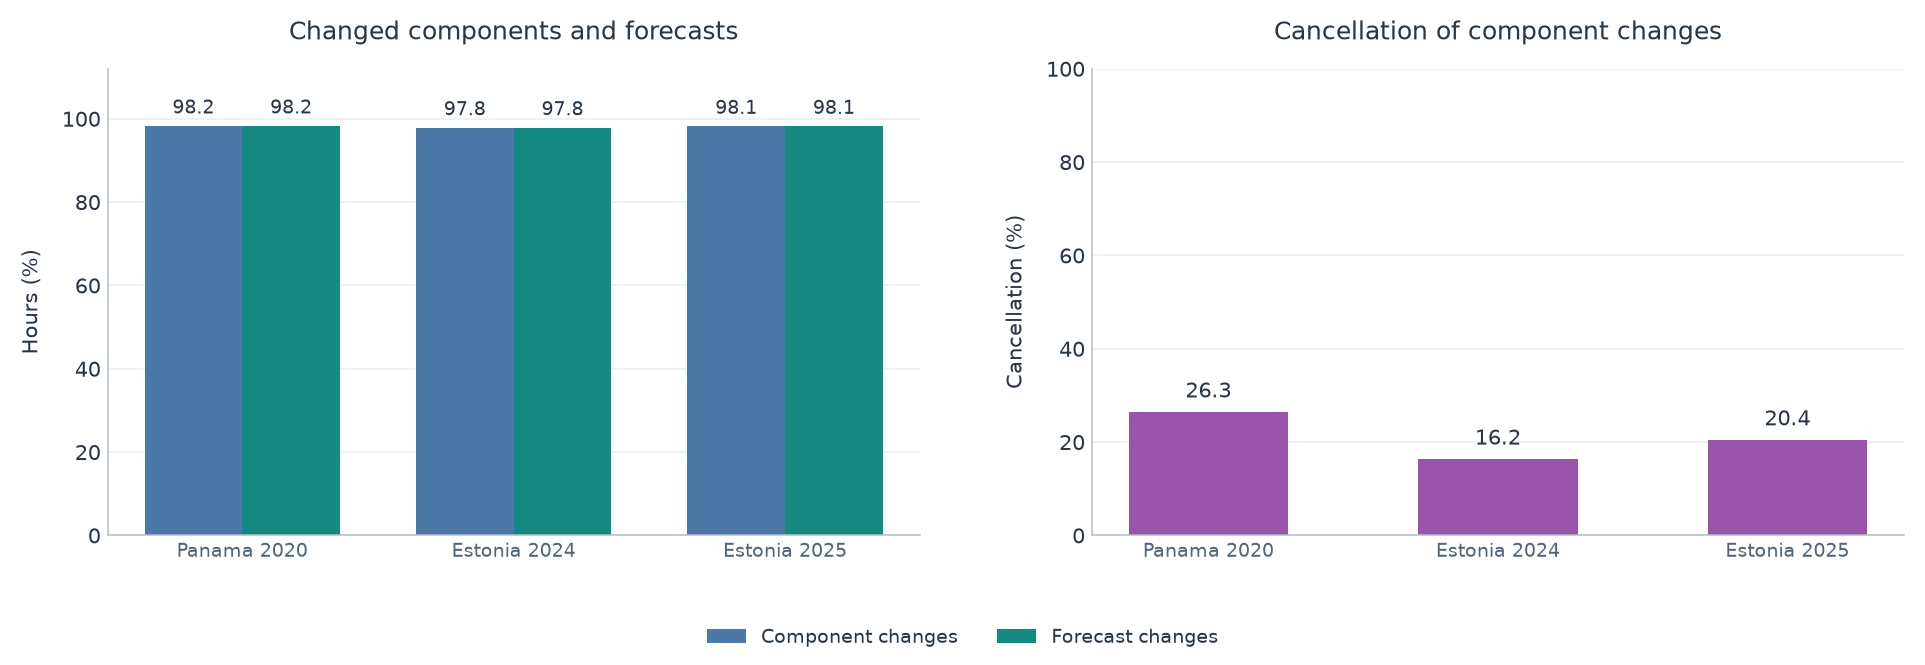

Panama 2020: XAI muutis 98.2% prognoose; muudetud tundidest aitas 58.2% ja halvendas 41.8%. MAE paranemine kaalumata jäägiprognoosist +0.8741.
Eesti 2024: XAI muutis 97.8% prognoose; muudetud tundidest aitas 52.7% ja halvendas 47.3%. MAE paranemine kaalumata jäägiprognoosist +0.5312.
Eesti 2025: XAI muutis 98.1% prognoose; muudetud tundidest aitas 50.5% ja halvendas 49.5%. MAE paranemine kaalumata jäägiprognoosist +0.1267.
Eesti 2025: teine kiht muutis 99.1% XAI-prognoose; üldine MAE muutus oli +0.1132. See on kirjeldus, mitte tõend muutuse põhjusest.


In [32]:
diagnostic_details, diagnostic_rows, group_rows = {}, [], []
for cohort, run in review_runs.items():
    frame_review = run["frame"]
    predicted_review = run["forecasts"]["credit_feedback"]
    details, summary = correction_diagnostics(
        frame_review, run["components"], run["weights"], predicted_review,
        tolerance=DIAGNOSTIC_OPTIONS["change_tolerance"],
    )
    diagnostic_details[cohort] = details
    scalar_review = run["forecasts"]["matched_scalar"]
    xai_delta = predicted_review - frame_review.prediction_residual.to_numpy()
    scalar_delta = scalar_review - frame_review.prediction_residual.to_numpy()
    summary["mean_abs_difference_vs_scalar"] = float(abs(predicted_review - scalar_review).mean())
    summary["mae_difference_vs_scalar"] = float(
        abs(predicted_review - frame_review.target_next_hour.to_numpy()).mean()
        - abs(scalar_review - frame_review.target_next_hour.to_numpy()).mean()
    )
    summary["delta_correlation_vs_scalar"] = (float(np.corrcoef(xai_delta, scalar_delta)[0, 1])
        if min(np.std(xai_delta), np.std(scalar_delta)) > DIAGNOSTIC_OPTIONS["change_tolerance"] else np.nan)
    diagnostic_rows.append({"cohort": cohort, **summary})
    deltas = run["components"] * (run["weights"] - 1)
    for column in deltas:
        group_rows.append({"Periood": cohort, "Komponent": GROUP_LABELS.get(column, column),
                           "Keskmine kaal": run["weights"][column].mean(),
                           "Muudetud tunde (%)": 100 * deltas[column].abs().gt(DIAGNOSTIC_OPTIONS["change_tolerance"]).mean(),
                           "Keskmine absoluutne muutus": deltas[column].abs().mean()})
diagnostic_summary = pd.DataFrame(diagnostic_rows)
display(diagnostic_summary[["cohort", "n", "parts_changed_pct", "changed_pct", "mean_abs_change",
                            "helped_pct_when_changed", "harmed_pct_when_changed", "mae_gain_overall",
                            "mean_cancellation_when_parts_change"]].rename(columns={
    "cohort": "Periood", "n": "Tunde", "parts_changed_pct": "Komponente muudetud (%)",
    "changed_pct": "Prognoosi muudetud (%)", "mean_abs_change": "Keskmine absoluutne muutus",
    "helped_pct_when_changed": "Aitas muudetutest (%)", "harmed_pct_when_changed": "Halvendas muudetutest (%)",
    "mae_gain_overall": "MAE paranemine jäägiprognoosist", "mean_cancellation_when_parts_change": "Keskmine tühistumise osakaal",
}))
display(diagnostic_summary[["cohort", "mean_abs_difference_vs_scalar", "mae_difference_vs_scalar",
                            "delta_correlation_vs_scalar"]].rename(columns={
    "cohort": "Periood", "mean_abs_difference_vs_scalar": "Keskmine erinevus ühe kaalu prognoosist",
    "mae_difference_vs_scalar": "MAE(XAI) − MAE(üks kaal)", "delta_correlation_vs_scalar": "Muudatuste korrelatsioon",
}))
display(pd.DataFrame(group_rows))
with plt.rc_context(PLOT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    positions = np.arange(len(diagnostic_summary))
    bars = axes[0].bar(positions - 0.18, diagnostic_summary.parts_changed_pct,
                       width=0.36, label='Component changes', color=PLOT_COLORS['residual'])
    axes[0].bar_label(bars, fmt='%.1f', padding=4, fontsize=10)
    bars = axes[0].bar(positions + 0.18, diagnostic_summary.changed_pct,
                       width=0.36, label='Forecast changes', color=PLOT_COLORS['credit_feedback'])
    axes[0].bar_label(bars, fmt='%.1f', padding=4, fontsize=10)
    labels = [plot_cohort(cohort) for cohort in diagnostic_summary.cohort]
    axes[0].set_xticks(positions, labels)
    axes[0].set(ylabel='Hours (%)', ylim=(0, 112), title='Changed components and forecasts')
    fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=2, fontsize=10)
    bars = axes[1].bar(positions, 100 * diagnostic_summary.mean_cancellation_when_parts_change,
                       color=PLOT_COLORS['lime'], width=0.55)
    axes[1].bar_label(bars, fmt='%.1f', padding=5, fontsize=11)
    axes[1].set_xticks(positions, labels)
    axes[1].set(ylabel='Cancellation (%)', ylim=(0, 100), title='Cancellation of component changes')
    for ax in axes:
        analysis_grid(ax, 'y')
    fig.tight_layout(pad=1.8, w_pad=4, rect=(0, 0.08, 1, 1))
    plt.show()

for row in diagnostic_summary.itertuples():
    print(f"{row.cohort}: XAI muutis {row.changed_pct:.1f}% prognoose; muudetud tundidest aitas "
          f"{row.helped_pct_when_changed:.1f}% ja halvendas {row.harmed_pct_when_changed:.1f}%. "
          f"MAE paranemine kaalumata jäägiprognoosist {row.mae_gain_overall:+.4f}.")
post_change = combined_predictions["xai_bias"] - combined_predictions["credit_feedback"]
post_gain = abs(actual_2025 - combined_predictions["credit_feedback"]) - abs(actual_2025 - combined_predictions["xai_bias"])
post_active = abs(post_change) > DIAGNOSTIC_OPTIONS["change_tolerance"]
print(f"Eesti {confirmation_year}: teine kiht muutis {100 * post_active.mean():.1f}% XAI-prognoose; "
      f"üldine MAE muutus oli {-post_gain.mean():+.4f}. See on kirjeldus, mitte tõend muutuse põhjusest.")


## 26. Näited, kus XAI aitas või halvendas
Pärast esimest seitset päeva valime **esimese muudetud tunni, kus XAI aitas**, ja **esimese, kus see halvendas** kaalumata parandusprognoosi. Need pole suurim võit ja kaotus. Koondtulemus on eelmises tabelis.

Ülemine graafik näitab sama pikkusega ajaakent valitud tunni ümber. Alumine näitab, kuidas osade kaalumine selle tunni prognoosi muutis. Positiivne tulp tõstab prognoosi, negatiivne langetab. Ka püsiosa võib muutuda. Need pole füüsikaliste põhjuste hinnangud. 2025 näited on koostatud pärast selle tulemuste vaatamist.


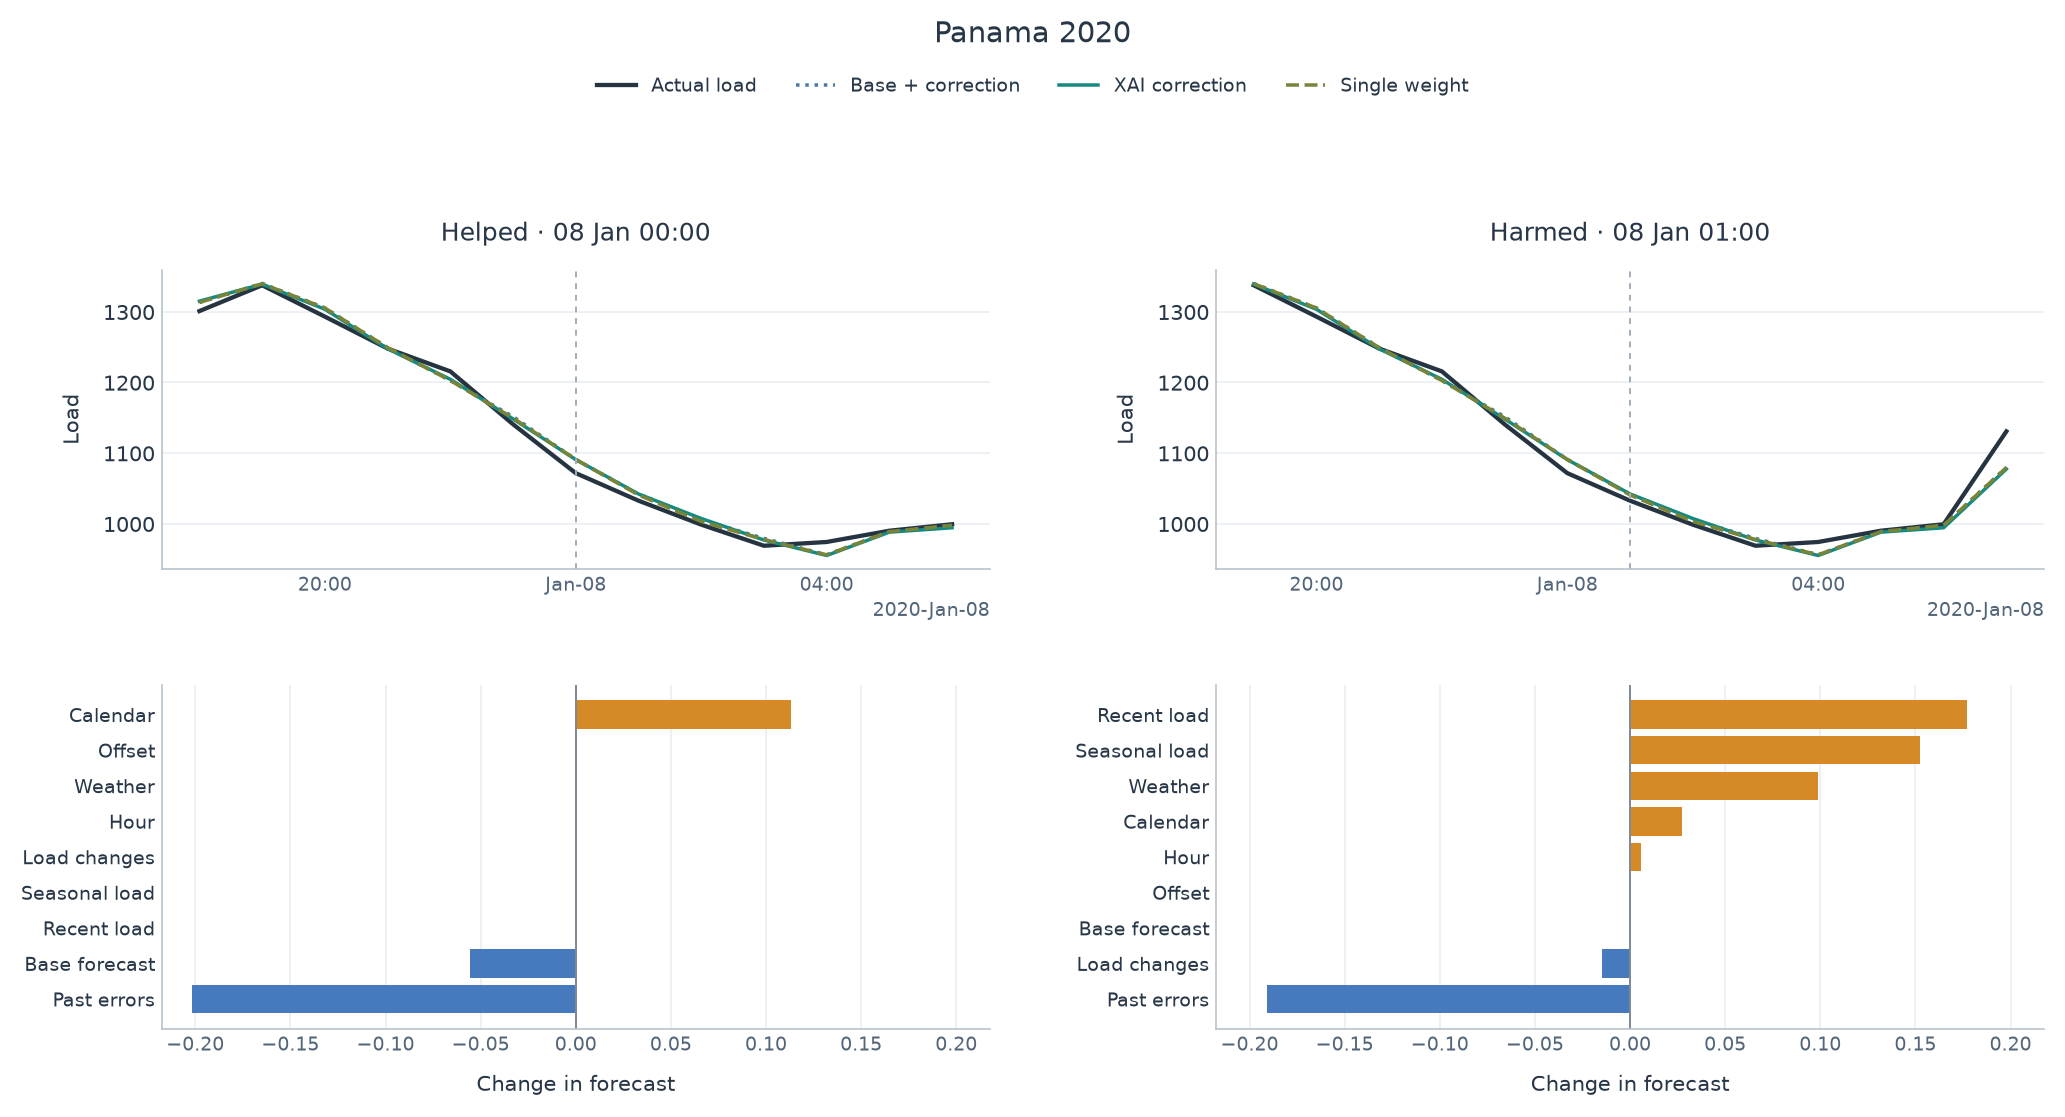

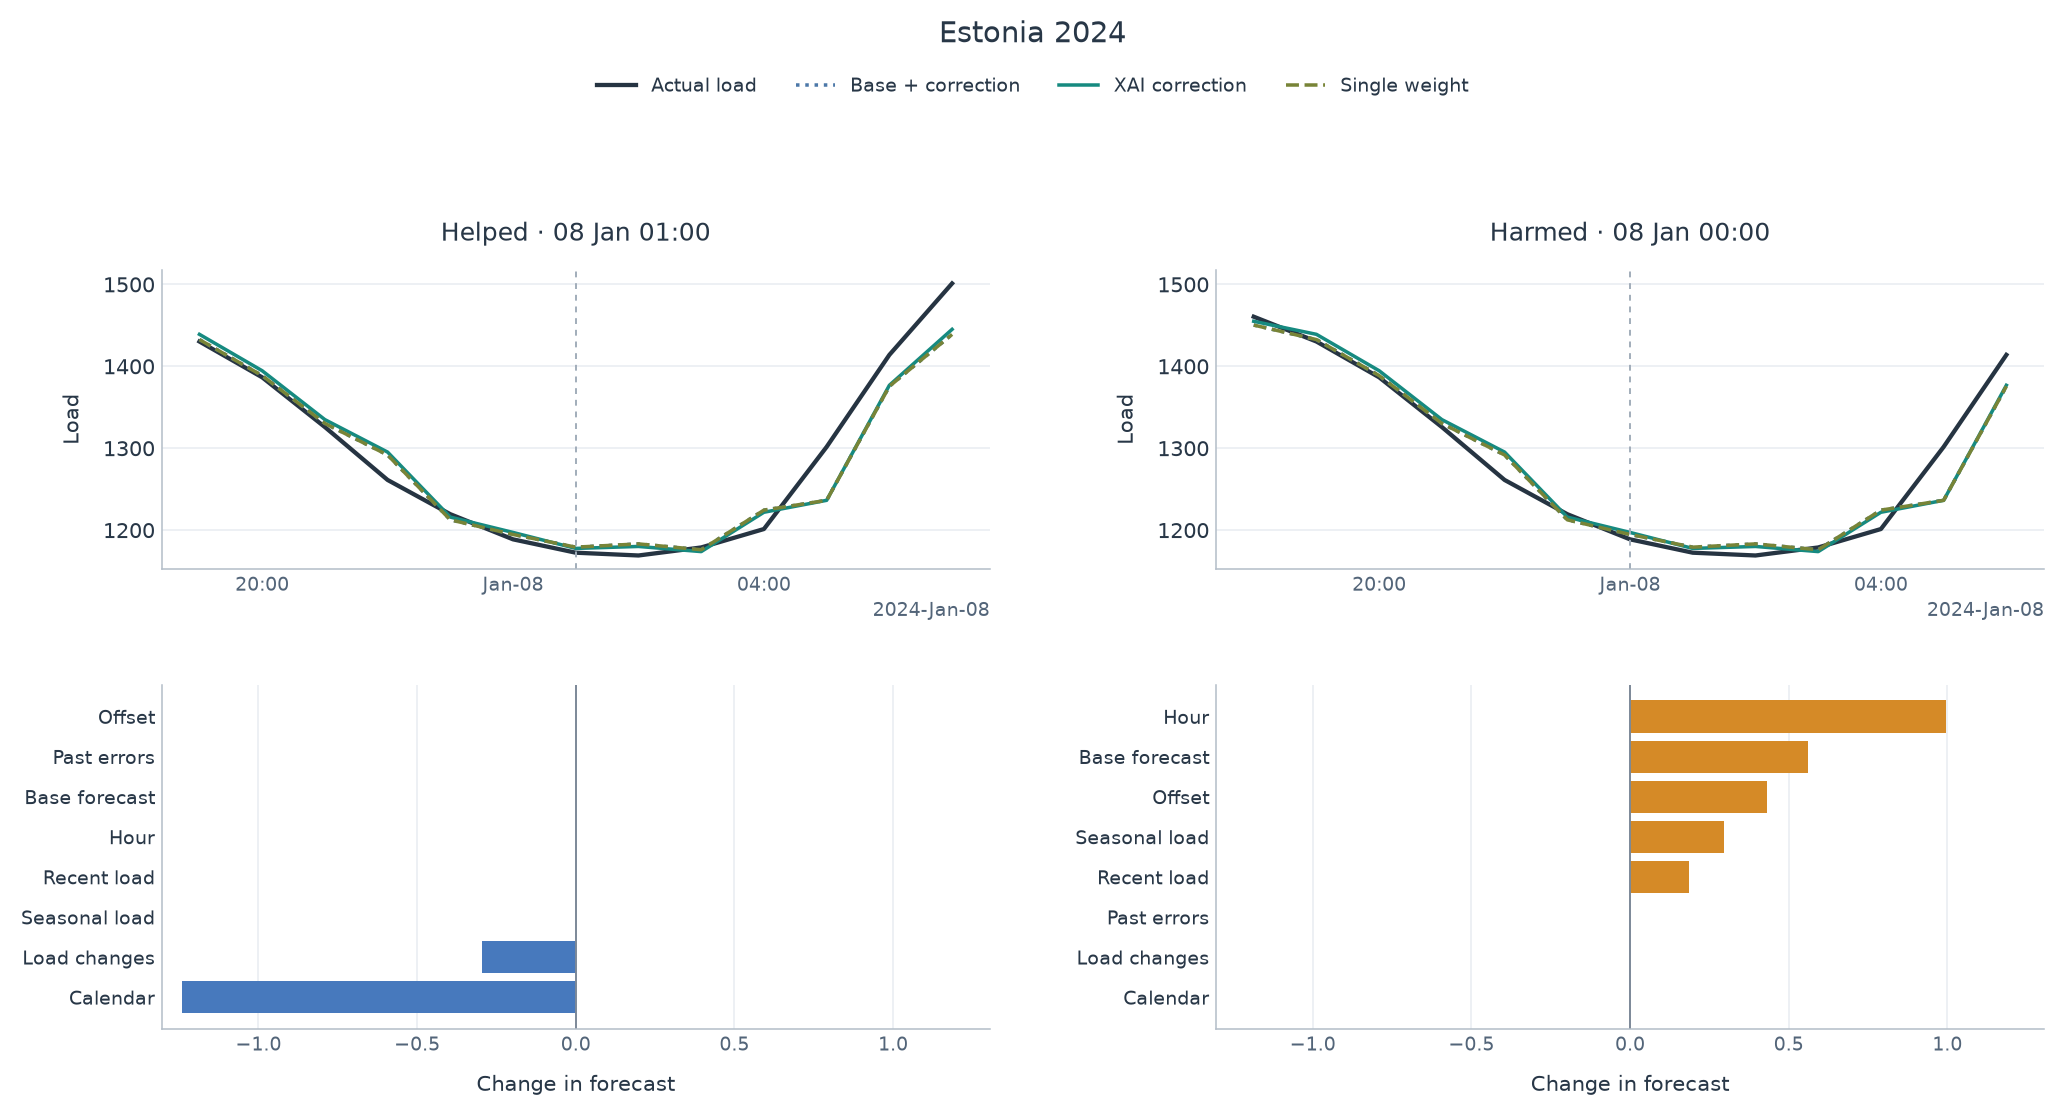

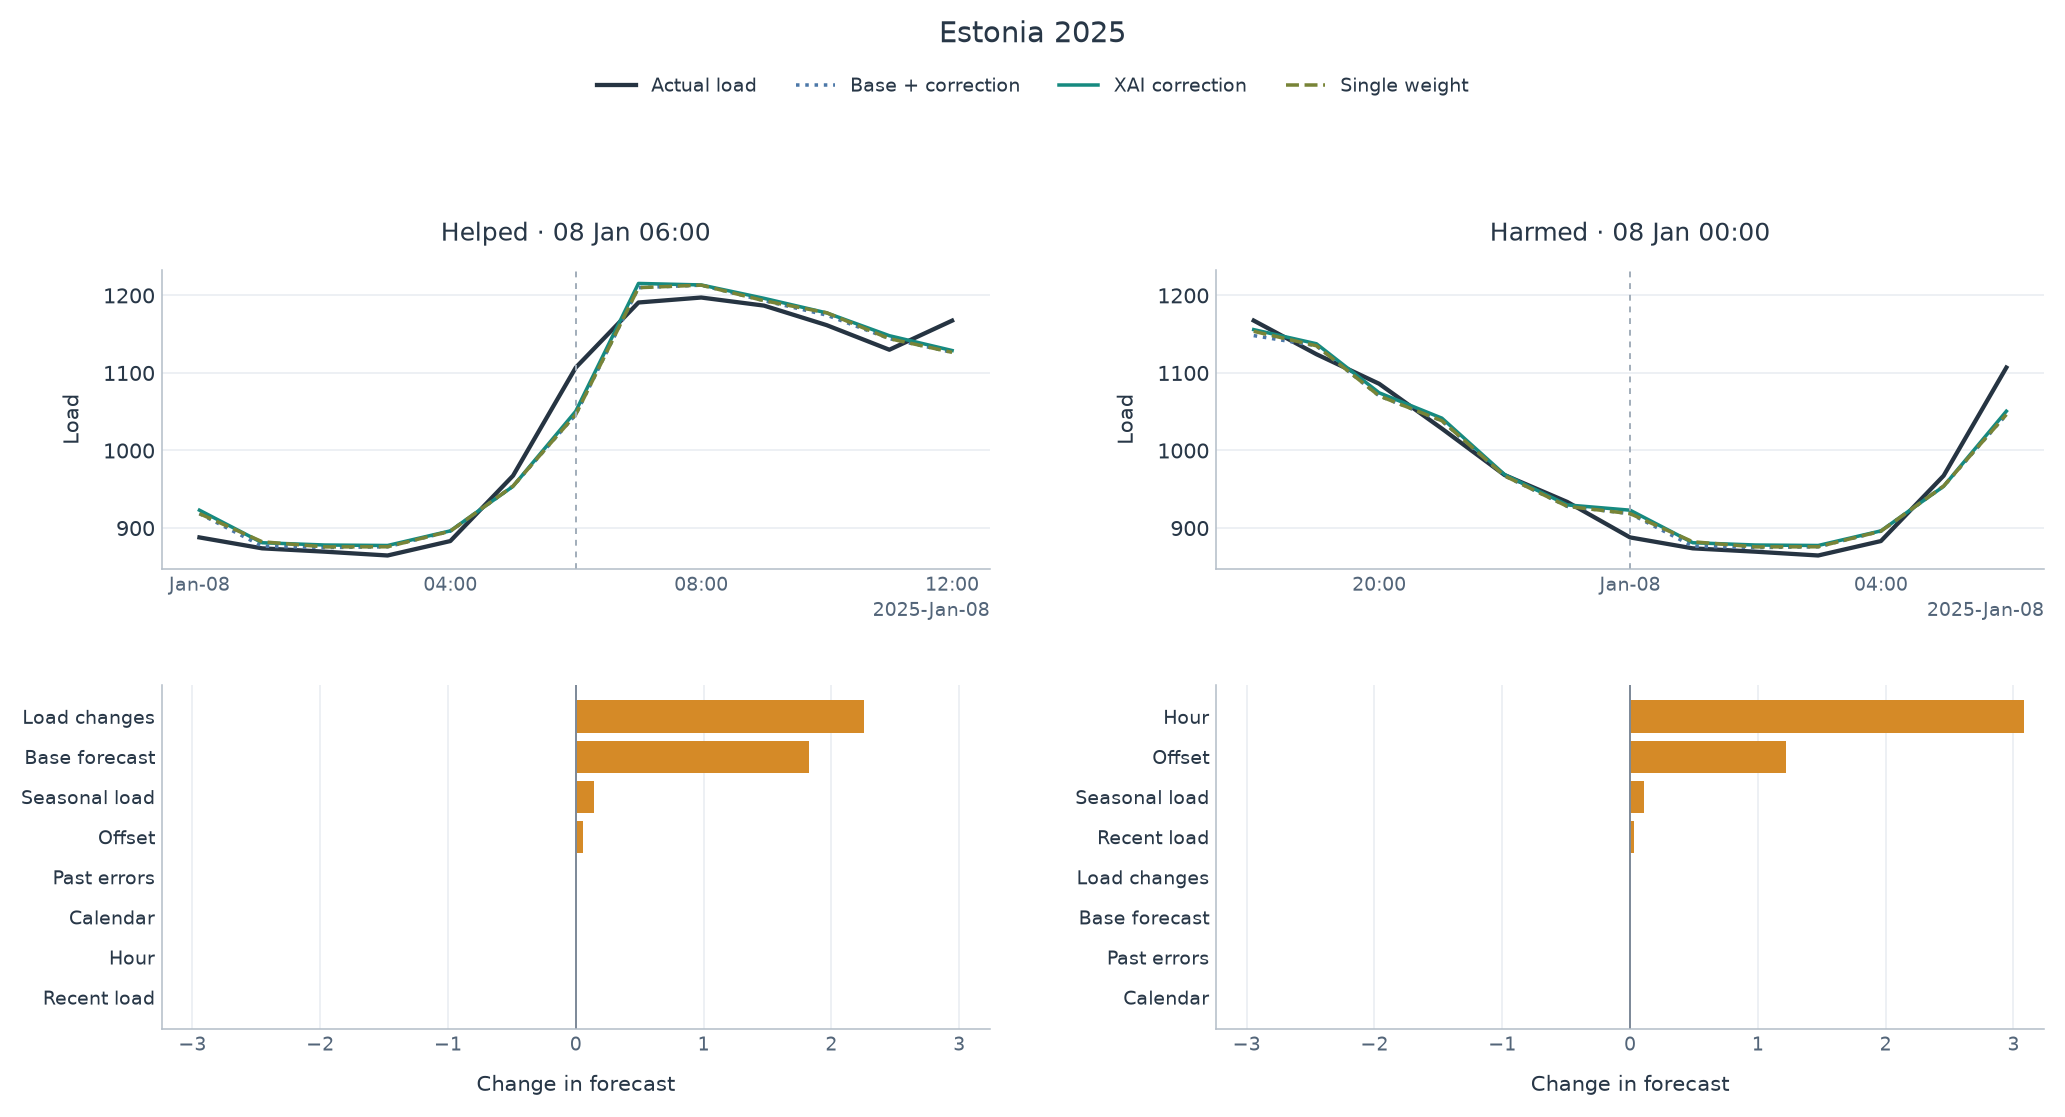

,Periood,Näide,Sihttund,Tegelik,Jääkprognoos,XAI-prognoos,Kasu jäägiprognoosist,Tühistumise osakaal
0,Panama 2020,Aitas,2020-01-08 00:00:00,1071.6841,1091.0077,1090.8637,0.1441,0.6112
1,Panama 2020,Halvendas,2020-01-08 01:00:00,1032.7158,1041.9592,1042.2152,-0.2560,0.6164
2,Eesti 2024,Aitas,2024-01-08 01:00:00,1172.2000,1178.9597,1177.4224,1.5373,0.0000
3,Eesti 2024,Halvendas,2024-01-08 00:00:00,1188.5000,1194.4591,1196.9306,-2.4715,0.0000
4,Eesti 2025,Aitas,2025-01-08 06:00:00,1106.7000,1046.1283,1050.4087,4.2804,0.0000
5,Eesti 2025,Halvendas,2025-01-08 00:00:00,887.7000,918.3634,922.8074,-4.4440,0.0000


In [33]:
diagnostic_case_rows = []
for cohort, run in review_runs.items():
    frame_review, details = run['frame'], diagnostic_details[cohort]
    eligible = frame_review.target_time.ge(frame_review.target_time.min() + pd.Timedelta(days=EXAMPLE_OFFSET_DAYS))
    selected = []
    for label, mask in (('Aitas', details.helped), ('Halvendas', details.harmed)):
        candidates = frame_review.index[eligible & details.prediction_changed & mask]
        if len(candidates):
            selected.append((label, candidates[0]))
    if not selected:
        print(cohort, '— sobivaid näiteid pole.')
        continue
    with plt.rc_context(PLOT_STYLE):
        fig, axes = plt.subplots(2, len(selected), figsize=(15, 8), squeeze=False,
                                 gridspec_kw={'height_ratios': [1.0, 1.15]})
        for col, (label, index) in enumerate(selected):
            target = frame_review.loc[index, 'target_time']
            window = frame_review.target_time.between(
                target - pd.Timedelta(hours=DIAGNOSTIC_OPTIONS['case_hours_before']),
                target + pd.Timedelta(hours=DIAGNOSTIC_OPTIONS['case_hours_after']))
            times = frame_review.loc[window, 'target_time']
            axes[0, col].plot(times, frame_review.loc[window, 'target_next_hour'],
                              color='#263442', label='Actual load', linewidth=2.2)
            for method, style in [('residual', ':'), ('credit_feedback', '-'), ('matched_scalar', '--')]:
                axes[0, col].plot(times, np.asarray(run['forecasts'][method])[window],
                                  label=PLOT_LABELS[method], color=PLOT_COLORS[method], linestyle=style)
            axes[0, col].axvline(target, color='#a1adba', linestyle=(0, (3, 3)), linewidth=1)
            outcome = 'Helped' if label == 'Aitas' else 'Harmed'
            axes[0, col].set(title=f'{outcome} · {target:%d %b %H:%M}', ylabel='Load')
            analysis_dates(axes[0, col], maxticks=5)
            analysis_grid(axes[0, col], 'y')
            changes = (run['components'].loc[index] * (run['weights'].loc[index] - 1)).sort_values()
            axes[1, col].barh([PLOT_GROUPS.get(k, k) for k in changes.index], changes,
                color=[PLOT_COLORS['feature_ablation'] if v < 0 else PLOT_COLORS['hourly_bias'] for v in changes])
            axes[1, col].axvline(0, color='#7c8998', linewidth=1)
            axes[1, col].set_xlabel('Change in forecast')
            axes[1, col].tick_params(axis='y', labelsize=10)
            analysis_grid(axes[1, col])
            diagnostic_case_rows.append({'Periood': cohort, 'Näide': label, 'Sihttund': target,
                'Tegelik': frame_review.loc[index, 'target_next_hour'],
                'Jääkprognoos': run['forecasts']['residual'][index],
                'XAI-prognoos': run['forecasts']['credit_feedback'][index],
                'Kasu jäägiprognoosist': details.loc[index, 'gain_vs_residual'],
                'Tühistumise osakaal': details.loc[index, 'cancellation_share']})
        load_min = min(ax.get_ylim()[0] for ax in axes[0])
        load_max = max(ax.get_ylim()[1] for ax in axes[0])
        change_limit = max(max(abs(value) for value in ax.get_xlim()) for ax in axes[1])
        for ax in axes[0]:
            ax.set_ylim(load_min, load_max)
        for ax in axes[1]:
            ax.set_xlim(-change_limit, change_limit)
        fig.suptitle(plot_cohort(cohort), fontsize=15, y=0.995)
        fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper center',
                    bbox_to_anchor=(0.5, 0.96), ncol=4, fontsize=10)
        fig.tight_layout(pad=1.8, w_pad=4, h_pad=3, rect=(0, 0, 1, 0.91))
        plt.show()
diagnostic_cases = pd.DataFrame(diagnostic_case_rows)
display(diagnostic_cases)


## 27. Uurimisküsimuste koondtulemus
Tabel seob katsed uurimisküsimustega ja eristab arendust, tagasivaatelisi võrdlusi, algse plaaniga 2025 kontrolli ning hilisemaid lisaanalüüse. 2025 kontroll käib ühendatud TreeSHAP-meetodi kohta, mitte kõigi kolme selgitaja kohta.

Järeldused kehtivad kirjeldatud andme- ja ajamärgistuse eeldustel. Katse ei mõõda selgituste arusaadavust inimesele ega majanduslikku kasu. Selge erinevuse puudumine ei tähenda meetodite võrdsust.


In [34]:
research_rows = []
for dataset in DATASETS:
    row = primary_intervals[primary_intervals.dataset.eq(dataset) & primary_intervals.scope.eq("overall")].iloc[0]
    result = ("XAI MAE selgelt väiksem" if row.adjusted_low > 0 else
              "Lihtsa MAE selgelt väiksem" if row.adjusted_high < 0 else "Selget üldise MAE erinevust ei tuvastatud")
    research_rows.append({"Küsimus/kontroll": "UK1: XAI lisakasu", "Katse": "XAI versus lihtne parandaja",
                          "Andmed": f"{COUNTRIES[dataset]} {cfg['datasets'][dataset]['test_year']}",
                          "Tulemus": result, "Piirang": "Tagasivaateline; ajaplokiga vahemik; ideaalne kättesaadavus"})
for dataset in DATASETS:
    rows = xai_primary_intervals[xai_primary_intervals.dataset.eq(dataset) & xai_primary_intervals.scope.eq("overall")
                                 & xai_primary_intervals.B.isin(EXPLAINERS)]
    clear = rows[(rows.adjusted_low > 0) | (rows.adjusted_high < 0)]
    times = xai_timing[xai_timing.dataset.eq(dataset) & xai_timing.method.isin(EXPLAINERS)].set_index("method").total_seconds
    result = ("Selget üldise MAE erinevust ei tuvastatud" if clear.empty else "Vähemalt ühes paaris selge MAE erinevus")
    research_rows.append({"Küsimus/kontroll": "UK2: XAI-meetodi valik", "Katse": "TreeSHAP, LIME, asendamine",
                          "Andmed": f"{COUNTRIES[dataset]} {cfg['datasets'][dataset]['test_year']}",
                          "Tulemus": result + "; kiireim XAI: " + XAI_LABELS[times.idxmin()],
                          "Piirang": "Ühine ühendamisreegel; fikseeritud seaded; tagasivaateline"})
claim = combined_primary_intervals[combined_primary_intervals.scope.eq("overall")
                                   & combined_primary_intervals.A.eq("xai_bias")
                                   & combined_primary_intervals.B.isin(["hourly_bias", "scalar_bias"])]
research_rows.append({"Küsimus/kontroll": "UK1: ühendamise lisahüpotees", "Katse": "XAI + veaparandus ja samaväärne kontroll",
                      "Andmed": f"Eesti {confirmation_year}",
                      "Tulemus": "Mõlema kontrolli ees selge eelis" if claim.adjusted_high.lt(0).all() else "Üldine lisakasu mõlema kontrolli ees ei leidnud kinnitust",
                      "Piirang": "Plaan enne esimese jooksu tulemusi; koormuse kohene saabumine eeldus"})
rapid = xai_primary_intervals[xai_primary_intervals.scope.ne("overall")]
clear_rapid = rapid[(rapid.adjusted_low > 0) | (rapid.adjusted_high < 0)]
rapid_findings = [f"{COUNTRIES[r.dataset]}, {scope_labels[r.scope]}: "
                  f"{XAI_LABELS[r.A if r.adjusted_high < 0 else r.B]}"
                  for r in clear_rapid.itertuples()]
research_rows.append({"Küsimus/kontroll": "UK1/UK2: kiired muutused", "Katse": "Eraldi tõusu- ja langustunnid",
                      "Andmed": "Panama 2020; Eesti 2024", "Tulemus": "; ".join(dict.fromkeys(rapid_findings)) or "Selget erinevust ei tuvastatud",
                      "Piirang": "Tagasivaateline alarühma tulemus; ei anna ette teada, millal meetodit vahetada"})
for cohort, values in naive_overall.groupby("cohort", sort=False):
    best = values.loc[values.MAE.idxmin()]
    research_rows.append({"Küsimus/kontroll": "Alusvõrdlus", "Katse": "Viimane koormus versus valitud mudelid/parandajad",
                          "Andmed": cohort,
                          "Tulemus": f"Väikseim näidatud MAE: {review_labels[best.method]}; paranemine naiivsest {best.improvement_vs_naive_pct:.2f}%",
                          "Piirang": "Kirjeldav järelvõrdlus samal maskil; pole uus sõltumatu kinnituskontroll"})
research_summary = pd.DataFrame(research_rows)
with pd.option_context("display.max_colwidth", None):
    display(research_summary)
print("Panuste ja kaalude analüüs aitab tulemust selgitada, kuid ei tõesta põhjuslikke seoseid.")


,Küsimus/kontroll,Katse,Andmed,Tulemus,Piirang
0,UK1: XAI lisakasu,XAI versus lihtne parandaja,Panama 2020,Selget üldise MAE erinevust ei tuvastatud,Tagasivaateline; ajaplokiga vahemik; ideaalne kättesaadavus
1,UK1: XAI lisakasu,XAI versus lihtne parandaja,Eesti 2024,Selget üldise MAE erinevust ei tuvastatud,Tagasivaateline; ajaplokiga vahemik; ideaalne kättesaadavus
2,UK2: XAI-meetodi valik,"TreeSHAP, LIME, asendamine",Panama 2020,Selget üldise MAE erinevust ei tuvastatud; kiireim XAI: TreeSHAP,Ühine ühendamisreegel; fikseeritud seaded; tagasivaateline
3,UK2: XAI-meetodi valik,"TreeSHAP, LIME, asendamine",Eesti 2024,Selget üldise MAE erinevust ei tuvastatud; kiireim XAI: TreeSHAP,Ühine ühendamisreegel; fikseeritud seaded; tagasivaateline
4,UK1: ühendamise lisahüpotees,XAI + veaparandus ja samaväärne kontroll,Eesti 2025,Üldine lisakasu mõlema kontrolli ees ei leidnud kinnitust,Plaan enne esimese jooksu tulemusi; koormuse kohene saabumine eeldus
5,UK1/UK2: kiired muutused,Eraldi tõusu- ja langustunnid,Panama 2020; Eesti 2024,"Eesti, Kiire langus: Asendamine","Tagasivaateline alarühma tulemus; ei anna ette teada, millal meetodit vahetada"
6,Alusvõrdlus,Viimane koormus versus valitud mudelid/parandajad,Panama 2020,Väikseim näidatud MAE: Lihtne; paranemine naiivsest 58.58%,Kirjeldav järelvõrdlus samal maskil; pole uus sõltumatu kinnituskontroll
7,Alusvõrdlus,Viimane koormus versus valitud mudelid/parandajad,Eesti 2024,Väikseim näidatud MAE: XAI; paranemine naiivsest 57.45%,Kirjeldav järelvõrdlus samal maskil; pole uus sõltumatu kinnituskontroll
8,Alusvõrdlus,Viimane koormus versus valitud mudelid/parandajad,Eesti 2025,Väikseim näidatud MAE: Üks kaal; paranemine naiivsest 41.28%,Kirjeldav järelvõrdlus samal maskil; pole uus sõltumatu kinnituskontroll


Panuste ja kaalude analüüs aitab tulemust selgitada, kuid ei tõesta põhjuslikke seoseid.


## 28. Järeldus
Allolev kokkuvõte kasutab selle käivituse tulemusi. Üldine täpsus, kiired muutused ja kahjulikkus võivad anda eri vastuse. Üks võrdlus ei tõesta meetodi üldist paremust.

Panama 2020 ja Eesti 2024 võrdlus on tagasivaateline. Ühendatud parandaja 2025 katse plaan fikseeriti enne selle tulemuste vaatamist. Nüüd on ka 2025 tulemused nähtud: nende põhjal loodud uus idee vajab eraldi kontrolli. Naiivne prognoos ja paranduste diagnoos on hilisemad kirjeldavad lisad, mis algset katseplaani ei muuda.

**Tõlgendamisel peame silmas järgmist.**
- Koormuse kohene saabumine on eeldus. Panama ilma 24 tunni nihe ei vasta MERRA-2 tegelikule avaldamisviivitusele. Ühikud ja osa intervallide kirjeldusest vajavad kinnitamist. Seetõttu on see ajalooline simulatsioon; riikide absoluutseid vigu omavahel ei järjesta.
- Selgitajaid võrdleme sama ühendamisreegli ja TreeSHAP-i arenduses valitud seadetega. LIME-i proovide ja asendamise tausta suurus on fikseeritud. Arvutusajad sõltuvad arvutist ja selle koormusest.
- Selgitamata osa jääb muutmata. Kui see on suur, ei saa kogu parandust pidada selgitatud osade kaalumise tulemuseks. Täpne summa pärast selle lisamist ei tõesta selgituse täpsust.
- SHAP-osad ei tõesta põhjuslikke seoseid. Inimesele arusaadavust ega majanduslikku kasu siin ei hinnata. Nulli sisaldav võrdlusvahemik ei tõesta meetodite võrdsust.

Tulemused ja vaheandmed jäävad notebooki mällu, sh `selection`, `runs`, `metrics`, `monthly` ja `intervals`.


In [35]:
for dataset in DATASETS:
    values = overall[overall.dataset.eq(dataset)].set_index("method")
    simple_mae = values.loc["hourly_bias", "MAE"]
    xai_mae = values.loc["credit_feedback", "MAE"]
    interval = primary_intervals[
        primary_intervals.dataset.eq(dataset) & primary_intervals.scope.eq("overall")
    ].iloc[0]
    if interval.adjusted_low > 0:
        conclusion = "XAI üldine MAE on selgelt väiksem."
    elif interval.adjusted_high < 0:
        conclusion = "Lihtsa meetodi üldine MAE on selgelt väiksem."
    else:
        conclusion = "Üldises MAE-s selget vahet ei olnud."
    print(f"{COUNTRIES[dataset]}: lihtne MAE {simple_mae:.4f}; XAI MAE {xai_mae:.4f}.")
    print(conclusion)
    print(f"Korrigeeritud vahemik lihtne − XAI: "
          f"[{interval.adjusted_low:.4f}, {interval.adjusted_high:.4f}]\n")

for dataset in DATASETS:
    measured = xai_overall[xai_overall.dataset.eq(dataset)].set_index("method")
    print(COUNTRIES[dataset] + " — kolme XAI-meetodi võrdlus:")
    print("Väikseim mõõdetud MAE:", XAI_LABELS[measured.MAE.idxmin()] +
          "; väikseim üldine RMSE:", XAI_LABELS[measured.RMSE.idxmin()] + ".")
    overall_pairs = xai_primary_intervals[
        xai_primary_intervals.dataset.eq(dataset) & xai_primary_intervals.scope.eq("overall")
    ]
    for row in overall_pairs.itertuples():
        if row.adjusted_high < 0:
            verdict = "selgelt väiksem MAE: " + XAI_LABELS[row.A]
        elif row.adjusted_low > 0:
            verdict = "selgelt väiksem MAE: " + XAI_LABELS[row.B]
        else:
            verdict = "selget MAE vahet ei olnud"
        print(f"{XAI_LABELS[row.A]} / {XAI_LABELS[row.B]}: {verdict}.")
    changes = xai_primary_intervals[
        xai_primary_intervals.dataset.eq(dataset) & xai_primary_intervals.scope.ne("overall")
    ]
    clear = changes[(changes.adjusted_high < 0) | (changes.adjusted_low > 0)]
    for row in clear.itertuples():
        winner = row.A if row.adjusted_high < 0 else row.B
        print(f"{scope_labels[row.scope]} ({row.n} tundi), {XAI_LABELS[row.A]} / {XAI_LABELS[row.B]}: "
              f"väiksem MAE: {XAI_LABELS[winner]}; vahe {row.difference:+.4f} "
              f"[{row.adjusted_low:.4f}, {row.adjusted_high:.4f}].")
    print("Lisaarvutusaeg (s):")
    print(xai_timing[xai_timing.dataset.eq(dataset)][["method", "total_seconds"]]
          .assign(method=lambda x: x.method.map(XAI_LABELS)).to_string(index=False))
    print("Selgitamata osa keskmine absoluutne suurus:")
    print(xai_checks[xai_checks.dataset.eq(dataset)][["method", "native_gap_mae"]]
          .assign(method=lambda x: x.method.map(XAI_LABELS)).to_string(index=False))
    print()

print(f"Eesti {confirmation_year} — ühendatud parandaja kinnituskontroll:")
print("Väikseim mõõdetud MAE:",
      COMBINED_LABELS[combined_overall.set_index("method").MAE.idxmin()])
primary_claim = combined_primary_intervals[
    combined_primary_intervals.scope.eq("overall") & combined_primary_intervals.A.eq("xai_bias")
    & combined_primary_intervals.B.isin(["hourly_bias", "scalar_bias"])
]
assert len(primary_claim) == 2
if primary_claim.adjusted_high.lt(0).all():
    print("Kriteerium täitus: ühendatud XAI andis mõlemast kontrollist selgelt väiksema üldise MAE.")
else:
    print("Kriteerium ei täitunud: ühendatud XAI üldine lisakasu mõlema kontrolli ees ei leidnud kinnitust.")
for row in combined_primary_intervals[combined_primary_intervals.scope.eq("overall")].itertuples():
    print(f"{COMBINED_LABELS[row.A]} / {COMBINED_LABELS[row.B]}: MAE vahe {row.difference:+.4f}; "
          f"korrigeeritud vahemik [{row.adjusted_low:.4f}, {row.adjusted_high:.4f}].")
print("Lisakihi kasu üksi ei näita XAI eelist ilma XAI-ta kontrolli ees.")

print("Naiivse prognoosi lisavõrdlus:")
for cohort, values in naive_overall.groupby("cohort", sort=False):
    print(cohort + ":")
    for row in values[values.method.isin(["naive", "residual", "hourly_bias", "credit_feedback"])].itertuples():
        print(f"  {review_labels[row.method]}: MAE {row.MAE:.4f}; paranemine naiivsest {row.improvement_vs_naive_pct:.2f}%.")
print("Piirangud: Panama 24 h ilmaviivitus ei vasta MERRA-2 avaldamisajale. Koormuse kohene saabumine ja osa metaandmeid on eeldused.")


Panama: lihtne MAE 15.7702; XAI MAE 15.7765.
Üldises MAE-s selget vahet ei olnud.
Korrigeeritud vahemik lihtne − XAI: [-0.1494, 0.1298]

Eesti: lihtne MAE 16.0655; XAI MAE 16.0589.
Üldises MAE-s selget vahet ei olnud.
Korrigeeritud vahemik lihtne − XAI: [-0.1319, 0.1576]

Panama — kolme XAI-meetodi võrdlus:
Väikseim mõõdetud MAE: Lihtne; väikseim üldine RMSE: Lihtne.
LIME / TreeSHAP: selget MAE vahet ei olnud.
Asendamine / TreeSHAP: selget MAE vahet ei olnud.
Asendamine / LIME: selget MAE vahet ei olnud.
TreeSHAP / Lihtne: selget MAE vahet ei olnud.
LIME / Lihtne: selget MAE vahet ei olnud.
Asendamine / Lihtne: selget MAE vahet ei olnud.
Lisaarvutusaeg (s):
    method  total_seconds
    Lihtne         0.0171
  TreeSHAP         1.3363
      LIME        32.9712
Asendamine         3.7511
Selgitamata osa keskmine absoluutne suurus:
    method  native_gap_mae
  TreeSHAP          0.0000
      LIME          7.2113
Asendamine          6.0111

Eesti — kolme XAI-meetodi võrdlus:
Väikseim mõõdetu

## 29. Seven-minute supervisor overview
Eight English slides with separate speaker notes. The planned speaking time is **7 minutes**; allow short pauses for the figures. The presentation code reuses the analysis results and does not train models. Six visuals below show the existing results. Copy or save the notebook images through the user interface; this cell does not export files.

**Reading the figures:** MAEs remain in source-data units. Do not rank the two countries by absolute MAE. Bars start at zero. The accuracy–time figure pairs the existing multiplicity-adjusted, time-block uncertainty intervals with total added computation time on a linear axis. Timing covers the evaluation batch, not live latency. The 2025 plot uses the original planned comparisons and intervals. These intervals do not undo historical development choices. The rapid-decrease plot is a retrospective subgroup finding. All data-availability limitations described above remain in force. The shared correction settings were selected during TreeSHAP development.

**Slide 1 — Can XAI improve electricity load forecasts? (40 seconds)**

**On the slide**

1. Does XAI improve forecasts more than simpler correction methods?
2. How does the XAI method affect accuracy and computation time?

**Visual**

No chart. Use a clean title and the two research questions.

**Speaker notes**

My work is about using XAI to improve electricity load forecasts. The idea is to use information from XAI to adjust a forecast and then check whether it becomes more accurate.

First, I compare this approach with simpler ways of correcting forecast errors. Then, I compare three XAI methods to see whether they give different results and how much time they take.

So, I’m looking at whether XAI actually adds something useful, and whether the choice of method matters.

---

**Slide 2 — Choosing a base model (50 seconds)**

**On the slide**

Four models · same inputs · same forecast hours

**Visual**

Figure 1 compares four models on Panama data from 2018 and 2019. Each model was trained using only earlier data. HistGBR is highlighted because it had the lowest prediction error in both years.

**Speaker notes**

I first compared four base models using earlier Panama data. I wanted a reasonable starting point for the correction experiments. All four models used the same inputs and forecast hours.

For 2018, I trained on data up to 2017. Then I added 2018 to the training data and checked 2019. HistGBR had the lowest average error in both years, which supports using it for the correction experiments.

These are development results, not final test results. I used one fixed setup for each model, so I’m not claiming that HistGBR is always the best choice.

---

**Slide 3 — Same forecast. Different correction rules. (60 seconds)**

**On the slide**

Compare the correction rule, not a different starting model.

**Visual**

Figure 2: Correction workflow. The branches show alternative methods, not consecutive layers.

**Speaker notes**

All three methods start with the same forecast. First, the base model predicts the next hour’s electricity load. Then, a second model predicts how much that forecast should be corrected.

I compare three ways of adjusting this correction.

The simple method looks at earlier errors from the same hour of the day. If the forecasts have usually been too low at that hour, it raises the prediction a little.

The XAI method splits the model’s correction into smaller parts. It looks at how these parts performed in the past and gives less weight to parts that made forecasts worse.

The third method adjusts the whole correction with one weight. It does not use explanations, so it helps me check whether XAI itself adds value.

For training, I use errors from forecasts made using only earlier data. During evaluation, the methods also use only results that are already known.

---

**Slide 4 — Simple correction is a strong baseline (55 seconds)**

**On the slide**

Corrections help. No clear overall XAI advantage.

**Visual**

Figure 3: Overall forecast error. Two panels keep the datasets separate; zero-based bars show the actual scale of improvement.

**Speaker notes**

These charts show Panama 2020 and Estonia 2024 separately. MAE is the average size of the forecast errors.

The first bar simply repeats the last hour’s load as the next forecast. No model training is needed.

The base forecast uses HistGBR to predict next-hour load from load history and calendar information, plus delayed weather data in Panama.

For “Base + correction”, a second HistGBR model learns to predict the base forecast’s error, rather than the load itself. It uses the base forecast, load patterns and earlier errors. I add its predicted error to the base forecast. This is the residual model.

Simple correction adds a small adjustment based on the average past error of that corrected forecast at the same hour of the day.

XAI correction uses TreeSHAP to split the residual model’s prediction into parts. Parts that made past forecasts worse receive less weight.

The corrections reduce the error, but the simple and XAI results are almost the same. The uncertainty check also showed no clear overall advantage for XAI.

---

**Slide 5 — What does the explanation method add? (55 seconds)**

**On the slide**

No clear accuracy gain · different computation time

**Visual**

Figure 4: Estonia 2024, 8,654 forecasts. Aligned rows pair each method’s MAE difference from simple correction, including adjusted uncertainty intervals, with its total added computation time. The time axis is linear.

**Speaker notes**

Here, I use the same trained error model and weighting rule, but change the explanation method.

TreeSHAP calculates input contributions from the decision trees. LIME tests changed inputs and fits a small linear model around the forecast. Group ablation replaces groups of inputs with values from training data and checks how much the prediction changes.

On the left, I compare each method’s MAE with simple correction. Zero means no difference; negative values mean less error. The lines show uncertainty. All three cross zero, so there is no clear overall improvement over simple correction.

On the right, I show the extra computation time for all 8,654 forecasts. TreeSHAP took about 2.6 seconds, group ablation 6.8 and LIME 64. Simple correction took about 0.02 seconds. This excludes model training and is not live response time.

So, the methods had quite different costs without a clear accuracy gain. TreeSHAP was the fastest XAI option here. The shared correction settings were developed with TreeSHAP, so this is not a general ranking.

---

**Slide 6 — Does a second correction layer help? (55 seconds)**

**On the slide**

XAI + simple correction · Estonia 2025

**Visual**

Figure 5: Combined correction versus three comparators. A difference-and-interval plot is more informative than enlarged bars of almost equal MAEs.

**Speaker notes**

I added simple correction after XAI and tested it on Estonia 2025. The rules were fixed beforehand, and the single-weight method received the same extra step.

Each dot shows the combined XAI method’s error minus the comparison method’s error. The line shows uncertainty; right of zero means more error.

The first line crosses zero, so there is no clear improvement over simple correction. The other two stay to the right: the combined method performed worse than both alternatives.

---

**Slide 7 — A possible next step: rapid load decreases (45 seconds)**

**On the slide**

A useful clue for the next experiment.

**Visual**

Figure 6: Actual load and the original one-hour-ahead forecasts from simple correction and group ablation, Estonia 2024. The lower panel shows absolute error at each hour so that the small differences between the forecast curves remain visible. The window is unchanged: the first rapid-decrease hour after seven evaluation days, with five hours before its forecast origin and three hours after its target. It was selected without inspecting forecast errors. Each forecast belongs to its own one-hour-ahead origin; the curves are not a multi-hour forecast made at one time. The roughly 8% subgroup improvement discussed in the notes refers to all 383 rapid-decrease hours, not this individual example.

**Speaker notes**

The black line is the actual load. The other lines are forecasts made one hour ahead. Both methods overpredict during this decrease, and their predictions are close. The lower panel shows the size of their errors hour by hour.

Across all 383 rapid-decrease hours, group ablation had about 8% lower average error than simple correction. It does not win every hour.

The next question is whether information available before the forecast can help us decide when to use it.

---

**Slide 8 — Next steps (25 seconds)**

**On the slide**

- Identify when XAI corrections increase errors.
- Try adjusting parts with opposite effects together.

**Visual**

No additional chart. Use the two short bullet points.

Proposed research question: **Can grouping correction components by their historical opposing behavior improve adaptive forecast correction compared with weighting each component separately?**

First check on chronological development folds whether the harmful corrections are associated with changes to opposing components. Cancellation alone is not evidence of an error or a cause of harm. If this diagnostic supports the hypothesis, define small groups from development-only component histories and give each group a shared adaptive credit weight. Keep the base and residual models unchanged; account for the offset separately rather than treating it as a physical input. This changes how already-computed correction components are weighted; it does not change the SHAP estimation algorithm or establish causal effects.

Controls: the current separate-component weights, the existing single-weight method, simple correction, and random component groups matched in number and size. Random grouping tests whether any gain comes merely from using fewer independent weights. Define the grouping and all settings on development data, then fix them before an unused evaluation period. The already-examined 2024 and 2025 results cannot provide a fresh independent confirmation. Report overall error, harmful corrections, rapid-change subgroup results and added computation. Resolving the existing data-availability assumptions remains a prerequisite for operational claims.

**Research basis — not spoken**

Feature grouping and SHAP-derived group weights already have related literature. Chi et al. (2026) study SHAP-importance-weighted fusion of group-specific expert models; Covert et al. (2021) provide a framework for removal-based explanations. The proposal here is to investigate historical cancellation when grouping components of an existing residual correction, with adaptive feedback and matched controls. This is a candidate research contribution, not an established claim of novelty or improved accuracy. A focused related-work review is still required before claiming that this specific approach is new.

- [Covert, Lundberg & Lee (2021), Explaining by Removing: A Unified Framework for Model Explanation](https://jmlr.org/papers/v22/20-1316.html).
- [Chi et al. (2026), TreeSHAP-Importance-Weighted Feature-Group Fusion for Tabular Regression](https://doi.org/10.3390/math14132419).

**Speaker notes**

First, I would look at cases where XAI made the forecast worse. Some explanation parts push the forecast up and others push it down. I would test adjusting these parts together to see whether this reduces the error.

---


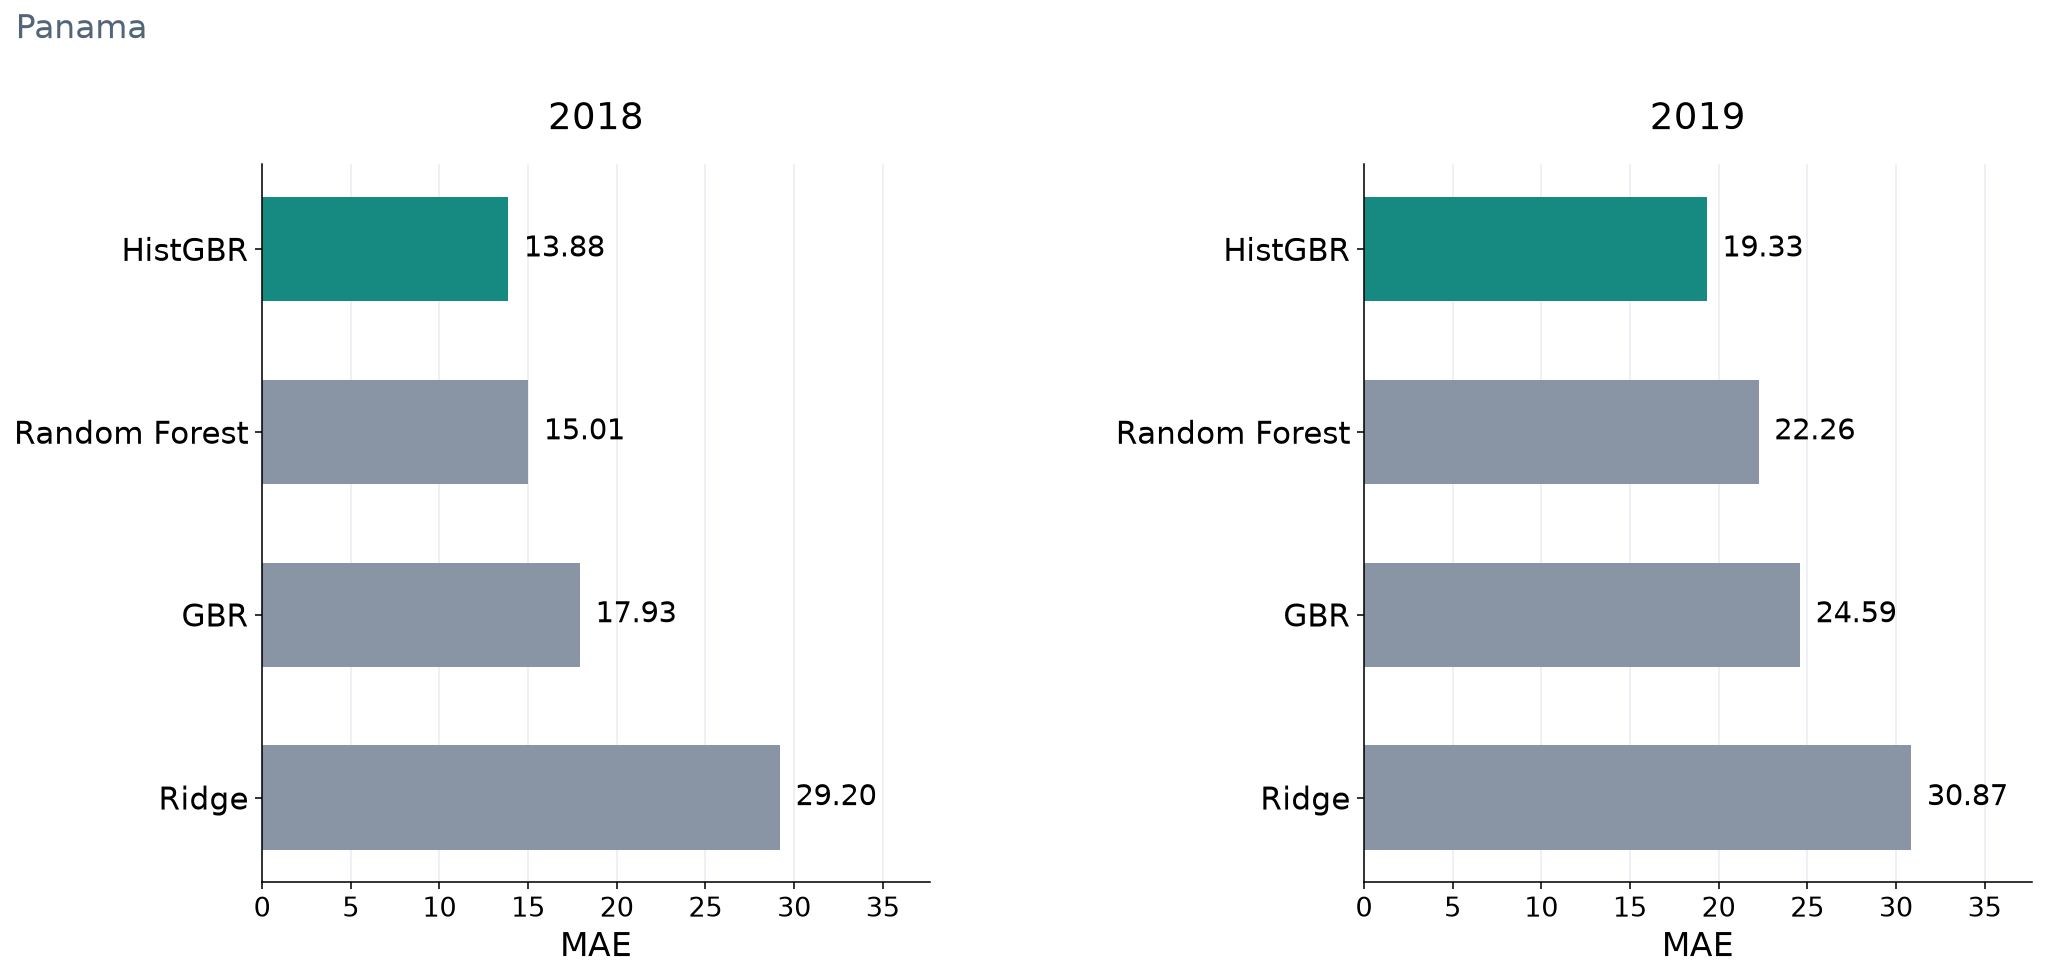

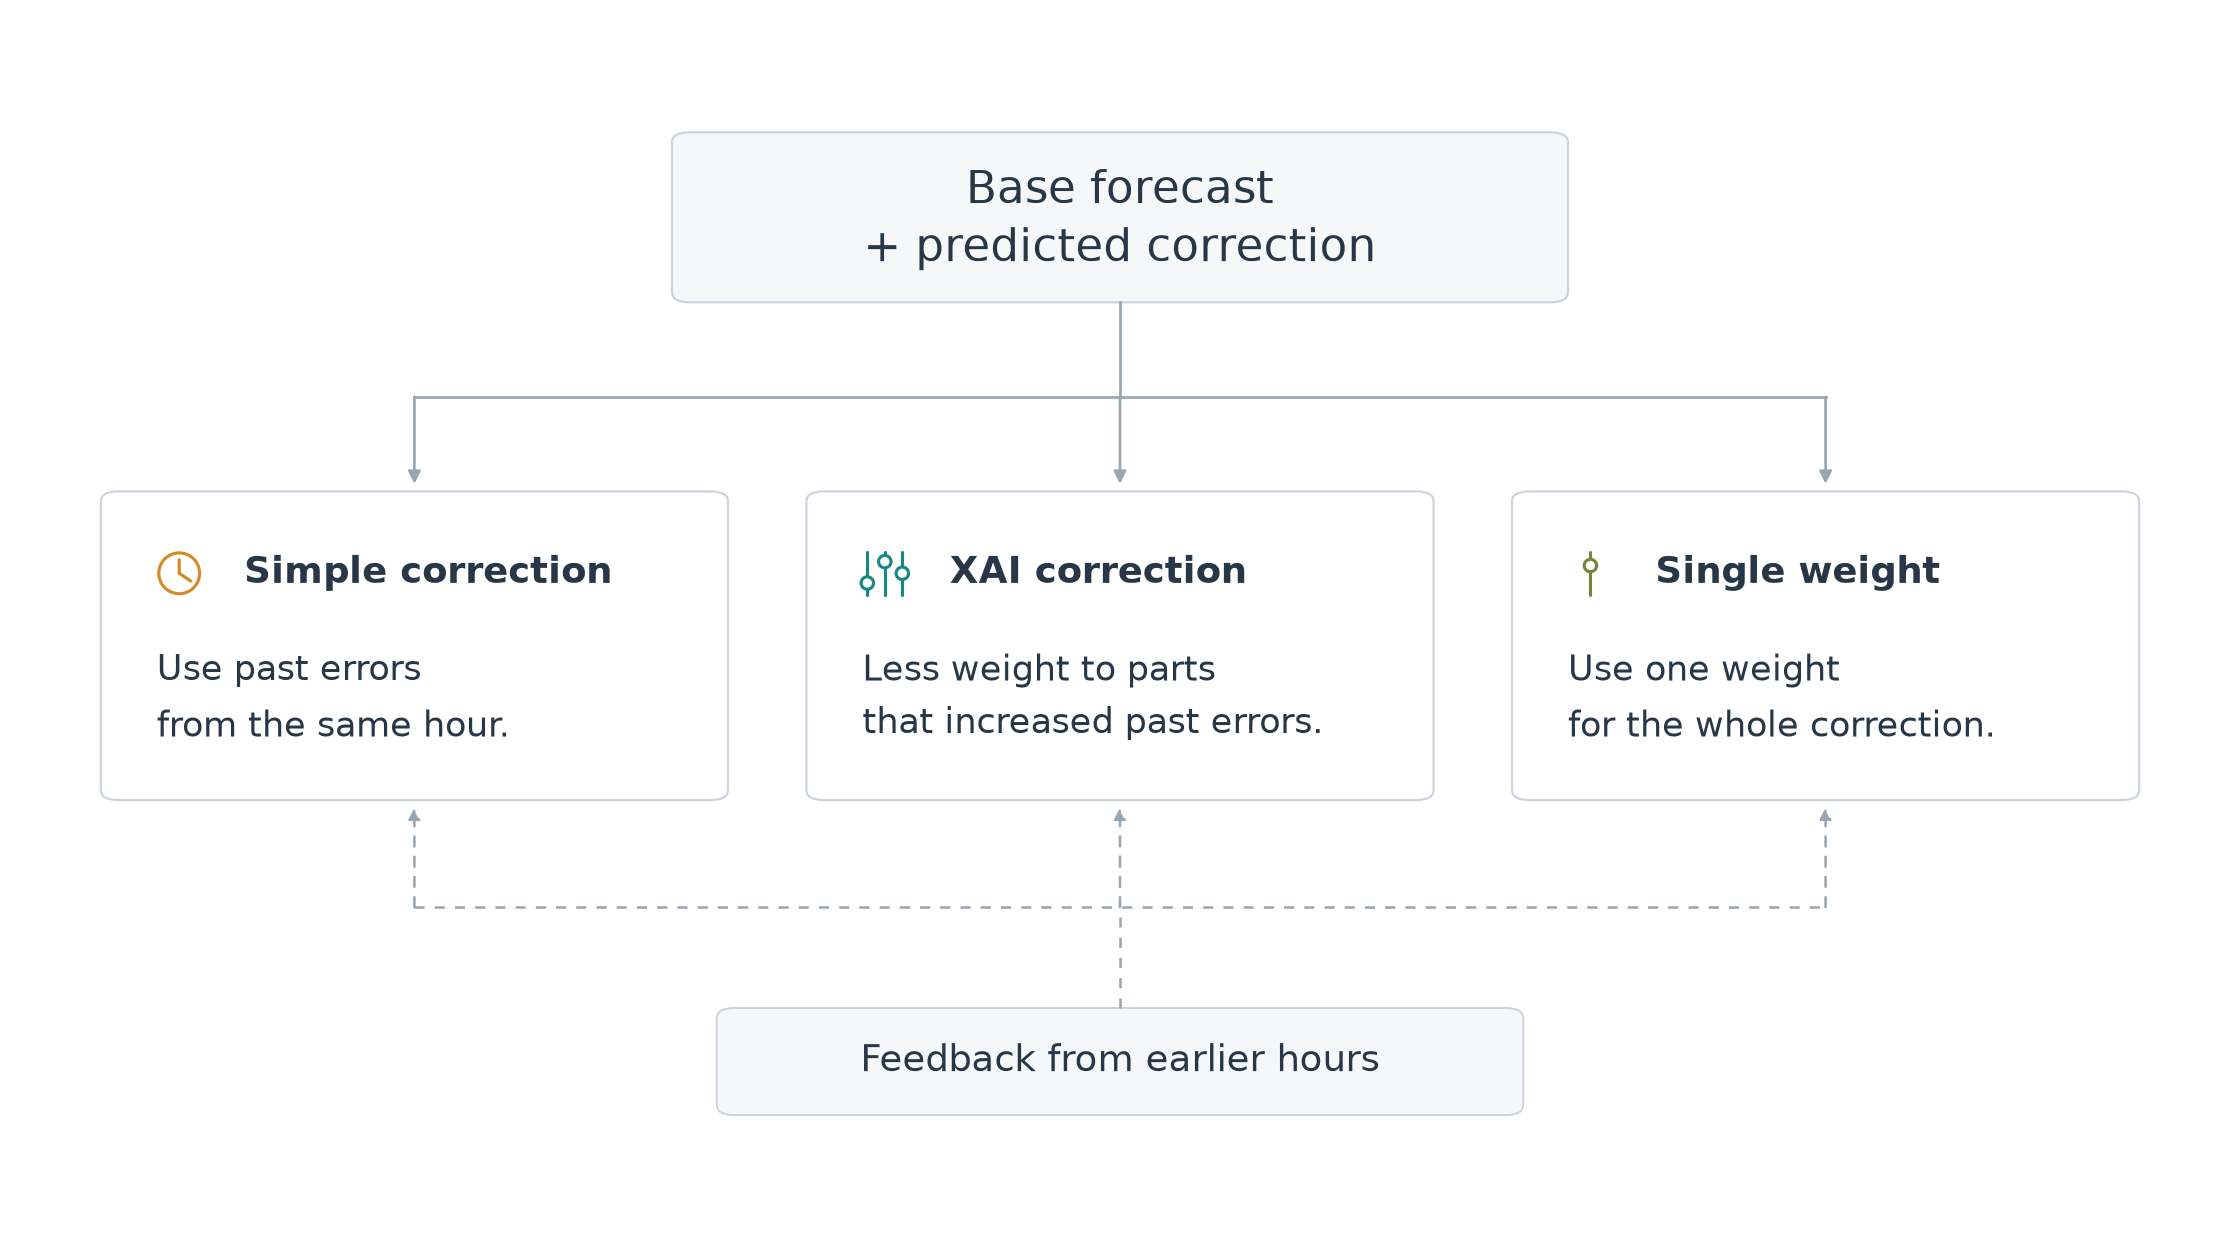

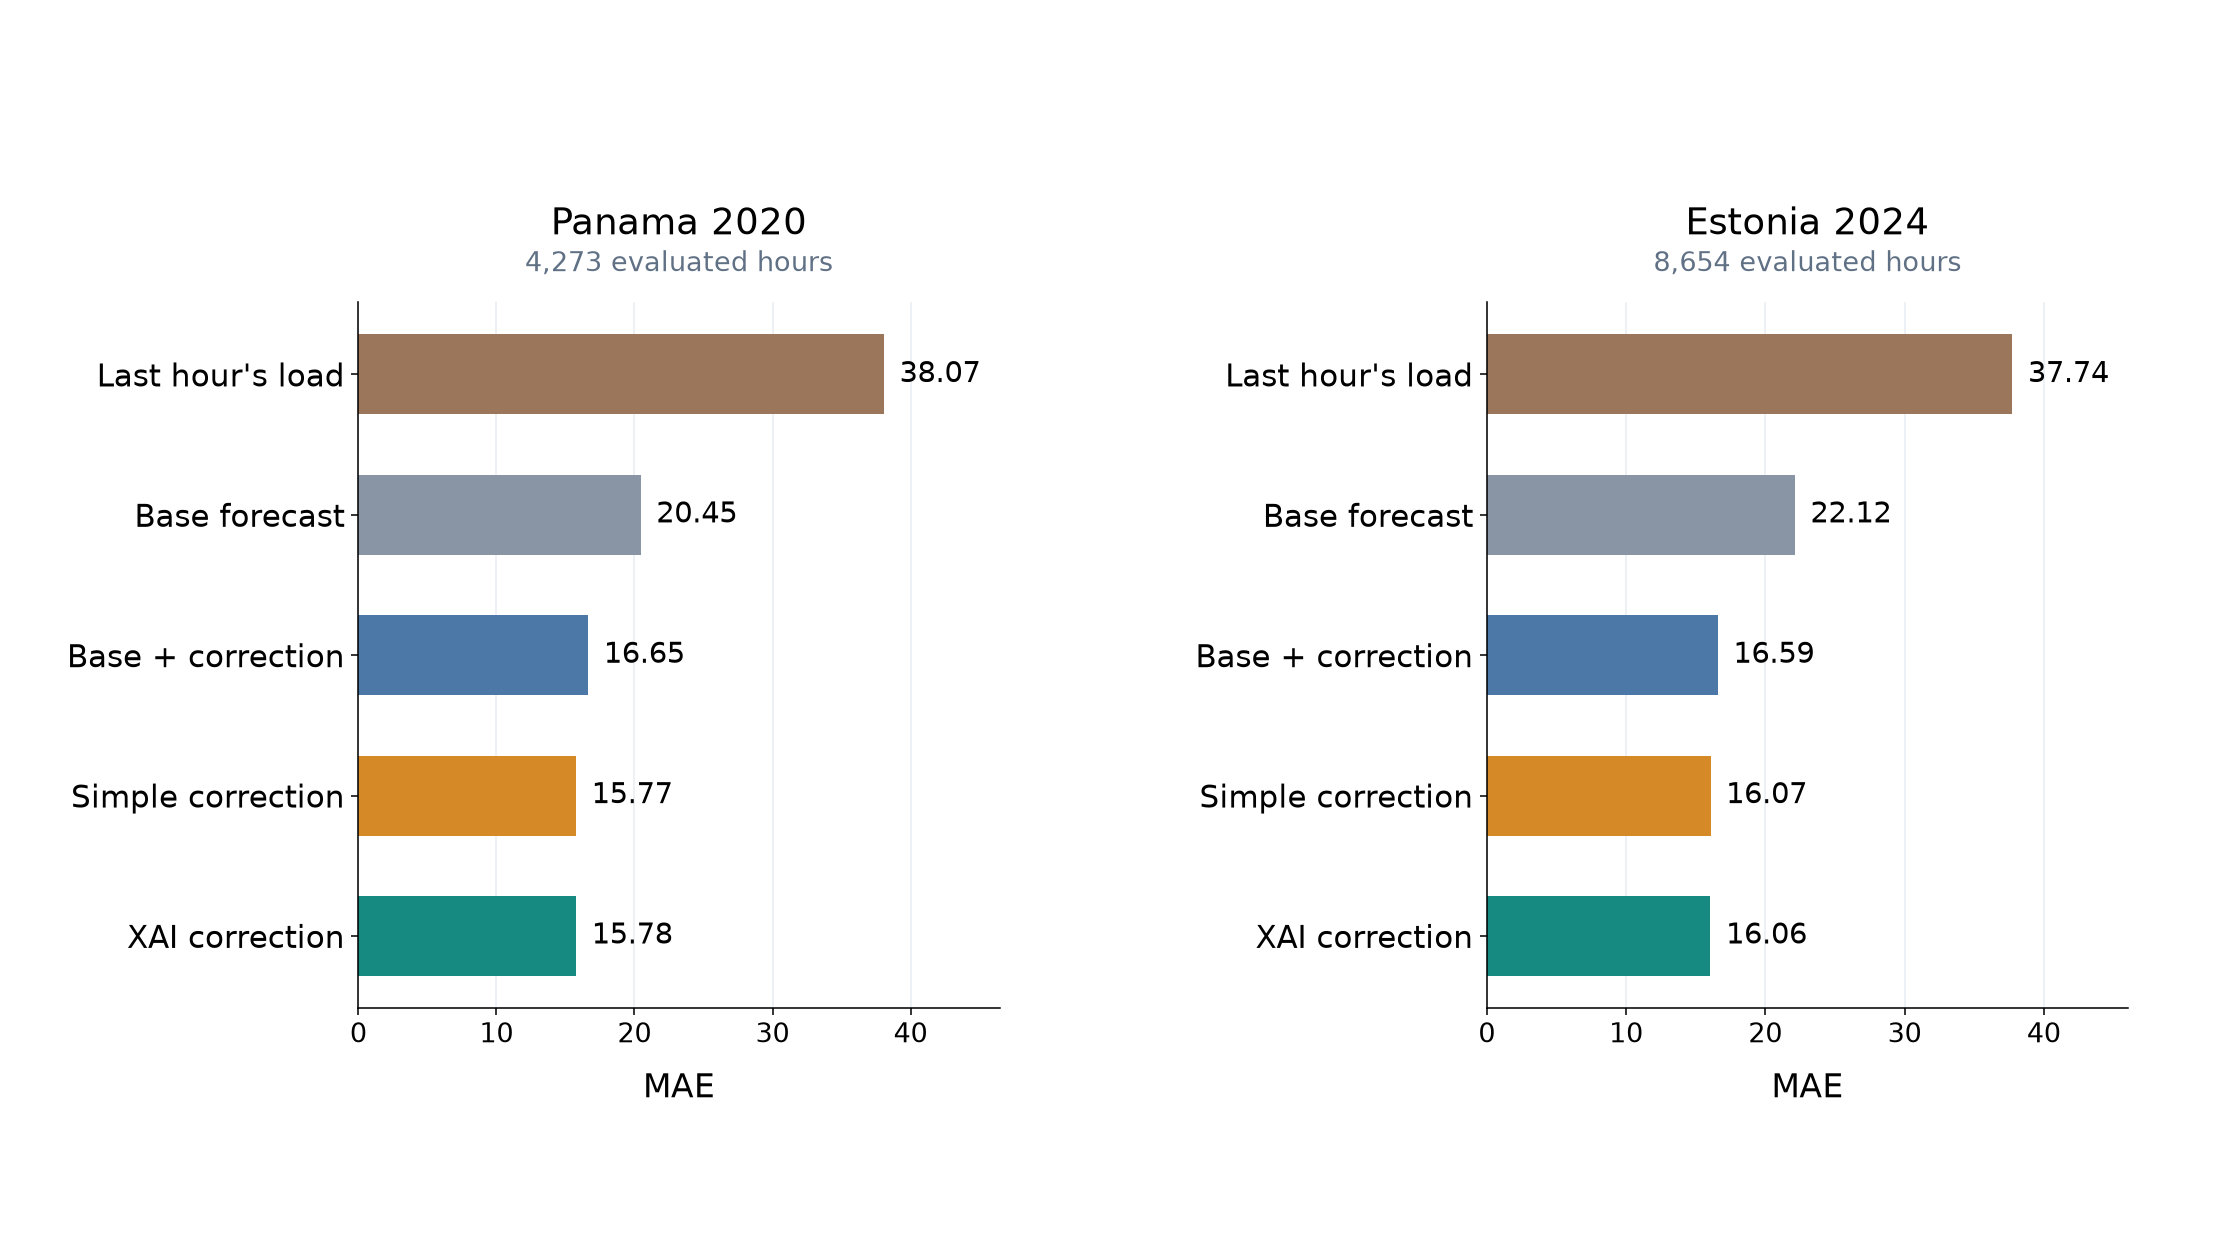

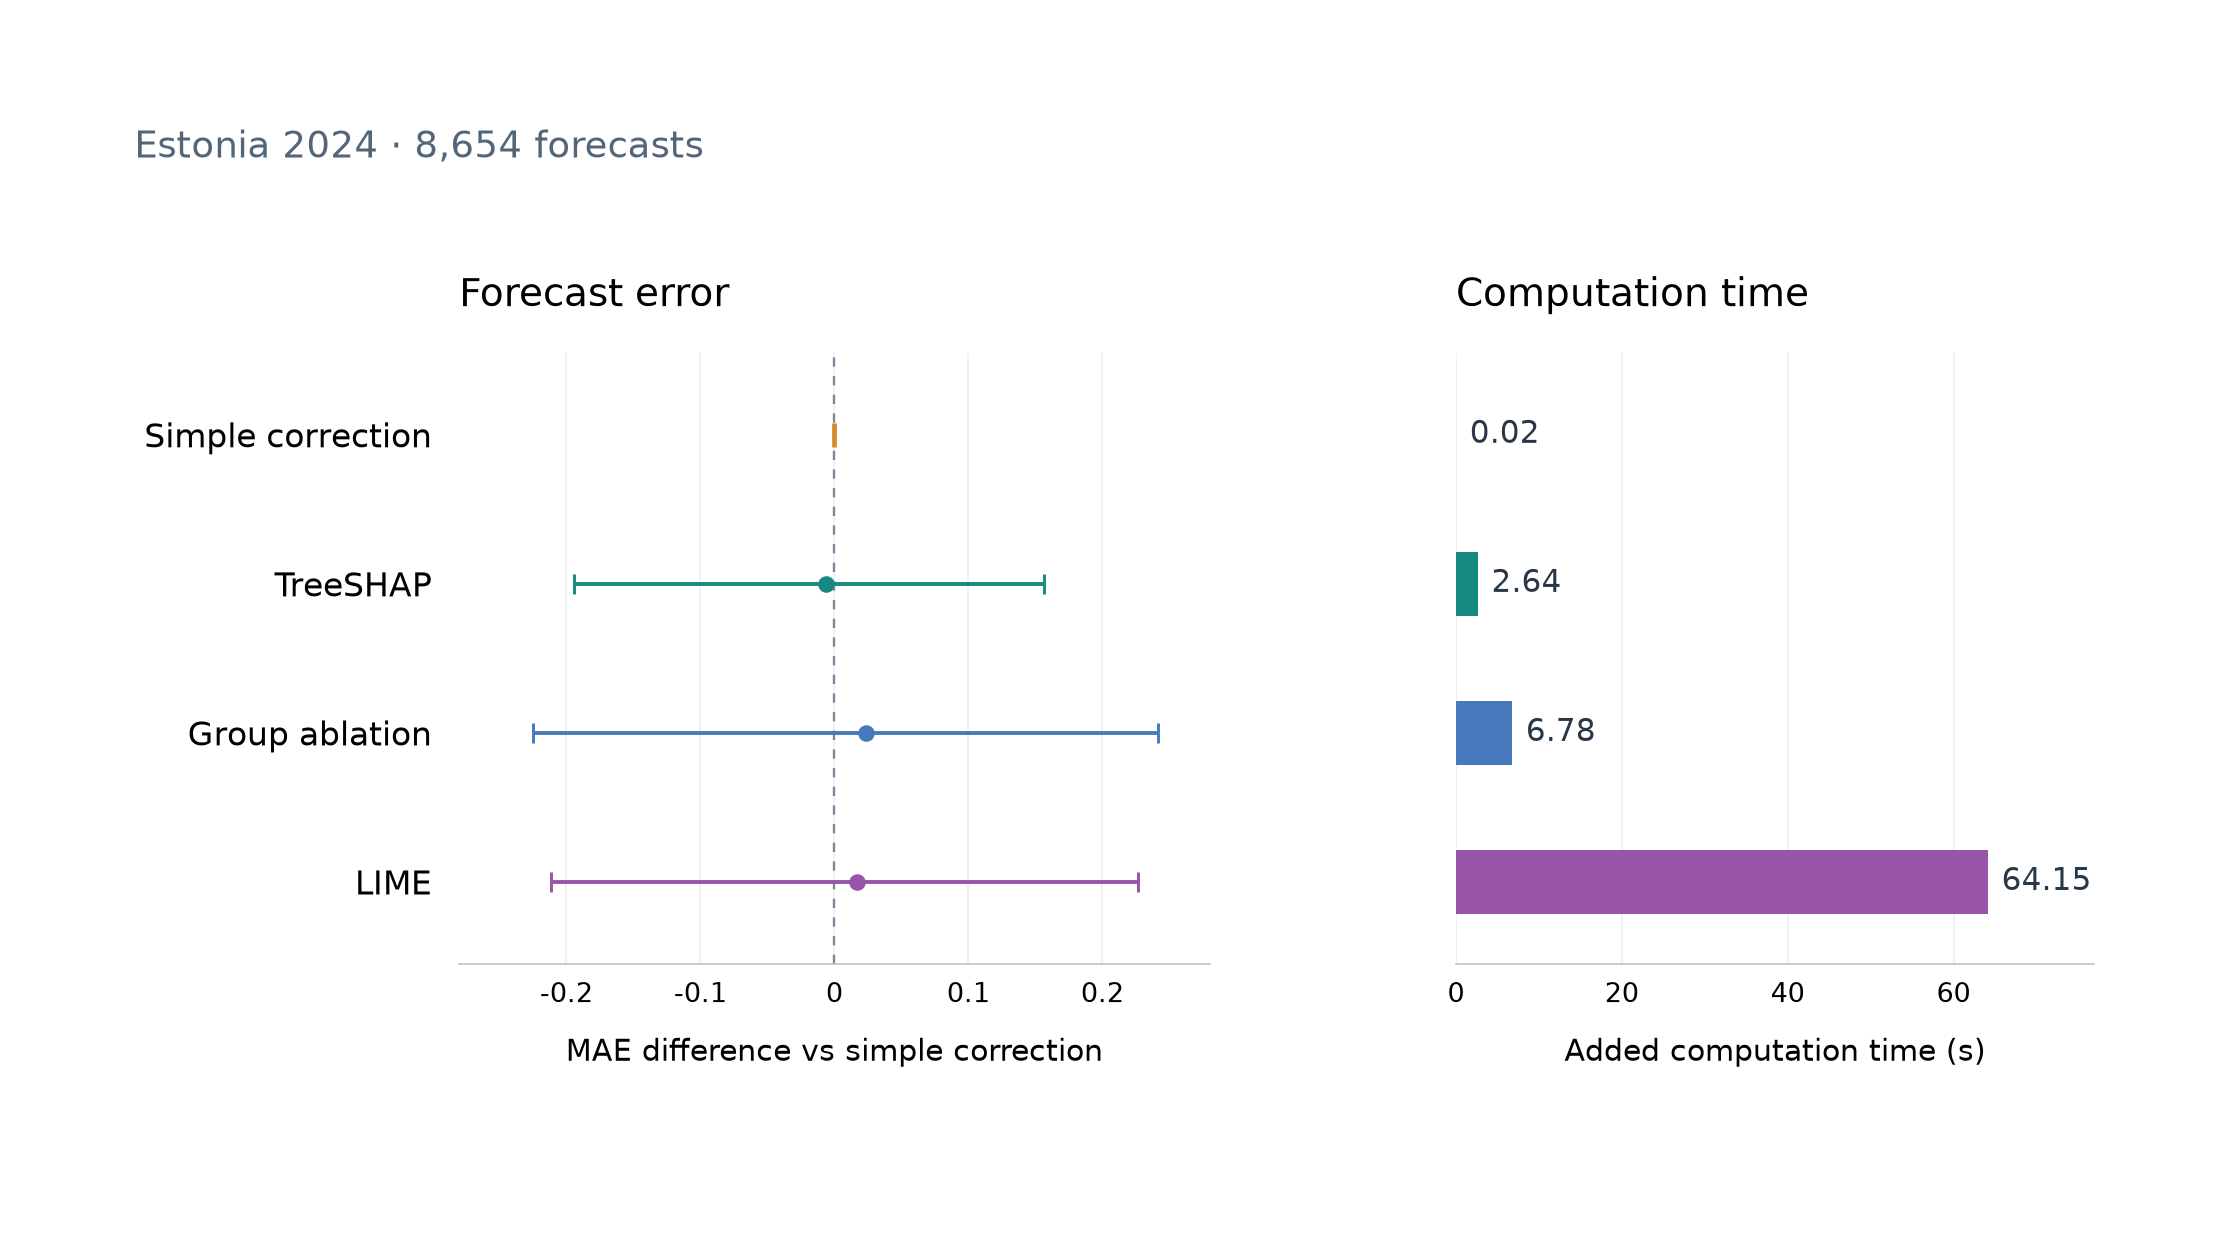

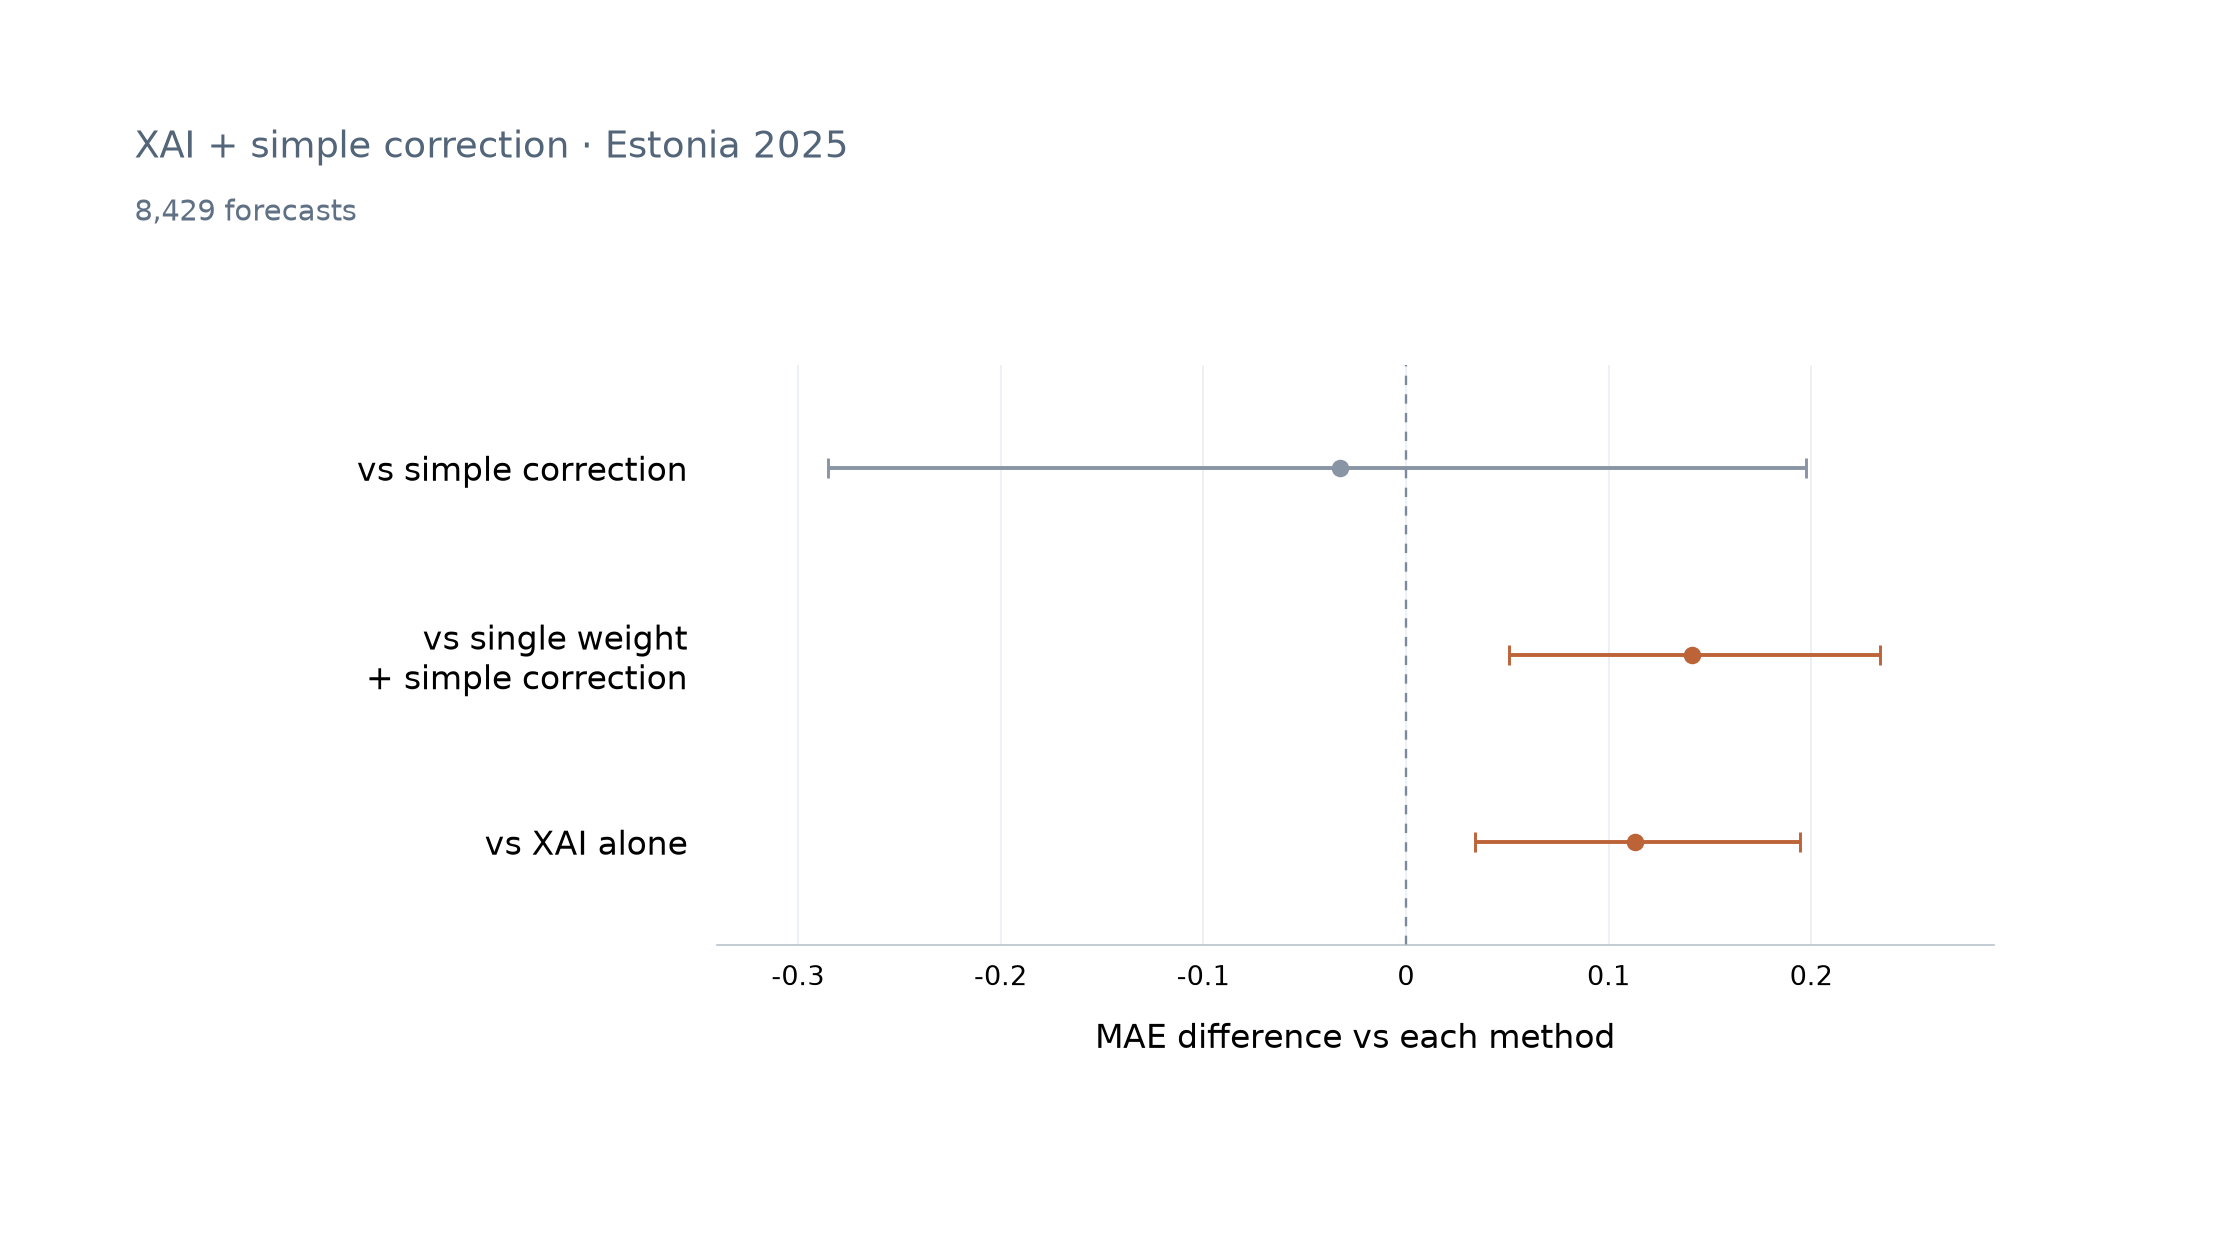

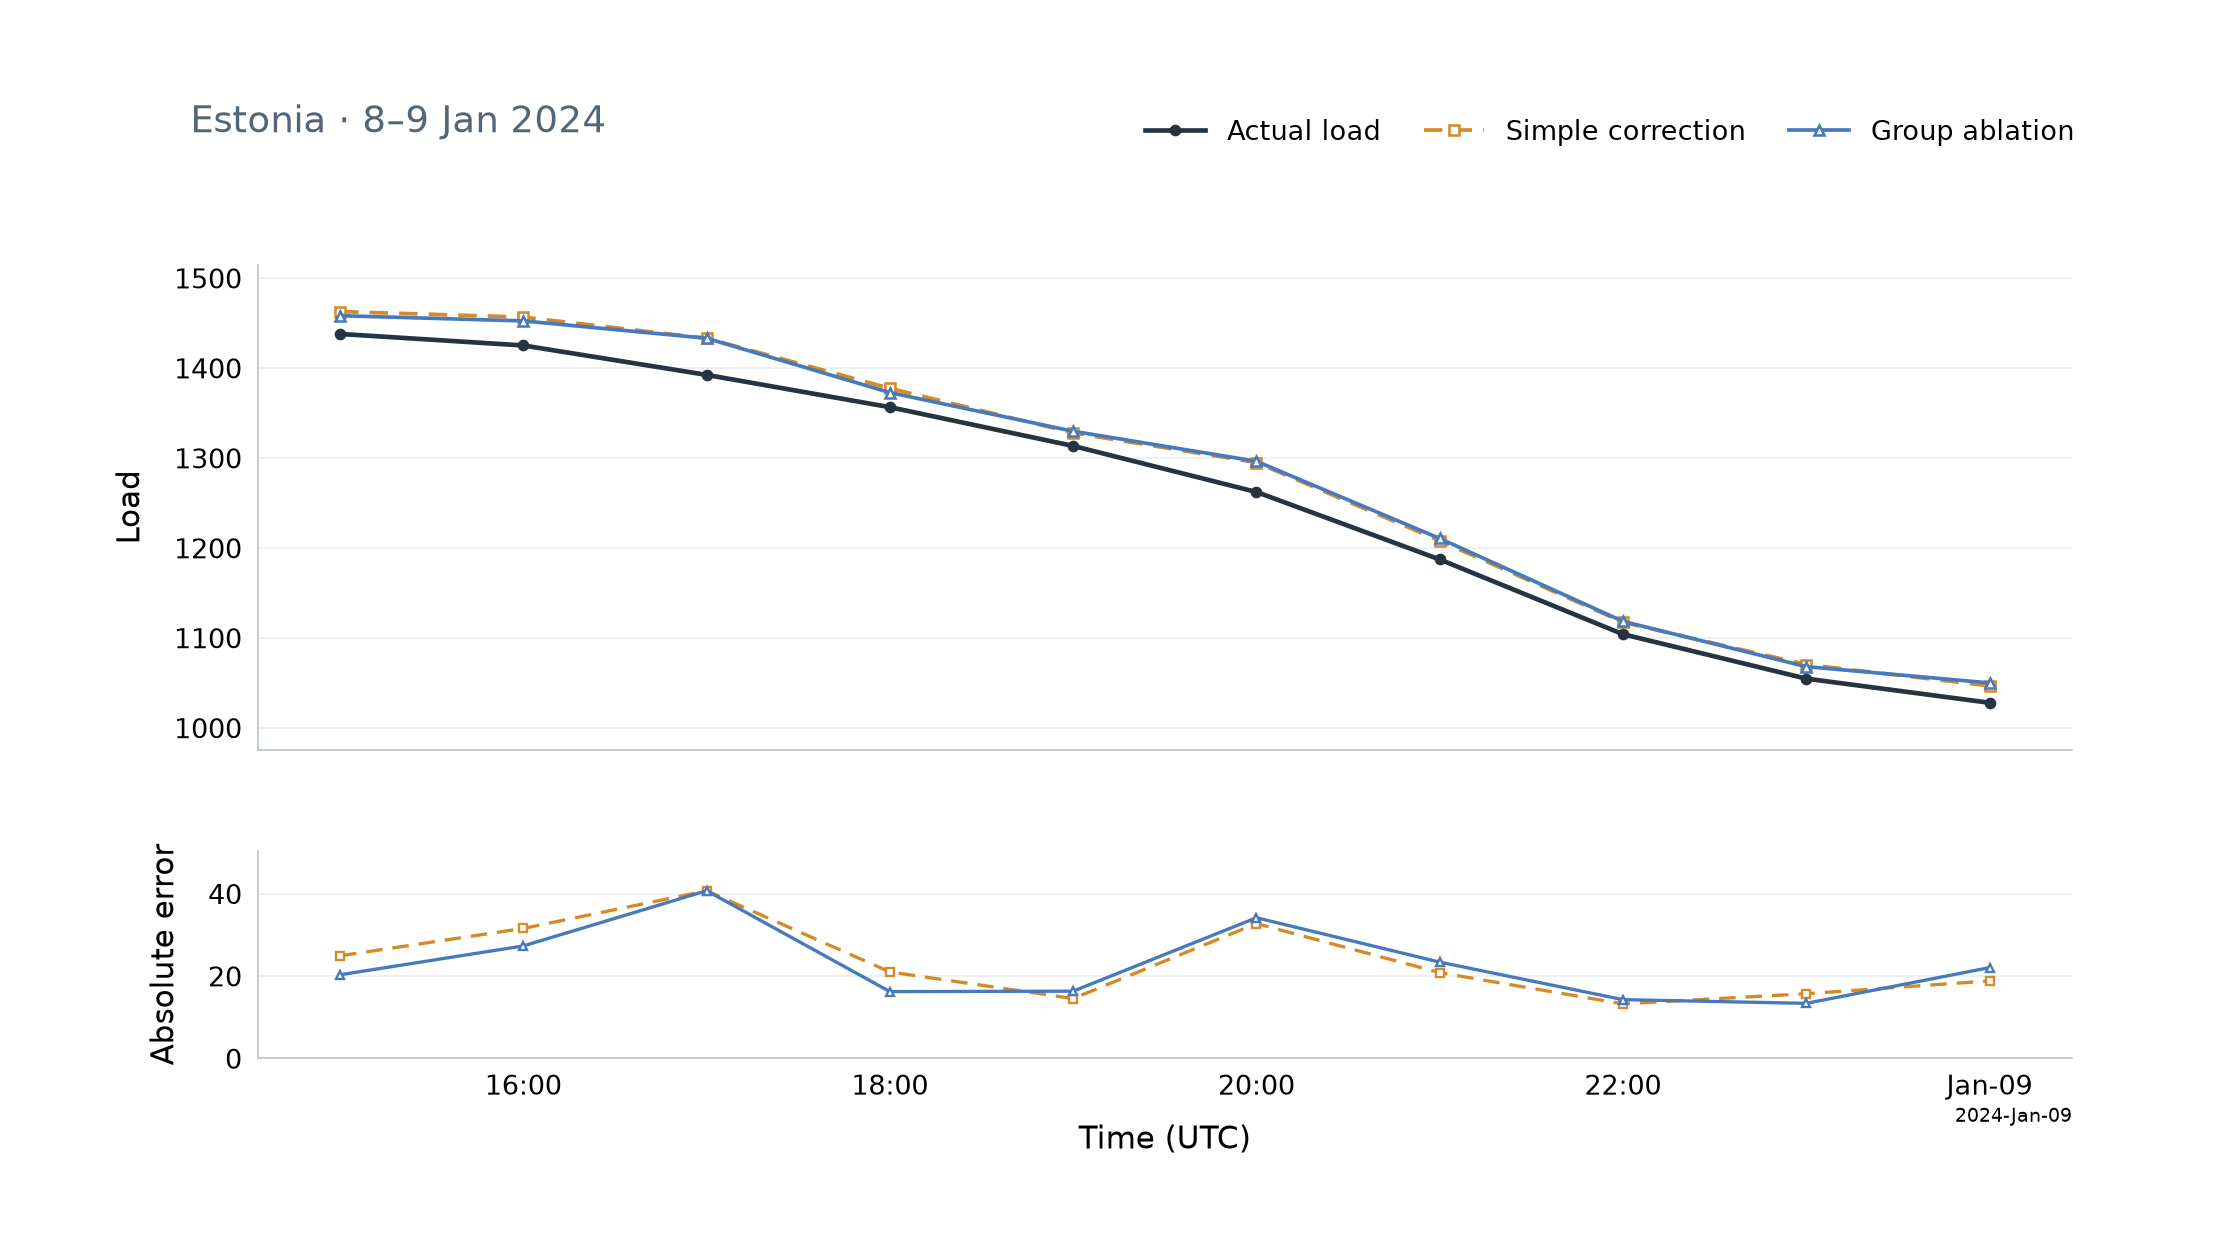

In [36]:
# Presentation visuals only: reuse the results above; do not train or select models.
from matplotlib.patches import FancyBboxPatch

presentation_figures = {}
p_colors = {"naive":"#9b765b", "base":"#8995a5", "residual":"#4c78a8", "hourly_bias":"#d58a27",
            "credit_feedback":"#168a80", "matched_scalar":"#788437", "xai_bias":"#9754a8", "scalar_bias":"#4779bd",
            "tree_shap":"#168a80", "lime":"#9754a8", "feature_ablation":"#4779bd"}
p_labels = {"naive":"Last observed load", "base":"Base model", "residual":"Residual model", "hourly_bias":"Simple correction",
            "credit_feedback":"XAI weights", "matched_scalar":"Single weight", "tree_shap":"TreeSHAP",
            "lime":"LIME", "feature_ablation":"Group ablation", "scalar_bias":"Single weight + simple correction"}

def presentation_frame(subtitle=""):
    fig = plt.figure(figsize=(16, 9), facecolor="white")
    if subtitle:
        fig.text(0.06, 0.86, subtitle, fontsize=17, color="#536579")
    return fig

def presentation_bars(ax, labels, values, colors, digits=4):
    bars = ax.barh(labels, values, color=colors, height=0.57)
    ax.bar_label(bars, labels=[f"{v:.{digits}f}" for v in values], padding=8, fontsize=15)
    ax.invert_yaxis()
    ax.set_xlim(0, max(values)*1.22)
    ax.set_xlabel("MAE")
    ax.grid(axis="x", color="#e8edf1", linewidth=0.8)
    ax.set_axisbelow(True)

with plt.rc_context({"figure.dpi":140, "font.size":16, "axes.titlesize":19, "axes.labelsize":17,
                     "xtick.labelsize":14, "ytick.labelsize":16,
                     "axes.spines.top":False, "axes.spines.right":False}):
    # Slide 2: separate development evaluation years, expanding prior training data.
    values = preliminary.sort_values("MAE")
    selected = {"histgbr":"HistGBR", "gbr":"GBR"}.get(cfg["base_model_family"], cfg["base_model_family"])
    years = cfg["datasets"]["panama"]["development_years"]
    fig = presentation_frame("Panama")
    axes = fig.subplots(1, len(years), sharex=True, squeeze=False)[0]
    fig.subplots_adjust(left=0.17, right=0.96, bottom=0.19, top=0.76, wspace=0.65)
    names = values.model.replace({"RandomForest":"Random Forest"})
    maximum = values[[f"MAE_{year}" for year in years]].max().max()
    for ax, year in zip(axes, years):
        presentation_bars(ax, names, values[f"MAE_{year}"],
                          [p_colors["tree_shap"] if m==selected else p_colors["base"] for m in values.model], digits=2)
        ax.set_xlim(0, maximum*1.22)
        ax.set_title(str(year), pad=18)
    presentation_figures["slide_2_base_models"] = fig
    plt.show()

    # Slide 3: a shared forecast, three alternative corrections, past feedback.
    from matplotlib.offsetbox import AnnotationBbox, DrawingArea
    from matplotlib.lines import Line2D
    from matplotlib.patches import Circle

    fig = plt.figure(figsize=(16, 9), facecolor='white')
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set(xlim=(0, 1), ylim=(0, 1))
    ax.axis('off')
    ink, line = '#283747', '#98a5b3'

    # Simple vector icons distinguish same-hour memory, separate weights and one weight.
    def workflow_icon(kind, color):
        drawing = DrawingArea(30, 30, 0, 0)
        def stroke(xs, ys):
            drawing.add_artist(Line2D(xs, ys, color=color, linewidth=1.6,
                                      solid_capstyle='round'))
        if kind == 'clock':
            drawing.add_artist(Circle((15, 15), 10.5, fill=False,
                                       edgecolor=color, linewidth=1.6))
            stroke([15, 15, 21], [22, 15, 11])
        else:
            positions = [(6, 10), (15, 21), (24, 15)] if kind == 'parts' else [(15, 19)]
            for x, y in positions:
                stroke([x, x], [4, 26])
                drawing.add_artist(Circle((x, y), 3.2, facecolor='white',
                                           edgecolor=color, linewidth=1.6))
        return drawing

    # One short input label; no repeated heading or decorative badges.
    ax.add_patch(FancyBboxPatch((0.300, 0.760), 0.400, 0.135,
        boxstyle='round,pad=0,rounding_size=0.008', facecolor='#f5f7f9',
        edgecolor='#cbd3dc', linewidth=1.1))
    ax.text(0.5, 0.8275, 'Base forecast\n+ predicted correction',
            ha='center', va='center', fontsize=23, color=ink, linespacing=1.4)

    centers = (0.185, 0.5, 0.815)
    ax.plot([0.5, 0.5], [0.760, 0.685], color=line, linewidth=1.4)
    ax.plot([centers[0], centers[-1]], [0.685, 0.685], color=line, linewidth=1.4)

    cards = [
        ('Simple correction', 'Use past errors\nfrom the same hour.',
         'clock', p_colors['hourly_bias']),
        ('XAI correction', 'Less weight to parts\nthat increased past errors.',
         'parts', p_colors['credit_feedback']),
        ('Single weight', 'Use one weight\nfor the whole correction.',
         'single', p_colors['matched_scalar']),
    ]
    for center, (heading, detail, icon, color) in zip(centers, cards):
        x, y, width, height = center - 0.14, 0.365, 0.28, 0.245
        ax.annotate('', xy=(center, y + height + 0.006), xytext=(center, 0.685),
            arrowprops={'arrowstyle': '-|>', 'color': line, 'lw': 1.4,
                        'mutation_scale': 13, 'shrinkA': 0, 'shrinkB': 0})
        ax.add_patch(FancyBboxPatch((x, y), width, height,
            boxstyle='round,pad=0,rounding_size=0.008',
            facecolor='white', edgecolor='#cbd3dc', linewidth=1.1))
        ax.add_artist(AnnotationBbox(workflow_icon(icon, color),
            (x + 0.035, y + 0.180), frameon=False, pad=0))
        ax.text(x + 0.064, y + 0.180, heading, ha='left', va='center',
                fontsize=19, weight='bold', color=ink)
        ax.text(x + 0.025, y + 0.082, detail, ha='left', va='center',
                fontsize=18, color=ink, linespacing=1.5)

    # Past errors feed each method; dashed lines distinguish feedback from the input.
    feedback_style = (0, (4, 4))
    ax.plot([0.5, 0.5], [0.200, 0.280], color=line, linewidth=1.3,
            linestyle=feedback_style)
    ax.plot([centers[0], centers[-1]], [0.280, 0.280], color=line,
            linewidth=1.3, linestyle=feedback_style)
    for center in centers:
        ax.annotate('', xy=(center, 0.359), xytext=(center, 0.280),
            arrowprops={'arrowstyle': '-|>', 'color': line, 'lw': 1.3,
                        'linestyle': feedback_style, 'mutation_scale': 12,
                        'shrinkA': 0, 'shrinkB': 0})
    ax.add_patch(FancyBboxPatch((0.320, 0.115), 0.360, 0.085,
        boxstyle='round,pad=0,rounding_size=0.008',
        facecolor='#f5f7f9', edgecolor='#cbd3dc', linewidth=1.0))
    ax.text(0.5, 0.1575, 'Feedback from earlier hours', ha='center', va='center',
            fontsize=19, color=ink)

    presentation_figures['slide_3_correction_rules'] = fig
    plt.show()

    # Slide 4: keep both datasets separate and show the full error scale.
    methods = ['naive', 'base', 'residual', 'hourly_bias', 'credit_feedback']
    slide4_labels = ["Last hour's load", 'Base forecast', 'Base + correction',
                     'Simple correction', 'XAI correction']
    fig = presentation_frame()
    axes = fig.subplots(1, 2)
    fig.subplots_adjust(left=0.16, right=0.95, bottom=0.20, top=0.76, wspace=0.76)
    for ax, dataset, country in zip(axes, DATASETS, ['Panama', 'Estonia']):
        values = overall[overall.dataset.eq(dataset)].set_index('method').loc[methods]
        assert values.n.nunique() == 1
        presentation_bars(ax, slide4_labels, values.MAE,
                          [p_colors[m] for m in methods], digits=2)
        ax.set_title(f"{country} {cfg['datasets'][dataset]['test_year']}", pad=35)
        ax.text(0.5, 1.035, f"{int(values.n.iloc[0]):,} evaluated hours",
                transform=ax.transAxes, ha='center', va='bottom',
                fontsize=14, color='#607185')
        ax.set_xlabel('MAE', labelpad=12)
    presentation_figures['slide_4_overall_error'] = fig
    plt.show()

    # Slide 5: align accuracy and added batch computation on the same method rows.
    from matplotlib.ticker import FuncFormatter

    methods = ['hourly_bias', 'tree_shap', 'feature_ablation', 'lime']
    labels = ['Simple correction', 'TreeSHAP', 'Group ablation', 'LIME']
    timing = xai_timing[xai_timing.dataset.eq('estonia')].set_index('method').loc[methods]
    differences = xai_primary_intervals[
        xai_primary_intervals.dataset.eq('estonia')
        & xai_primary_intervals.scope.eq('overall')
        & xai_primary_intervals.B.eq('hourly_bias')
    ].set_index('A').loc[methods[1:]]
    assert timing.n.nunique() == 1
    assert differences.n.eq(timing.n.iloc[0]).all()

    fig = plt.figure(figsize=(16, 9), facecolor='white')
    fig.text(0.06, 0.875, f"Estonia 2024 · {int(timing.n.iloc[0]):,} forecasts",
             fontsize=19, color='#536579')
    accuracy_ax = fig.add_axes([0.205, 0.235, 0.335, 0.485])
    time_ax = fig.add_axes([0.65, 0.235, 0.285, 0.485], sharey=accuracy_ax)

    for position, method in enumerate(methods):
        color = p_colors[method]
        if method == 'hourly_bias':
            # Zero is the definition of the reference, not an uncertainty estimate.
            accuracy_ax.scatter(0, position, marker='|', s=160, color=color,
                                linewidths=2.4, zorder=4)
        else:
            row = differences.loc[method]
            assert row.adjusted_low <= row.difference <= row.adjusted_high
            accuracy_ax.errorbar(float(row.difference), position,
                xerr=[[float(row.difference - row.adjusted_low)],
                      [float(row.adjusted_high - row.difference)]],
                fmt='o', color=color, markersize=7.5, elinewidth=2,
                capsize=5, capthick=1.5, zorder=3)
        seconds = float(timing.loc[method, 'total_seconds'])
        time_ax.barh(position, seconds, color=color, height=0.43, zorder=3)
        time_ax.annotate(f'{seconds:.2f}', (seconds, position),
                         xytext=(7, 0), textcoords='offset points',
                         ha='left', va='center', fontsize=16, color='#283747')

    accuracy_ax.axvline(0, color='#7c8998', linestyle=(0, (4, 4)), linewidth=1.2)
    accuracy_ax.set_yticks(range(len(methods)), labels)
    accuracy_ax.tick_params(axis='y', length=0, pad=14, labelsize=17)
    accuracy_ax.set(xlim=(-0.28, 0.28), ylim=(3.55, -0.55))
    accuracy_ax.set_xticks([-0.2, -0.1, 0, 0.1, 0.2])
    accuracy_ax.xaxis.set_major_formatter(FuncFormatter(
        lambda value, position: '0' if abs(value) < 1e-12 else f'{value:.1f}'))
    accuracy_ax.set_xlabel('MAE difference vs simple correction', fontsize=15.5, labelpad=15)
    accuracy_ax.set_title('Forecast error', fontsize=20, pad=24, loc='left')

    time_ax.set_xlim(0, float(timing.total_seconds.max()) * 1.20)
    time_ax.set_xticks([0, 20, 40, 60])
    time_ax.tick_params(axis='y', left=False, labelleft=False)
    time_ax.set_xlabel('Added computation time (s)', fontsize=15.5, labelpad=15)
    time_ax.set_title('Computation time', fontsize=20, pad=24, loc='left')
    for axis in (accuracy_ax, time_ax):
        axis.grid(axis='x', color='#e8edf1', linewidth=0.8)
        axis.set_axisbelow(True)
        axis.spines[['top', 'right', 'left']].set_visible(False)
        axis.spines['bottom'].set_color('#b4bec9')
        axis.tick_params(axis='x', length=0, pad=9, labelsize=14)

    presentation_figures['slide_5_accuracy_and_time'] = fig
    plt.show()

    # Slide 6: preserve the planned contrasts and their adjusted uncertainty intervals.
    from matplotlib.ticker import FuncFormatter
    methods = ['hourly_bias', 'scalar_bias', 'credit_feedback']
    values = combined_primary_intervals[
        combined_primary_intervals.scope.eq('overall')
        & combined_primary_intervals.A.eq('xai_bias')
    ].set_index('B').loc[methods]
    assert values.n.nunique() == 1
    fig = plt.figure(figsize=(16, 9), facecolor='white')
    fig.text(0.06, 0.875, 'XAI + simple correction · Estonia 2025',
             fontsize=19, color='#536579')
    fig.text(0.06, 0.825, f"{int(values.n.iloc[0]):,} forecasts", fontsize=15, color='#607185')
    ax = fig.add_axes([0.32, 0.25, 0.57, 0.46])
    for position, row in enumerate(values.itertuples()):
        color = '#bd6338' if row.adjusted_low > 0 else '#8995a5'
        ax.errorbar(float(row.difference), position,
            xerr=[[float(row.difference - row.adjusted_low)],
                  [float(row.adjusted_high - row.difference)]],
            fmt='o', color=color, markersize=8, elinewidth=2,
            capsize=5, capthick=1.5, zorder=3)
    ax.axvline(0, color='#7c8998', linestyle=(0, (4, 4)), linewidth=1.2)
    ax.set_yticks(range(len(methods)),
        ['vs simple correction', 'vs single weight\n+ simple correction', 'vs XAI alone'])
    ax.set(xlim=(-0.34, 0.29), ylim=(2.55, -0.55))
    ax.set_xticks([-0.3, -0.2, -0.1, 0, 0.1, 0.2])
    ax.xaxis.set_major_formatter(FuncFormatter(
        lambda value, position: '0' if abs(value) < 1e-12 else f'{value:.1f}'))
    ax.set_xlabel('MAE difference vs each method', fontsize=17, labelpad=16)
    ax.tick_params(axis='y', length=0, pad=15, labelsize=17)
    ax.tick_params(axis='x', length=0, pad=10, labelsize=14)
    ax.grid(axis='x', color='#e8edf1', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#b4bec9')
    presentation_figures['slide_6_combined_correction'] = fig
    plt.show()

    # Slide 7: compare existing one-hour forecasts in the same fixed example window.
    # Select the first rapid decrease after seven days, independently of forecast errors.
    from matplotlib.dates import AutoDateLocator, ConciseDateFormatter

    example_frame = runs['estonia']['frame']
    rapid = example_frame.actual_ramp.le(runs['estonia']['thresholds']['decrease'])
    eligible = rapid & example_frame.target_time.ge(
        example_frame.target_time.min() + pd.Timedelta(days=7))
    assert eligible.any()
    example = example_frame.loc[eligible].iloc[0]
    window = example_frame.target_time.between(
        example.origin_time - pd.Timedelta(hours=5),
        example.target_time + pd.Timedelta(hours=3))
    times = example_frame.loc[window, 'target_time']
    actual = example_frame.loc[window, 'target_next_hour'].to_numpy()
    simple = np.asarray(xai_runs['estonia']['forecasts']['hourly_bias'])[window]
    ablation = np.asarray(xai_runs['estonia']['forecasts']['feature_ablation'])[window]
    assert len(times) == len(actual) == len(simple) == len(ablation)

    fig = plt.figure(figsize=(16, 9), facecolor='white')
    first_date, last_date = times.iloc[0], times.iloc[-1]
    if first_date.date() == last_date.date():
        date_label = first_date.strftime('%d %b %Y').lstrip('0')
    elif first_date.month == last_date.month:
        date_label = f"{first_date.day}–{last_date.day} {last_date:%b %Y}"
    else:
        date_label = f"{first_date:%d %b}–{last_date:%d %b %Y}"
    fig.text(0.085, 0.895, f'Estonia · {date_label}', fontsize=19, color='#536579')
    load_ax = fig.add_axes([0.115, 0.405, 0.81, 0.385])
    error_ax = fig.add_axes([0.115, 0.16, 0.81, 0.165], sharex=load_ax)

    load_ax.plot(times, actual, color='#263442', linewidth=2.4,
                  marker='o', markersize=5, label='Actual load', zorder=4)
    styles = [
        (simple, 'Simple correction', p_colors['hourly_bias'], (0, (5, 3)), 's'),
        (ablation, 'Group ablation', p_colors['feature_ablation'], '-', '^'),
    ]
    for prediction, label, color, style, marker in styles:
        load_ax.plot(times, prediction, color=color, linewidth=1.9, linestyle=style,
                     marker=marker, markersize=5, markerfacecolor='white',
                     markeredgewidth=1.3, label=label, zorder=3)
        error_ax.plot(times, np.abs(prediction - actual), color=color,
                      linewidth=1.7, linestyle=style, marker=marker,
                      markersize=4.5, markerfacecolor='white', markeredgewidth=1.2)

    fig.legend(*load_ax.get_legend_handles_labels(), loc='upper right',
                bbox_to_anchor=(0.937, 0.925), ncol=3, frameon=False,
                fontsize=14, columnspacing=1.6, handlelength=2.2)
    load_ax.set_ylabel('Load', fontsize=16, labelpad=14)
    error_ax.set_ylabel('Absolute error', fontsize=16, labelpad=14)
    error_ax.set_xlabel('Time (UTC)', fontsize=16, labelpad=12)
    load_ax.tick_params(axis='x', bottom=False, labelbottom=False)
    load_ax.margins(x=0.02, y=0.12)
    error_ax.set_ylim(0, max(np.abs(simple - actual).max(), np.abs(ablation - actual).max()) * 1.24)
    error_ax.set_yticks([0, 20, 40])
    locator = AutoDateLocator(minticks=5, maxticks=8)
    error_ax.xaxis.set_major_locator(locator)
    error_ax.xaxis.set_major_formatter(ConciseDateFormatter(locator))
    for axis in (load_ax, error_ax):
        axis.grid(axis='y', color='#e8edf1', linewidth=0.8)
        axis.set_axisbelow(True)
        axis.tick_params(axis='both', labelsize=14, length=0, pad=8)
        axis.spines[['top', 'right']].set_visible(False)
        for side in ('left', 'bottom'):
            axis.spines[side].set_color('#b4bec9')
    presentation_figures['slide_7_rapid_decreases'] = fig
    plt.show()

